# ██ PERSONAS DESDE LAS CARAS INTERMEDIAS ██
Fase 3 del plan de datos. Por cada cara LEGO intermedia (las que generó `intermedias_produccion`) se generan
**2 personas** con FLUX.2 klein, igual que en g1: así cada intermedia queda como par (foto, cara LEGO) para
entrenar el Flow 1.

**Reparto entre 5.** La lista de caras es la misma para todos (orden barajado con la semilla 42) y la cara k
le toca a la persona `k % 5 + 1`. **Lo único que cambia cada uno es `PERSONA`** (1 a 5) en la configuración.
Con `PERSONA=0` una sola cuenta corre todo.

**Inputs en Kaggle:** `LegosPartsVae` y un dataset con el contenido de `intermedias_todas.zip` (la carpeta
con `dataset/` y `dataset.csv`). GPU T4 ×2 e Internet. Correr con *Save Version → Save & Run All*.

**Cuánto tarda:** unas 407 caras × 2 = 815 fotos por persona, cerca de 2 horas. Si se corta, al volver a
correrlo salta las que ya están (o agrega el output anterior como input y las recupera).

**Al terminar:** `personas_int_persona{PERSONA}.zip` con `imagenes/`, las hojas y `revision.csv`. Como en g1,
en `revision.csv` se pone **1 en `falla`** si la foto no respeta la cara LEGO (le falta o le sobra barba,
bigote, lentes, o cambia la expresión).

In [1]:
%pip install -q -U git+https://github.com/huggingface/diffusers transformers accelerate

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Note: you may need to restart the kernel to use updated packages.


In [2]:
import glob
import json
import os
import re
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image, ImageDraw

CONFIG = dict(
    PERSONA=1,                    # ← CAMBIAR: tu número, de 1 a 5 (0 = todas las caras en esta cuenta)
    N_PERSONAS=5,
    SEMILLA=42,                   # estándar del curso: el reparto, la demografía y las semillas de FLUX salen de aquí
    VERSION="gi",                 # g intermedias
    ESTADOS=("pasa", "dudosa"),   # qué intermedias se usan (todas las del dataset)
    MODELO="black-forest-labs/FLUX.2-klein-4B",
    PERSONAS_POR_CARA=2,
    LADO_ENTRADA=512,
    LADO_SALIDA=512,
    PASOS=4,
    GUIA=1.0,
    VER_CADA=25,                  # muestra cara LEGO | persona 1 | persona 2 cada tantas caras
    LIMITE_HORAS=11.3,
)
FALSO = bool(os.environ.get("GEN_FALSO"))
CONFIG["PERSONA"] = int(os.environ.get("PERSONA", CONFIG["PERSONA"]))
assert 0 <= CONFIG["PERSONA"] <= CONFIG["N_PERSONAS"], "PERSONA debe ser un entero de 0 a 5"
NOMBRE = "personas_int_todas" if CONFIG["PERSONA"] == 0 else f"personas_int_persona{CONFIG['PERSONA']}"
SALIDA = Path(os.environ.get("SALIDA_GEN", "/kaggle/working")) / NOMBRE
(SALIDA / "imagenes").mkdir(parents=True, exist_ok=True)
(SALIDA / "hojas").mkdir(exist_ok=True)
N_GPU = torch.cuda.device_count()
print("=" * 78)
print(f"  PERSONAS DESDE INTERMEDIAS · persona {CONFIG['PERSONA'] or 'todas'} de {CONFIG['N_PERSONAS']}"
      f"{'  |  MODO FALSO' if FALSO else ''}")
print(f"  GPUs: {N_GPU} {[torch.cuda.get_device_name(i) for i in range(N_GPU)]}")
print("=" * 78)


def buscar(patron, obligatorio=True):
    for raiz in ["/kaggle/input", *os.environ.get("ENTRADAS_GEN", "").split(":")]:
        if raiz:
            r = sorted(glob.glob(f"{raiz}/**/{patron}", recursive=True))
            if r:
                return Path(r[0])
    if obligatorio:
        raise FileNotFoundError(f"No encuentro {patron}: revisa los inputs del notebook")
    return None


def registrar_error(texto):
    with open(SALIDA / "errores.txt", "a") as f:
        f.write(texto + "\n")
    print("ERROR:", texto)

  PERSONAS DESDE INTERMEDIAS · persona 1 de 5
  GPUs: 2 ['Tesla T4', 'Tesla T4']


## 1. Rasgos escritos a mano (como en g2)
Las 2150 intermedias se revisaron una por una y sus rasgos se escribieron a mano en el estilo de g2, que fue
lo que mejor funcionó: cejas (color, forma), ojos (pestañas, blanco visible, color), boca (abierta o cerrada,
sonrisa, dientes, lengua, color de labios), vello facial (bigote, barba, perilla, patillas, color), lentes,
pecas, hoyuelo, arrugas y pelo cuando la estampa lo dibuja.

Formato de cada línea: `id|género|edad|rasgos`.
- **Género:** `m` (hombre, por vello facial), `w` (mujer, por pestañas largas o labios pintados), `-` (se sortea
  como en g1) o `x` (no humana: se excluye).
- **Edad:** `M` (mayor: vello o cejas grises o blancas, arrugas) o `-` (se sortea como en g1).

In [3]:
RASGOS_TXT = """
t00000|w|-|thin ginger eyebrows, long dark eyelashes, light pink lips in a gentle closed-mouth smile and large brown rectangular glasses
t00001|w|-|thin reddish brown arched eyebrows, long dark eyelashes and light pink lips in a gentle closed-mouth smile
t00002|-|-|thin ginger eyebrows, bright eyes with visible whites and a gentle closed-mouth smile
t00003|-|-|thick ginger eyebrows, wide open eyes with large whites and a wide closed-mouth smile
t00004|-|-|black eyebrows raised at the inner ends in a worried look and a small closed-mouth smile
t00005|-|-|black eyebrows raised at the inner ends in a worried look, a small closed-mouth smile and a small chin dimple
t00008|x|-|clown red nose
t00009|x|-|clown red nose
t00012|w|-|thick black arched eyebrows and full bright red lips, mouth closed
t00013|w|-|thick black arched eyebrows and full red lips slightly parted
t00014|w|-|thin black arched eyebrows, long dark eyelashes and natural lips in a gentle closed-mouth smile
t00015|-|-|black arched eyebrows and a gentle closed-mouth smile with natural lips
t00016|-|-|thick black eyebrows, black rectangular glasses and a big open-mouth smile
t00017|-|-|thick black eyebrows, large round black glasses and a big open-mouth smile
t00018|-|-|black eyebrows, wide open eyes with large whites and a big open-mouth smile
t00020|-|-|black eyebrows angled down toward the nose and a small lopsided smirk
t00021|-|-|black eyebrows slightly angled down and a gentle closed-mouth smile
t00022|-|-|black arched eyebrows and a gentle closed-mouth smile
t00023|-|-|black arched eyebrows and a closed-mouth smile
t00024|-|-|dark red eyebrows angled down in an angry look, grey eyes and a grimace showing clenched teeth
t00025|-|-|dark brown eyebrows angled down and a small grimace showing clenched teeth
t00026|-|-|thick brown eyebrows, bright eyes and a wide closed-mouth smile
t00027|-|-|thick brown eyebrows, bright eyes and a wide closed-mouth smile
t00028|-|-|black eyebrows angled down in a stern look and a straight neutral closed mouth
t00029|-|-|black eyebrows angled down in a stern look and a straight neutral closed mouth
t00030|-|-|thick black eyebrows, large black rectangular glasses and a big open-mouth smile showing the teeth
t00032|m|-|black eyebrows angled down and a thick black moustache and goatee forming a circle around the mouth
t00033|m|-|black eyebrows angled down and a full black beard joined to the moustache along the jaw
t00034|w|-|black arched eyebrows and small red lips
t00035|w|-|thin black arched eyebrows and small red lips
t00036|m|M|black eyebrows and a full dark grey beard and moustache around an open mouth showing the teeth
t00037|m|-|black eyebrows and a full black beard and moustache around an open-mouth smile showing the teeth
t00038|m|-|light brown eyebrows, a thick light brown moustache and an open mouth with the tongue out
t00039|m|-|light brown eyebrows, a thick light brown moustache and an open mouth with the tongue out
t00040|-|-|thick brown eyebrows and a wide open-mouth smile showing the teeth
t00041|-|-|thick bushy ginger eyebrows and a big grin showing the teeth
t00042|-|-|reddish brown eyebrows, thin grey glasses and a gentle closed-mouth smile
t00043|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00044|m|-|black eyebrows, a thin black curled moustache and a neutral closed mouth
t00045|m|-|black eyebrows, a thin black curled moustache and a neutral closed mouth
t00046|w|-|dark brown eyebrows slightly angled down and a confident smile with dark red lips
t00047|w|-|dark brown eyebrows, long dark eyelashes and a smile with dark red lips
t00048|-|-|grey and brown eyebrows and a gentle closed-mouth smile
t00049|-|-|brown eyebrows and a closed-mouth smile with natural lips
t00050|-|M|grey eyebrows raised at the inner ends and a downturned sad closed mouth
t00051|-|M|grey eyebrows angled down and a downturned open mouth showing the upper teeth
t00052|-|-|black eyebrows raised at the inner ends in a worried look and a gentle closed-mouth smile
t00053|-|-|black eyebrows raised at the inner ends in a worried look and a gentle closed-mouth smile
t00054|m|-|black eyebrows, long black sideburns and a thick black moustache and goatee forming a circle around the mouth
t00055|m|-|black eyebrows angled down in a stern look and a huge full black beard joined to the moustache
t00056|w|-|thin brown arched eyebrows, long dark eyelashes and light pink lips in an open smile
t00057|w|-|thin brown arched eyebrows, long dark eyelashes and light pink lips in an open smile showing the teeth
t00058|-|-|thick black arched eyebrows, bright eyes and a smile with reddish brown lips
t00059|-|-|black arched eyebrows, bright eyes and a closed-mouth smile with brown lips
t00060|m|M|reddish brown eyebrows, a thin grey chin-strap beard along the jaw and a closed-mouth smile
t00061|-|-|reddish brown eyebrows, bright eyes and a closed-mouth smile
t00062|-|-|brown eyebrows and a big open-mouth smile showing the teeth
t00063|-|-|brown eyebrows angled down and a big open-mouth smile with the tongue out
t00064|-|-|black eyebrows raised at the inner ends, round black glasses and a small downturned mouth
t00065|m|-|black eyebrows, light blue eyes, long brown sideburns, a thick dark brown moustache and a small goatee
t00067|m|M|black eyebrows angled down, a grey moustache and a black goatee on the chin
t00069|w|-|dark red eyebrows angled down, eyes with dark eyelashes and a small neutral closed mouth
t00073|w|-|thin black eyebrows, eyes with dark eyelashes and a gentle closed-mouth smile
t00074|-|-|reddish brown eyebrows angled down in an angry look and a downturned closed mouth
t00075|m|-|brown eyebrows, wide open eyes with large whites, long black sideburns and a downturned closed mouth
t00076|-|-|black eyebrows and a short straight neutral closed mouth
t00077|-|-|black arched eyebrows and a small closed-mouth smile
t00079|-|-|bright red eyebrows angled down in an angry look, wide eyes and red lips in an angry snarl
t00080|m|-|short black hair with a straight fringe, black eyebrows angled down and a thick black moustache
t00081|m|-|short black hair with a straight fringe, black eyebrows angled down and a thick black moustache
t00082|-|-|thin brown eyebrows, bright eyes and a smile with natural lips
t00083|-|-|thin brown eyebrows, bright eyes and a smile with natural lips
t00085|w|-|thin brown arched eyebrows, grey eyes with dark eyelashes and light pink lips
t00087|w|-|brown arched eyebrows and a smile with light pink lips
t00088|w|-|black eyebrows and full red lips open in a smile showing the teeth
t00089|w|-|thick black arched eyebrows and full red lips open in a smile showing the teeth
t00090|-|-|thin brown eyebrows and a small closed-mouth smile
t00091|-|-|thin brown eyebrows and a small closed-mouth smile
t00092|-|-|brown eyebrows and a smile with natural lips
t00093|-|-|thick dark brown eyebrows and a smile with natural lips
t00094|-|-|thick black eyebrows and a big open-mouth smile showing the teeth
t00095|-|-|thick black eyebrows and a big open-mouth smile showing the teeth
t00096|m|-|black slicked hair with long sideburns, black eyebrows angled down and a confident smirk
t00099|w|-|thin brown arched eyebrows, long dark eyelashes and an open-mouth smile showing the teeth
t00100|-|-|black eyebrows raised at the inner ends and a small closed-mouth smile
t00101|-|-|black eyebrows raised at the inner ends, a small closed-mouth smile and a small chin dimple
t00103|x|-|costume hood
t00104|-|-|dark grey eyebrows slightly angled down, a straight neutral closed mouth and a small chin dimple
t00105|-|-|black and brown eyebrows angled down and a thin smirk showing a little of the teeth
t00106|-|-|black eyebrows and a big open-mouth smile with the tongue out
t00107|-|-|black eyebrows, eyes with eyelashes, a closed-mouth smile and a small chin dimple
t00108|-|-|thick bushy black eyebrows and a smile with natural lips
t00110|-|M|dark grey eyebrows, grey eyes and a gentle closed-mouth smile
t00111|-|-|black eyebrows and a gentle closed-mouth smile
t00112|m|-|black eyebrows raised at the inner ends, a short black beard and moustache around an open-mouth smile and smile lines on the cheeks
t00113|m|-|black eyebrows and a short black beard and moustache around a closed mouth
t00114|w|-|thin dark arched eyebrows, long dark eyelashes and a smile showing a little of the teeth
t00115|-|-|thick black arched eyebrows and a wide smile with brown lips
t00116|-|-|black eyebrows angled down and a confident closed-mouth smile
t00117|-|-|dark grey eyebrows angled down in a mischievous look, grey eyes and a sly closed-mouth smile
t00118|-|-|brown eyebrows and a neutral mouth with natural lips
t00119|-|-|dark brown eyebrows and a slightly open mouth with natural lips showing a little of the teeth
t00120|m|M|black eyebrows, round black glasses, long black sideburns and a thick grey moustache
t00121|m|M|grey eyebrows, large black glasses and a thick black moustache
t00122|-|M|light grey eyebrows and a small neutral closed mouth with a chin dimple
t00123|-|M|light grey eyebrows angled down and a short straight closed mouth
t00124|-|-|thick black eyebrows and a closed-mouth smile
t00125|-|-|black eyebrows and a closed-mouth smile
t00126|-|-|thick black eyebrows, brown tinted glasses and a big open-mouth smile
t00127|w|-|thick black eyebrows, wide eyes with large whites and long eyelashes and an open-mouth smile with red lips
t00130|-|-|black eyebrows and a wide closed-mouth smile
t00131|-|-|black eyebrows angled down and a smile with the tip of the tongue out
t00132|-|-|thick brown eyebrows angled down, a faint scar line at the temples and a big open-mouth smile showing the teeth
t00133|-|-|brown eyebrows angled down, grey eyes and a closed-mouth smile
t00134|m|-|black eyebrows, a thick black moustache and red lips
t00135|m|-|black eyebrows, long black sideburns, a thick black moustache and red lips
t00136|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00137|w|-|brown eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t00138|-|-|thick black eyebrows raised at the inner ends in a worried look, grey eyes and a wide closed-mouth smile
t00139|-|-|thick black eyebrows raised at the inner ends in a worried look and a wide closed-mouth smile
t00140|-|-|black eyebrows and a gentle closed-mouth smile
t00141|-|-|black eyebrows and a gentle closed-mouth smile
t00142|-|-|grey and black eyebrows and a closed-mouth smile with natural lips
t00143|-|-|black eyebrows and a closed-mouth smile with natural lips
t00144|x|-|costume eye makeup
t00145|x|-|costume eye makeup
t00146|m|M|grey eyebrows angled down, grey eyes and a thick black moustache
t00147|m|-|black eyebrows angled down and a thick black curled moustache
t00150|m|-|thick black eyebrows and a thick black moustache over an open-mouth smile showing the teeth
t00151|m|-|thick black eyebrows and a thick black moustache over an open-mouth smile showing the teeth
t00152|-|-|long wavy light brown hair framing the face, thick brown eyebrows and a wide closed-mouth smile
t00153|-|-|long wavy light brown hair framing the face, thick brown eyebrows and a wide closed-mouth smile
t00154|-|-|black eyebrows and a small smile showing the two front teeth
t00155|-|-|black eyebrows and a small smile showing the front teeth
t00156|-|-|thin brown eyebrows and a closed-mouth smile
t00157|-|-|thin brown eyebrows and a closed-mouth smile with natural lips
t00158|-|-|thick black eyebrows, wide open eyes with large whites and a gentle closed-mouth smile
t00160|-|-|brown eyebrows and a closed-mouth smile
t00161|-|-|dark brown eyebrows and a closed-mouth smile
t00162|w|-|thin brown eyebrows, long dark eyelashes and an open-mouth smile showing the teeth
t00163|w|-|thin brown eyebrows, grey eyes with long eyelashes and an open-mouth smile showing the teeth
t00164|m|-|dark brown eyebrows angled down, long dark sideburns and a downturned closed mouth
t00165|m|-|black eyebrows angled down, long light brown sideburns and a straight neutral closed mouth
t00166|m|-|short black hair with a straight fringe, black eyebrows angled down and a thick black moustache
t00167|m|-|short black hair with a straight fringe, black eyebrows angled down in an angry look and a thick black moustache
t00168|-|-|black eyebrows and a crooked unsure mouth turned down on one side
t00169|w|-|black eyebrows angled down and small red lips in a pout
t00170|m|-|black eyebrows and a very thick wide black handlebar moustache over a small smile
t00171|m|-|black eyebrows angled down, long black sideburns and a big reddish brown handlebar moustache
t00172|-|-|grey eyebrows, eyes with eyelashes and a straight neutral closed mouth with a chin dimple
t00173|-|M|grey eyebrows, grey eyes and a short straight neutral closed mouth
t00174|-|-|thin dark grey eyebrows, grey eyes and a small closed-mouth smile
t00175|-|-|dark grey eyebrows, grey eyes and a small closed-mouth smile
t00176|-|-|dark brown eyebrows, orange tinted glasses and a big open-mouth smile showing the teeth
t00177|-|-|brown eyebrows, thick black rectangular glasses and a big open-mouth smile showing the teeth
t00178|-|-|thick black eyebrows, grey eyes with heavy eyelids and a small light brown moustache
t00179|-|-|black eyebrows angled down and a neutral mouth with natural lips
t00180|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t00181|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile with natural lips
t00182|x|-|defective face without mouth
t00184|w|-|dark arched eyebrows, eyes with eyelashes and dark red lips slightly open showing the teeth
t00186|-|-|short brown hair with a side part, brown eyebrows and an open-mouth smile with the tongue out
t00187|-|-|thin reddish brown eyebrows and a gentle closed-mouth smile
t00188|-|-|ginger eyebrows raised at the inner ends, tired eyes with dark circles and a small downturned mouth
t00189|-|-|ginger eyebrows angled down, tired eyes with dark circles and a downturned mouth with lines around it
t00190|-|-|black eyebrows and an open-mouth smile showing the teeth
t00191|-|-|black eyebrows and a wide open-mouth smile showing the upper teeth
t00192|-|-|dark brown eyebrows angled down and a tiny neutral mouth
t00193|-|-|thin brown eyebrows and a tiny neutral closed mouth
t00195|m|-|thick black eyebrows and a thick black moustache over an open mouth with the tongue out
t00196|-|-|black eyebrows, thin grey glasses, half-closed eyes and an open smile with the tongue out
t00197|-|-|thick dark grey eyebrows, eyes with heavy eyelids and an open smile with the tongue out
t00198|w|-|black eyebrows, grey eyes with eyelashes and an open-mouth smile showing the teeth
t00199|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t00202|w|-|black eyebrows, eyes with eyelashes, pink blush on the cheeks and dark red lips in a smile
t00203|w|-|thick black eyebrows, eyes with eyelashes, rosy cheeks and an open-mouth smile
t00204|-|-|black eyebrows, very wide open round eyes and an open-mouth smile showing the teeth
t00206|m|-|thick black eyebrows, grey eyes and a thick light brown moustache over an open smile
t00207|m|-|thick black eyebrows, grey eyes and a thick light brown moustache
t00208|m|M|grey eyebrows raised at the inner ends and a short grey beard and moustache around the mouth
t00209|x|-|costume hood
t00210|-|-|brown eyebrows and a tiny neutral closed mouth
t00211|-|-|brown eyebrows and a small neutral closed mouth
t00212|-|-|dark grey eyebrows and a smile showing a little of the teeth
t00214|x|-|face paint
t00218|-|-|dark brown eyebrows and a closed-mouth smile with natural lips
t00219|-|-|dark brown eyebrows and a small closed-mouth smile
t00220|-|-|one brown and one grey eyebrow and a wide closed-mouth smile
t00221|-|-|light brown eyebrows and an open-mouth smile showing the teeth
t00223|m|-|black eyebrows, thick black rectangular glasses and a black beard along the jaw
t00226|x|-|clown red nose
t00227|x|-|clown nose
t00228|m|-|black eyebrows angled down, long black sideburns and a thick black moustache drooping over a closed mouth
t00229|m|-|black eyebrows angled down in an angry look and a thick black moustache drooping over a closed mouth
t00230|-|-|black eyebrows and a small closed-mouth smile
t00231|-|-|black eyebrows slightly angled down and a small smile with natural lips
t00232|m|-|black eyebrows angled down, a black moustache and short beard around an open laughing mouth
t00233|m|-|black eyebrows angled down, a black moustache and a pointed black goatee
t00234|-|-|thick ginger eyebrows and an open smile with the tongue out
t00235|-|-|thick ginger eyebrows and an open smile with the tongue out
t00236|-|-|black eyebrows raised at the inner ends and a closed-mouth smile with natural lips
t00237|w|-|black eyebrows raised at the inner ends, eyes with eyelashes and a smile with light pink lips
t00238|m|-|light brown eyebrows and a thick light brown moustache over an open smile showing the teeth
t00239|m|-|light brown eyebrows and a thick light brown moustache over an open smile showing the teeth
t00240|w|-|thick black eyebrows and light pink lips in a smile
t00241|w|-|black eyebrows, grey eyes and light pink lips in a smile
t00242|x|-|face paint
t00243|m|M|grey eyebrows angled down and a big bushy white beard and moustache with red lips
t00244|m|-|spiky dark red hair, black eyebrows angled down and a black moustache over red lips
t00246|-|-|black eyebrows angled down in an angry look, wide eyes and a downturned closed mouth
t00247|-|-|black eyebrows angled down in an angry look, wide eyes and an open downturned mouth showing the teeth
t00248|-|-|black eyebrows raised at the inner ends and a smile with brown lips
t00249|-|-|black eyebrows raised at the inner ends and a smile with brown lips
t00250|-|-|black eyebrows and a big open-mouth smile showing the teeth
t00251|-|-|black eyebrows and a big open-mouth smile showing the teeth and the tongue
t00252|-|-|black eyebrows angled down and a small grimace showing clenched teeth
t00253|-|-|thick black eyebrows, eyes with eyelashes and a neutral mouth with natural lips
t00254|-|-|brown eyebrows and a wide open-mouth smile showing the teeth
t00255|-|-|light brown eyebrows, grey eyes and a wide open-mouth grin showing the teeth
t00256|-|-|one grey and one dark red eyebrow and an open-mouth smile showing the teeth
t00257|-|-|one brown and one grey eyebrow and a small smile with a chin dimple
t00259|-|-|long brown sideburns, brown eyebrows, thick black rectangular glasses and a gentle closed-mouth smile
t00260|-|-|brown eyebrows angled down and a crooked neutral mouth
t00261|-|-|brown eyebrows angled down and a crooked neutral mouth
t00262|-|-|one black and one brown eyebrow, smile lines and an open-mouth smile showing the teeth
t00263|-|-|brown eyebrows and a wide closed-mouth smile
t00264|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t00265|w|-|black eyebrows, eyes with eyelashes and a smile with brown lips
t00266|m|-|black eyebrows angled down and a short black moustache
t00267|m|-|black eyebrows raised in a surprised look and a short black moustache
t00268|-|-|black eyebrows angled down and a neutral mouth with natural lips
t00269|-|-|black eyebrows angled down and a neutral mouth with natural lips and a chin dimple
t00270|-|-|thick black eyebrows and a gentle smile with natural lips
t00271|-|-|thick black eyebrows and a gentle closed-mouth smile
t00272|-|-|dark brown eyebrows, grey tinted glasses and an open-mouth smile
t00273|-|-|long brown hair framing the face, brown eyebrows, thin brown glasses and an open-mouth smile
t00274|-|-|black eyebrows and a small closed-mouth smile
t00275|-|-|black eyebrows and a small straight neutral mouth
t00278|-|-|brown eyebrows angled down, eyes with eyelashes and a mouth with natural lips slightly downturned
t00279|-|-|brown eyebrows angled down, eyes with eyelashes and a smirk showing the teeth
t00280|-|-|black and grey eyebrows and a gentle smile with natural lips
t00281|-|-|dark grey eyebrows and a gentle smile with natural lips
t00282|-|-|thick ginger eyebrows and a wide closed-mouth smile
t00283|-|-|dark red eyebrows and a closed-mouth smile with a chin dimple
t00285|m|M|black eyebrows and a big bushy dark grey beard and moustache with curled ends
t00286|w|-|black eyebrows, eyes with eyelashes and dark red lips in an open smile showing the teeth
t00287|w|-|black eyebrows, grey eyes with eyelashes and dark red lips in an open smile showing the teeth
t00288|-|-|black eyebrows angled down and a small closed-mouth smile
t00289|-|-|black eyebrows and a small closed-mouth smile
t00290|-|-|thick black eyebrows and a straight neutral closed mouth
t00291|-|-|thick black eyebrows angled down and a short straight mouth with a small moustache shadow
t00292|-|-|black eyebrows raised at the inner ends, eyes with visible whites and a small closed-mouth smile
t00293|-|-|black eyebrows raised at the inner ends, grey eyes with eyelids and a small closed-mouth smile
t00294|x|-|face paint outline
t00295|x|-|face paint outline
t00296|w|-|brown eyebrows, eyes with eyelashes and an open-mouth smile with natural lips
t00297|w|-|brown eyebrows, eyes with eyelashes and a big open-mouth smile with natural lips
t00298|m|-|thick red eyebrows, eyes with dark rings and a thin black moustache
t00299|-|-|thick red eyebrows, a thin black moustache and a small chin dimple
t00300|-|-|thick black eyebrows raised at the inner ends and an open-mouth smile showing the teeth
t00301|-|-|thick black eyebrows and an open-mouth smile showing the teeth
t00306|-|-|black eyebrows and a gentle closed-mouth smile
t00307|-|-|one black and one brown eyebrow and a gentle smile with a chin dimple
t00308|-|-|one grey and one ginger bushy eyebrow angled down, wide eyes and red lips in an annoyed frown
t00310|-|-|black eyebrows angled down and a short straight mouth
t00311|-|-|black eyebrows angled down and a tiny neutral mouth with a chin dimple
t00312|-|-|thick black eyebrows angled down, grey eyes with dark rings and a downturned frown
t00313|-|-|thick black eyebrows, light blue eyes and a downturned frown
t00314|-|-|thick brown eyebrows with one raised and a big closed-mouth smile
t00315|-|-|dark red eyebrows and a big open-mouth smile showing the teeth
t00316|-|-|black eyebrows and a smile with reddish brown lips
t00317|-|-|black eyebrows and a gentle closed-mouth smile
t00318|m|M|thick dark grey eyebrows and a thick dark grey moustache
t00319|m|-|brown eyebrows and a thick bushy dark grey moustache
t00320|w|-|dark brown eyebrows, eyes with eyelashes and a smile with dark red lips
t00321|w|-|brown eyebrows, eyes with eyelashes and a lopsided smile with dark red lips
t00322|w|-|thin ginger eyebrows raised at the inner ends, eyes with eyelashes and a smile with light pink lips
t00323|w|-|brown eyebrows, eyes with eyelashes and a smile with light pink lips
t00324|-|-|ginger eyebrows angled down, brown eyes, freckles and small dark red lips
t00325|-|-|black and dark red eyebrows, brown eyes and small dark red lips
t00326|m|M|brown eyebrows angled down, eyes with visible whites, long brown sideburns, a drawn nose and a stern downturned mouth
t00327|m|M|brown eyebrows angled down, tired eyes with dark circles, deep lines around the nose and mouth and a stern mouth
t00328|m|-|black eyebrows and a black moustache over an open smile showing the teeth
t00329|m|-|black eyebrows and a thick black moustache over an open smile showing the teeth
t00330|-|-|brown eyebrows angled down, grey eyes and a short straight mouth
t00331|-|-|dark red and black eyebrows, green eyes and a small neutral closed mouth
t00332|-|-|brown eyebrows angled down, green eyes and a small closed mouth with a chin dimple
t00333|-|-|brown eyebrows, green eyes and a short straight closed mouth
t00334|w|-|black eyebrows, eyes with eyelashes and brown lips in a neutral closed mouth
t00335|w|-|black eyebrows, eyes with eyelashes and natural lips in a neutral closed mouth
t00336|-|-|black eyebrows, eyes with visible whites, a drawn nose and a smirk with the tongue out
t00337|-|-|black eyebrows angled down, narrowed eyes, a drawn nose and a sly smirk with the tip of the tongue out
t00338|-|-|brown eyebrows and a closed-mouth smile
t00339|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00340|m|-|black eyebrows angled down and a thick black moustache
t00341|m|-|black eyebrows angled down and a thick black moustache
t00342|w|-|thin black eyebrows, grey eyes and small red lips
t00343|w|-|thin black eyebrows, eyes with eyelashes and small red lips
t00344|w|-|dark red eyebrows, eyes with eyelashes and a smile with natural lips
t00345|w|-|dark red eyebrows, eyes with eyelashes and an open smile with light pink lips
t00346|-|-|thick black eyebrows, dark shadows around the eyes and an open smile with the tongue out
t00347|-|-|thick black eyebrows, grey shadows around the eyes and a wide closed-mouth smile
t00348|-|-|black eyebrows angled down and a straight closed mouth with natural lips
t00349|-|-|grey eyebrows angled down and a straight mouth with small red lips
t00350|m|M|thick black eyebrows and a big bushy dark grey beard and moustache around an open smile showing the teeth
t00351|m|M|thick brown eyebrows and a short dark grey beard and moustache around an open smile showing the teeth
t00352|-|-|brown eyebrows angled down and a downturned frown
t00353|-|-|brown eyebrows angled down and a downturned frown
t00354|-|-|brown eyebrows angled down, eyes with visible whites and a straight mouth with natural lips
t00356|-|-|brown eyebrows, round brown glasses and a smile with dark red lips
t00357|-|-|long brown sideburns, brown eyebrows, round black glasses and a gentle smile with a chin dimple
t00358|m|-|black eyebrows, eyes with heavy eyelids and a black moustache over an open mouth with the tongue out
t00359|m|-|black eyebrows, black rectangular glasses and a black moustache over red lips
t00360|-|-|one brown and one black eyebrow and a gentle smile with a chin dimple
t00361|w|-|brown eyebrows, eyes with eyelashes and a gentle smile with natural lips
t00362|m|-|black eyebrows angled down, rosy cheeks and a big full black beard joined to the moustache
t00363|m|-|black eyebrows, rosy cheeks and a big full black beard joined to the moustache
t00364|m|-|black eyebrows angled down and a thick black moustache over dark red lips
t00365|m|-|black eyebrows angled down and a thick black moustache
t00366|m|-|black eyebrows and a short black beard and moustache around an open mouth
t00367|m|-|black eyebrows and a short black beard and moustache around a closed mouth
t00368|-|-|black eyebrows and a short straight closed mouth
t00369|-|-|black eyebrows and a short straight closed mouth
t00370|-|-|brown eyebrows and an open smile with dark red lips
t00371|w|-|light brown eyebrows, eyes with eyelashes and a smile with red lips
t00372|m|M|black eyebrows and a short dark grey beard and moustache around an open smile showing the teeth and the tongue
t00373|m|-|black eyebrows and a short black beard and moustache around an open smile with red lips
t00374|-|-|one purple-tinted and one brown eyebrow angled down and a downturned mouth with dark pink lips
t00375|w|-|brown eyebrows and a downturned mouth with light pink lips
t00376|-|-|black eyebrows raised at the inner ends, eyes with visible whites and a big open-mouth smile showing the teeth
t00377|-|-|black eyebrows, half-closed sleepy eyes with heavy eyelids and a wide closed-mouth smile
t00378|w|-|black eyebrows, eyes with eyelashes and an open smile with natural lips
t00379|w|-|black and brown eyebrows, eyes with eyelashes and an open smile with natural lips
t00381|m|-|red eyebrows angled down, grey eyes, a black moustache and a black beard along the jaw
t00382|x|-|goggles and headset
t00383|m|M|black eyebrows, round black glasses and a big bushy white beard and moustache
t00384|-|-|brown eyebrows, grey eyes and an open smile with red lips
t00385|-|-|brown eyebrows, grey eyes and an open-mouth smile showing the teeth
t00386|-|-|black eyebrows angled down, eyes with visible whites and a confident closed-mouth smile
t00387|-|-|thick black eyebrows with one raised, eyes with visible whites and a sly smile with a chin dimple
t00388|m|-|long brown sideburns, brown and ginger eyebrows angled down and a closed-mouth smile
t00389|m|-|long brown sideburns, brown eyebrows and a wide closed-mouth smile
t00391|x|-|costume eye makeup
t00392|m|-|one black and one grey eyebrow and a short black moustache over a small grimace showing the teeth
t00393|m|-|thick black eyebrows and a thick black moustache over a closed mouth
t00394|m|-|long light brown sideburns, light brown eyebrows angled down and a straight neutral closed mouth
t00395|m|-|long dark brown sideburns, dark brown eyebrows angled down and a dark brown moustache
t00396|-|-|thick black eyebrows, black rectangular glasses and an open smile with dark red lips
t00397|-|-|black eyebrows, round black glasses, light blue eyes and an open smile with dark red lips
t00398|w|-|black eyebrows, eyes with eyelashes and an open smile with red lips showing the teeth
t00399|w|-|black eyebrows angled down, eyes with eyelashes and an open smile with red lips showing the teeth
t00400|m|M|grey eyebrows and a big full light grey beard and moustache
t00401|m|M|grey eyebrows and a wide light grey moustache joined to a beard along the jaw
t00402|m|M|black eyebrows, round black glasses and a white moustache and goatee forming a circle around the mouth
t00403|m|M|black eyebrows angled down, round black glasses and a big bushy white beard and moustache
t00404|-|-|black eyebrows and an open smile with red lips
t00405|-|-|black eyebrows and an open-mouth smile showing the teeth
t00407|x|-|face paint
t00408|-|-|brown eyebrows and a short straight closed mouth with natural lips
t00410|m|M|black eyebrows, thick black rectangular glasses and a full dark grey beard and moustache
t00411|m|M|black eyebrows, thick black rectangular glasses and a full dark grey beard and moustache
t00412|-|-|black eyebrows and a small neutral mouth
t00413|-|-|black eyebrows and a straight neutral closed mouth
t00414|-|-|brown eyebrows and a closed-mouth smile
t00415|-|-|light brown eyebrows and a closed-mouth smile
t00416|-|-|light brown eyebrows and a small smile with natural lips
t00417|-|-|brown eyebrows and a small closed-mouth smile
t00418|w|-|black eyebrows, eyes with eyelashes and a smile with brown lips
t00419|w|-|black eyebrows, eyes with eyelashes and a small smile
t00422|-|-|black eyebrows and an open smile with the tongue out
t00423|-|-|black eyebrows and an open-mouth smile showing the teeth
t00424|-|-|reddish brown eyebrows and a tiny neutral mouth
t00425|-|-|one red and one brown eyebrow, grey eyes and a small neutral mouth
t00426|w|-|dark red eyebrows, large brown rectangular glasses and a smile with dark pink lips
t00427|w|-|light brown eyebrows, large round red glasses and a smile with light pink lips
t00428|-|-|dark brown eyebrows and an open-mouth smile showing the teeth
t00429|-|-|brown eyebrows, eyes with eyelashes and a closed-mouth smile
t00430|-|-|long dark red hair at the sides, dark red eyebrows and a gentle closed-mouth smile
t00431|-|-|long dark red hair at the sides, dark red eyebrows angled down and a gentle closed-mouth smile
t00432|m|-|thick black eyebrows and a full black beard joined to the moustache around a closed mouth
t00433|m|-|thick black eyebrows and a full black beard joined to the moustache around an open smile
t00434|-|-|light brown eyebrows and an open-mouth smile showing the teeth
t00435|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00436|m|-|brown eyebrows angled down, green eyes and a black moustache
t00437|m|-|dark brown eyebrows angled down, green eyes and a thick black moustache
t00439|-|-|brown eyebrows, black rectangular glasses with grey lenses and a big open-mouth smile showing the teeth
t00440|-|-|light brown eyebrows and a wide closed-mouth smile
t00441|-|-|brown eyebrows and a big open-mouth smile showing the teeth
t00442|-|-|black eyebrows, smile lines next to the eyes and a big open-mouth smile showing the teeth
t00443|-|-|black eyebrows, smile lines next to the eyes and a big open-mouth smile showing the teeth
t00444|m|M|light brown eyebrows and a short white goatee under an open-mouth smile showing the teeth
t00445|m|M|bushy light brown eyebrows, forehead wrinkles, lines on the cheeks and a short white goatee under an open smile
t00446|w|-|black eyebrows and a smile with light pink lips
t00447|w|-|black eyebrows and a smile with light pink lips
t00448|m|-|long dark brown sideburns, black eyebrows angled down and a huge bushy reddish brown beard and moustache around an open mouth
t00449|m|-|long dark brown sideburns, black eyebrows and a thick reddish brown moustache over an open smile
t00450|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t00451|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t00452|x|-|face paint
t00453|m|M|thick black eyebrows and a short light grey beard and moustache around an open smile with red lips
t00454|-|-|light brown eyebrows and a short straight neutral closed mouth
t00455|-|-|brown eyebrows and a short straight neutral closed mouth
t00456|w|-|dark red eyebrows, eyes with eyelashes and a closed-mouth smile
t00457|x|-|green lips
t00458|-|-|black eyebrows angled down, eyes with eyelashes and red lips in a downturned frown
t00459|-|-|dark brown eyebrows angled down in an angry look and red lips in a downturned frown
t00460|-|-|black eyebrows angled down and a small closed smile with natural lips
t00461|-|-|black eyebrows angled down and a small closed-mouth smile
t00462|-|-|dark grey eyebrows angled down and a small closed-mouth smile
t00463|-|-|dark grey eyebrows angled down and a small closed smile with natural lips
t00464|w|-|dark brown eyebrows, eyes with eyelashes and a big smile with brown lips
t00465|w|-|dark brown eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t00466|-|-|black eyebrows and a big smile with natural lips
t00467|-|-|black eyebrows and an open-mouth smile showing the teeth
t00468|x|-|green lips
t00469|x|-|green lips
t00470|-|-|black eyebrows angled down and an open-mouth smile showing the teeth with a dark brown lower lip
t00472|-|-|dark grey eyebrows, eyes with eyelashes and a tiny neutral mouth with a chin dimple
t00473|-|-|dark grey eyebrows and a tiny neutral mouth with a chin dimple
t00474|-|-|thin red eyebrows and a small neutral mouth with natural lips
t00476|m|M|light brown eyebrows angled down, long grey sideburns and a full grey beard and moustache
t00477|m|-|grey and brown eyebrows angled down and a full black beard joined to the moustache along the jaw
t00478|-|-|ginger eyebrows, grey eyes and a closed-mouth smile
t00479|-|-|ginger eyebrows, grey eyes and a small closed-mouth smile
t00481|-|-|one black and one red eyebrow, eyes with eyelashes and red lips in a wide closed smile
t00483|-|-|thick dark brown eyebrows, eyes with heavy eyelids and a gentle smile with a chin dimple
t00484|-|-|black eyebrows raised at the inner ends, grey eyes and a small smile with natural lips
t00485|-|-|black eyebrows raised at the inner ends and a small closed-mouth smile with a chin dimple
t00488|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t00489|w|-|brown eyebrows, grey eyes with eyelashes and a smile with natural lips
t00490|-|-|dark red eyebrows, round black glasses and a downturned frown
t00491|-|-|brown eyebrows, large black rectangular glasses and an open grimace showing the teeth
t00492|w|-|black and light brown eyebrows, eyes with eyelashes and an open smile with dark red lips showing the teeth
t00493|w|-|brown eyebrows, eyes with eyelashes and an open smile with red lips showing the teeth
t00494|m|M|black eyebrows angled down, round black glasses and a thick grey moustache
t00495|m|M|black eyebrows, large round black glasses, rosy cheeks and a thick grey moustache
t00497|-|-|large thick black rectangular glasses and a small neutral mouth with a chin dimple
t00498|-|-|black eyebrows and a closed-mouth smile with the tip of the tongue showing
t00499|-|-|black eyebrows and a closed-mouth smile with the tip of the tongue showing
t00500|-|-|grey eyebrows, grey shadows around the eyes and a smile with the tongue out
t00501|-|-|grey eyebrows angled down, grey shadows around the eyes and a smile with the tongue out
t00502|-|-|black eyebrows angled down and brown lips in a neutral closed mouth
t00503|-|-|black eyebrows and brown lips in a neutral closed mouth
t00504|-|-|black eyebrows and a tiny neutral mouth with natural lips
t00505|-|-|black eyebrows and a short straight neutral closed mouth
t00507|x|-|eyepatch
t00508|m|M|black eyebrows, round black glasses and a big full white beard and moustache around an open mouth
t00509|m|M|black eyebrows, round black glasses, light brown sideburns and a full white beard and moustache
t00510|-|-|dark brown eyebrows and a small closed-mouth smile
t00511|-|-|dark brown eyebrows angled down and a closed-mouth smile
t00512|m|-|thick black eyebrows and a thick black curled moustache
t00513|m|-|black eyebrows angled down and a thick black curled moustache
t00514|w|-|black eyebrows, eyes with eyelashes and an open smile with dark red lips showing the teeth
t00515|w|-|black eyebrows, eyes with eyelashes and an open smile with red lips
t00516|-|-|thick black eyebrows angled down and a wide closed-mouth smile
t00517|-|-|thick black eyebrows angled down, eyes with visible whites and an open-mouth smile showing the teeth
t00518|-|-|bushy brown eyebrows, round black glasses and a wide closed-mouth smile
t00519|-|-|brown eyebrows, round brown glasses and a closed-mouth smile
t00520|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t00521|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t00522|w|-|thick black eyebrows angled down and orange-red lips in a neutral closed mouth
t00524|m|-|black and grey eyebrows, grey shadows around the eyes and a black moustache
t00525|-|-|black eyebrows, half-closed eyes and a small neutral mouth with natural lips
t00526|-|-|black eyebrows and a smile with the tongue out
t00527|-|-|black eyebrows and a smile with the tongue out
t00528|w|-|thin black eyebrows and small red lips
t00529|w|-|black eyebrows and small red lips
t00530|-|-|brown eyebrows, round black glasses and an open smile with dark red lips
t00531|-|-|black and dark red eyebrows, round black glasses and an open-mouth smile showing the teeth
t00532|x|-|green lips
t00533|x|-|green lips
t00534|-|-|black and brown eyebrows and a small closed-mouth smile
t00535|w|-|brown eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t00536|-|-|black eyebrows angled down and a closed-mouth smile
t00537|-|-|black eyebrows angled down and a closed-mouth smile
t00538|-|-|black eyebrows angled down, grey eyes and a short straight closed mouth
t00539|-|-|black eyebrows angled down and a short straight closed mouth
t00540|w|-|brown eyebrows, eyes with eyelashes and a smile with light pink lips
t00541|w|-|brown eyebrows, eyes with eyelashes and a smile with light pink lips
t00542|-|-|grey eyebrows and a smile showing a little of the teeth
t00543|-|M|light grey eyebrows and an open-mouth smile showing the teeth
t00545|w|-|black eyebrows and a smile with red lips
t00546|w|-|brown eyebrows, eyes with eyelashes and an open smile with dark red lips
t00547|w|-|brown eyebrows, eyes with eyelashes and an open smile with dark red lips
t00548|-|-|dark grey eyebrows and a closed-mouth smile
t00549|-|-|dark grey eyebrows and an open-mouth smile showing the teeth
t00550|-|-|one black and one dark red eyebrow and an open-mouth smile showing the teeth
t00551|-|-|brown eyebrows and a big open-mouth smile showing the teeth and the tongue
t00552|m|-|black eyebrows angled down, eyes with eyelashes and a full black beard joined to the moustache along the jaw
t00555|w|-|long dark brown hair framing the face, brown eyebrows angled down, wide eyes with large whites and red lips
t00556|m|-|long braided brown sideburns, black eyebrows angled down in an angry look and a long drooping black moustache
t00557|x|-|costume topknot
t00558|-|-|thick brown eyebrows with one raised, eyes with visible whites, a drawn nose and a sly smile
t00559|x|-|face paint
t00560|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t00561|-|-|black eyebrows angled down, eyes with heavy eyelids and a small smile with brown lips
t00562|-|-|thick ginger eyebrows raised at the inner ends and a closed-mouth smile
t00563|-|-|thick ginger eyebrows raised at the inner ends and an open-mouth smile showing the teeth
t00564|-|-|ginger eyebrows angled down, tired eyes with dark circles and a small downturned mouth
t00565|-|-|ginger eyebrows angled down, tired eyes with dark circles and a tiny neutral mouth
t00566|-|-|brown eyebrows, thick black rectangular glasses and a wide closed-mouth smile
t00568|-|-|black eyebrows and a short straight neutral closed mouth
t00571|-|-|black eyebrows raised at the inner ends and a small smile with the tip of the tongue
t00572|w|-|brown eyebrows, eyes with eyelashes and a small closed-mouth smile
t00573|w|-|brown eyebrows, eyes with eyelashes and a small closed-mouth smile
t00574|-|-|black eyebrows and an open smile with natural lips showing the teeth
t00575|-|-|black eyebrows, wide eyes with large whites and an open-mouth smile showing the teeth
t00576|-|-|thick black eyebrows angled down and a confident closed-mouth smile
t00577|-|-|black eyebrows angled down and a confident closed-mouth smile
t00579|x|-|face outline mask
t00580|-|-|black eyebrows angled down and an open-mouth smile showing the teeth
t00581|-|-|thick black eyebrows angled down and a confident smile with a chin dimple
t00582|m|-|thick black eyebrows, grey glasses and a thick black moustache
t00583|m|-|black eyebrows angled down, round black glasses and a thick black curled moustache
t00586|x|-|red eyes
t00587|-|-|thick black eyebrows, grey shadows around the eyes and a small closed-mouth smile
t00588|w|-|brown eyebrows, grey eyes and red lips in a smile
t00589|w|-|dark red eyebrows, grey eyes and red lips in a smile showing a little of the teeth
t00591|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00592|-|-|black eyebrows and a smile with natural lips
t00593|-|-|brown eyebrows and a closed-mouth smile
t00594|-|M|grey eyebrows, wide eyes with large whites and a closed-mouth smile
t00595|-|M|grey eyebrows, wide eyes with large whites and an open-mouth smile showing the teeth
t00596|-|M|grey eyebrows angled down and a big open-mouth smile with red lips
t00597|-|M|grey eyebrows angled down and a wide open-mouth smile showing the teeth
t00598|-|-|thick brown eyebrows raised at the inner ends and a small smile with a chin dimple
t00599|-|-|one brown and one light brown eyebrow raised at the inner ends, eyes with eyelashes and a small smile
t00600|w|-|dark arched eyebrows, eyes with long eyelashes and brown lips in a neutral closed mouth
t00601|w|-|thin black eyebrows angled down, eyes with long eyelashes and orange-brown lips in a neutral closed mouth
t00602|x|-|clown red nose
t00603|x|-|clown red nose
t00606|m|-|light brown eyebrows, a thin dark brown chin-strap beard along the jaw and a straight neutral mouth
t00607|m|-|grey and light brown eyebrows, a short stubbly light brown beard along the jaw and a straight neutral mouth
t00608|w|-|black eyebrows angled down and an open smile with dark red lips
t00609|w|-|black eyebrows angled down, eyes with eyelashes and an open smile with dark red lips
t00611|m|-|dark brown hair, one dark brown and one red eyebrow and a big full dark brown beard joined to the moustache
t00612|-|-|black eyebrows angled down in a stern look and a short straight mouth with a chin dimple
t00613|-|-|one black and one ginger eyebrow angled down and a short straight mouth
t00614|-|-|dark grey eyebrows, grey eyes and a short straight neutral mouth
t00615|-|-|grey eyebrows, half-closed eyes and a small neutral mouth
t00616|-|-|thick black eyebrows and an open-mouth smile showing the teeth
t00617|-|-|dark grey eyebrows, grey eyes and an open mouth showing clenched teeth
t00618|-|-|brown eyebrows angled down and a small smirk with a chin dimple
t00619|-|-|brown eyebrows and a short straight mouth with a chin dimple
t00620|-|-|brown eyebrows and a small smile with a chin dimple
t00621|-|-|brown eyebrows, grey eyes and a downturned closed mouth
t00623|-|-|black and brown eyebrows, grey eyes with dark rings and a tiny neutral mouth
t00624|-|-|black eyebrows and a closed-mouth smile
t00625|-|-|black eyebrows and a closed-mouth smile
t00626|-|-|thick light brown eyebrows angled down in an angry look, wide eyes with large whites and a downturned frown
t00628|-|-|brown eyebrows angled down, tired eyes and red lips in an angry downturned grimace
t00629|-|-|brown eyebrows angled down, tired eyes with light shadows and a downturned frown
t00630|-|-|ginger eyebrows and an open-mouth smile showing the teeth
t00631|-|-|reddish brown eyebrows and a closed-mouth smile
t00632|m|M|black eyebrows and a short dark grey beard and moustache around a closed mouth
t00633|m|M|thick dark grey eyebrows and a full dark grey beard and moustache around the mouth
t00634|-|-|thick black eyebrows and a closed-mouth smile
t00635|-|-|black eyebrows raised at the inner ends and a closed-mouth smile
t00638|m|-|long black sideburns, black eyebrows angled down and a wide closed-mouth smile
t00639|m|M|long dark grey sideburns, black eyebrows and a gentle closed-mouth smile
t00640|-|-|black eyebrows, smile lines and an open-mouth smile showing the teeth
t00641|-|-|black eyebrows and a wide closed-mouth smile
t00642|w|-|black and dark red eyebrows raised at the inner ends and an open smile with light pink lips
t00643|w|-|dark red eyebrows raised at the inner ends, eyes with eyelashes and an open smile with dark red lips
t00644|-|-|black eyebrows and an open smile with light pink lips
t00645|w|-|black eyebrows, eyes with eyelashes and an open smile with light pink lips
t00646|m|-|black eyebrows and a full black beard and moustache around a closed mouth
t00647|m|-|black eyebrows angled down and a full black beard and moustache around a closed mouth
t00648|x|-|face outline
t00650|-|-|dark red eyebrows and a smile with brown lips
t00652|-|-|black eyebrows and a big open-mouth smile showing the teeth
t00653|-|-|black eyebrows and a wide open-mouth smile showing the teeth
t00654|-|-|brown eyebrows and a closed-mouth smile
t00655|-|-|brown eyebrows and a closed-mouth smile
t00656|m|-|black eyebrows and a thick black curled moustache over a small grimace showing the teeth
t00657|m|-|black eyebrows and a thick black curled moustache
t00660|-|M|dark grey eyebrows, grey eyes and a wide closed-mouth smile
t00661|-|-|black eyebrows angled down and an open smile with natural lips
t00662|w|-|brown eyebrows, eyes with eyelashes and an open smile with dark red lips
t00663|w|-|brown eyebrows, grey eyes with eyelashes, smile lines and a smile with brown lips
t00664|w|-|black eyebrows and an open smile with dark pink lips
t00665|w|-|black eyebrows angled down and an open smile with dark pink lips
t00666|m|-|black eyebrows angled down and a thick black moustache over a grimace showing the teeth
t00667|m|-|black eyebrows angled down and a thick black curled moustache
t00668|w|-|black and brown eyebrows, eyes with eyelashes and an open smile with red lips
t00669|w|-|brown eyebrows and a smile with orange-red lips
t00670|-|-|thick brown eyebrows, grey eyes and a closed-mouth smile
t00671|-|-|thick brown and black eyebrows, grey eyes and an open grin showing the teeth
t00672|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t00673|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t00674|x|-|face paint
t00675|-|-|black eyebrows angled down in an angry look, a drawn nose and a downturned frown
t00676|w|-|black eyebrows angled down, eyes with eyelashes and small red lips
t00679|x|-|red eyes
t00681|-|-|black eyebrows, large black rectangular glasses and a big open-mouth smile showing the teeth
t00682|x|-|green lips
t00683|w|-|dark red eyebrows angled down, eyes with eyelashes and a closed-mouth smile
t00686|w|-|brown eyebrows, eyes with eyelashes and a small smile with a chin dimple
t00687|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t00688|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00689|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00691|-|-|ginger eyebrows, black rectangular glasses and a wide closed-mouth smile
t00692|x|-|face paint
t00693|-|-|one black and one ginger eyebrow raised, a drawn nose and a smirk
t00695|-|-|black eyebrows, thick black rectangular glasses and a big open-mouth smile showing the teeth
t00696|-|-|light brown eyebrows and a small closed mouth with a chin dimple
t00697|-|-|light brown and grey eyebrows and an open-mouth smile showing the teeth
t00698|-|-|black eyebrows, thick black rectangular glasses and an open-mouth smile with natural lips
t00699|-|-|black eyebrows, thick black round glasses and an open-mouth smile showing the teeth
t00700|-|-|black eyebrows angled down in an angry look, eyes with visible whites and a small open grimace showing the teeth
t00701|-|-|black eyebrows angled down, grey eyes and a small downturned mouth
t00702|-|-|dark red eyebrows and a closed-mouth smile
t00703|-|-|brown eyebrows and a closed-mouth smile
t00704|-|-|black eyebrows, grey tinted glasses and a wavy mouth with natural lips
t00705|-|-|thick black eyebrows, brown shadows around the eyes and a wavy mouth
t00706|w|-|brown eyebrows, eyes with eyelashes and an open smile with orange-red lips
t00709|w|-|brown eyebrows, eyes with eyelashes and a small closed-mouth smile
t00710|-|-|black eyebrows, grey rectangular glasses and an open-mouth smile
t00711|w|-|black eyebrows, eyes with large whites and eyelashes and an open smile with dark red lips
t00712|w|-|black eyebrows and natural lips in a neutral closed mouth
t00713|w|-|black eyebrows, eyes with eyelashes, a drawn nose and natural lips in a neutral mouth
t00714|-|-|ginger eyebrows and a small closed-mouth smile with a chin dimple
t00715|-|-|thick brown eyebrows and a wide smile with a chin dimple
t00716|w|-|grey eyebrows, eyes with eyelashes and a smile with natural lips
t00717|w|-|grey eyebrows, eyes with eyelashes and a wide closed-mouth smile
t00718|w|-|black and brown eyebrows and a smile with light pink lips
t00719|w|-|black eyebrows, eyes with eyelashes, smile lines and an open smile with natural lips
t00720|m|M|black eyebrows, round black glasses and a full white beard and moustache around an open mouth with dark red lips
t00721|m|M|black eyebrows, round black glasses and a short white goatee around an open mouth
t00722|m|M|black and brown eyebrows, large round black glasses and a full dark grey beard and moustache around an open smile
t00724|-|-|black eyebrows and a small smile with natural lips
t00725|-|-|black eyebrows and a short straight neutral mouth
t00726|m|-|black eyebrows angled down, a black moustache and short beard around an open laughing mouth
t00727|m|-|black eyebrows angled down and a short black beard and moustache around an open mouth with the tongue showing
t00728|-|-|black eyebrows and an open-mouth smile showing the teeth
t00729|-|-|black eyebrows and an open-mouth smile with the tongue
t00730|-|-|black eyebrows angled down and a closed-mouth smile
t00731|-|-|black eyebrows angled down and a smile with a chin dimple
t00732|-|-|thick brown eyebrows and a small smile with a chin dimple
t00733|-|-|thick brown eyebrows and a smile with the tip of the tongue showing
t00734|m|-|one black and one ginger eyebrow, black rectangular glasses and a black beard along the jaw
t00735|-|-|black eyebrows, black rectangular glasses and a closed-mouth smile
t00736|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t00737|w|-|black and brown eyebrows, eyes with eyelashes and a smile with natural lips
t00738|-|-|black eyebrows and an open-mouth smile showing the teeth
t00739|-|-|black eyebrows and an open-mouth smile showing the teeth
t00740|-|-|black eyebrows and an open smile showing the teeth
t00741|-|-|black eyebrows and a closed-mouth smile
t00742|-|-|black eyebrows and a closed-mouth smile
t00743|-|-|black eyebrows and a closed-mouth smile
t00744|-|-|dark brown eyebrows and brown lips in a neutral closed mouth
t00745|-|-|one brown and one black eyebrow and a small neutral mouth with natural lips
t00746|-|-|black eyebrows angled down and a confident closed-mouth smile
t00747|-|-|thick black eyebrows raised at the inner ends and a small closed-mouth smile
t00748|-|-|black eyebrows and a smile with the tongue out
t00749|-|-|black eyebrows and a closed-mouth smile
t00750|-|-|one black and one ginger eyebrow, grey eyes and natural lips in a neutral closed mouth
t00751|-|-|ginger and black eyebrows, grey eyes and natural lips in a neutral closed mouth
t00752|-|-|dark brown eyebrows raised at the inner ends, rosy cheeks and a closed-mouth smile
t00753|-|-|one black and one light brown eyebrow, rosy cheeks and a closed-mouth smile
t00756|-|-|black eyebrows and a closed-mouth smile with a chin dimple
t00757|-|-|black eyebrows and an open-mouth smile showing the teeth
t00758|x|-|face paint
t00761|w|-|black eyebrows, round black glasses and an open smile with light pink lips
t00764|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00766|m|-|short black hair with a straight fringe, black eyebrows angled down and a small closed-mouth smile
t00767|m|-|short black hair with a straight fringe, black eyebrows angled down and a small smile
t00768|-|-|long brown hair at the sides, brown eyebrows and a closed-mouth smile
t00769|-|-|long dark red hair at the sides, dark red eyebrows and a closed-mouth smile
t00770|-|-|black eyebrows, grey eyes and a short straight mouth
t00771|-|-|black eyebrows, grey eyes and a slightly downturned mouth
t00772|w|-|black eyebrows and orange-red lips in a small smile
t00773|w|-|black eyebrows and orange-red lips in a smile
t00774|m|-|thick brown eyebrows and a short black moustache
t00775|m|-|thick dark brown eyebrows and a short black moustache
t00776|-|M|dark grey eyebrows raised at the inner ends, grey eyes and a straight unsure mouth
t00777|-|-|black eyebrows angled down and a small closed-mouth smile
t00778|-|M|long grey hair at the sides, black eyebrows angled down, wide eyes with large whites and a closed-mouth smile
t00780|-|-|brown eyebrows, grey eyes and a tiny neutral mouth with natural lips
t00781|-|-|one brown and one grey eyebrow and a short straight mouth with a chin dimple
t00782|-|-|brown eyebrows and a smile with natural lips
t00783|-|-|brown eyebrows and a closed-mouth smile
t00784|-|-|brown eyebrows and a smile with the tip of the tongue
t00785|-|-|brown eyebrows and an open smile with the tongue showing
t00786|m|-|black eyebrows angled down, narrowed eyes, a drawn nose and a stern mouth with lines
t00787|m|-|black eyebrows angled down, narrowed eyes, a drawn nose and a stern wavy mouth
t00789|-|-|black eyebrows raised at the inner ends and a small closed-mouth smile
t00790|-|-|thick black eyebrows raised at the inner ends, wide eyes and a smile with natural lips
t00791|-|-|black eyebrows angled down, heavy eyelids over eyes with visible whites and a wide closed-mouth smile
t00792|-|-|brown eyebrows and a big smile with natural lips
t00793|w|-|black and light brown eyebrows, eyes with eyelashes and a small smile showing the teeth
t00794|w|-|dark brown and ginger eyebrows, eyes with eyelashes and a smile with dark red lips
t00795|w|-|ginger and black eyebrows, eyes with eyelashes and a smile with dark red lips
t00796|-|-|brown eyebrows, dark grey shadows around the eyes and a smile with the tip of the tongue
t00797|-|-|brown eyebrows and a smile with the tip of the tongue
t00798|-|-|black eyebrows and an open smile with light pink lips showing the teeth
t00799|w|-|black eyebrows and an open smile with light pink lips showing the teeth
t00800|x|-|face paint
t00801|m|-|dark grey speckled eyebrows angled down, dark shadows around the eyes, a drawn nose and a stern wavy mouth
t00802|w|-|black and dark red eyebrows angled down, eyes with eyelashes and an open smile with dark red lips
t00803|-|-|dark red eyebrows angled down in a mischievous look and a closed-mouth smile
t00804|-|-|dark brown eyebrows and an open-mouth smile showing the teeth
t00805|-|-|brown eyebrows and a lopsided grin showing the teeth
t00806|w|-|black eyebrows, light blue eyes with eyelashes and light pink lips
t00807|w|-|black eyebrows, grey eyes and light pink lips
t00808|m|M|brown and black eyebrows and a dark grey beard joined to the moustache along the jaw
t00809|m|M|black and dark red eyebrows and a dark grey beard joined to the moustache along the jaw
t00810|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t00811|w|-|ginger and black eyebrows, eyes with eyelashes and a smile with brown lips
t00812|x|-|face paint
t00813|w|-|brown eyebrows, eyes with eyelashes and a smile with dark red lips
t00814|w|-|brown eyebrows angled down, eyes with eyelashes and a smile with dark red lips
t00815|w|-|black eyebrows angled down, eyes with eyelashes and a smile with dark red lips
t00816|-|-|thick black eyebrows, grey shadows around the eyes and a wide closed-mouth smile
t00817|-|-|thick black eyebrows, dark grey shadows around the eyes and a closed-mouth smile
t00820|m|M|bushy grey and black eyebrows angled down, wide eyes and a thick grey moustache
t00823|x|-|face outline
t00824|-|-|black eyebrows angled down and a short slightly downturned mouth
t00825|-|-|black eyebrows angled down and a small grimace showing clenched teeth
t00826|w|-|black eyebrows angled down, eyes with eyelashes and a smile with light pink lips
t00827|w|-|black eyebrows, eyes with eyelashes and light pink lips in a small smile
t00828|-|-|one black and one grey eyebrow and a closed-mouth smile
t00829|-|-|black eyebrows and a closed-mouth smile
t00830|-|-|brown eyebrows and a closed-mouth smile
t00831|-|-|black and brown eyebrows and a closed-mouth smile
t00832|-|-|dark brown eyebrows and a smile with the tip of the tongue
t00833|-|-|one dark red and one black eyebrow and a closed-mouth smile
t00834|m|-|wild bushy black hair, black eyebrows angled down, a drawn nose, a thick black moustache and the tongue out
t00835|m|-|wild bushy black hair, black eyebrows angled down, a drawn nose, a thick black moustache and an open mouth
t00836|-|-|one brown and one black eyebrow and a small closed-mouth smile
t00837|-|-|one black and one dark red eyebrow and a small smile with natural lips
t00838|-|-|bushy dark grey eyebrows and an open-mouth smile showing the teeth
t00839|-|-|black eyebrows angled down and an open smile with the tongue showing
t00841|-|-|black eyebrows, thick black round glasses and an open-mouth smile showing the teeth
t00842|w|-|black eyebrows, eyes with eyelashes and a smile with dark pink lips
t00843|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t00844|-|-|one brown and one black eyebrow angled down and a wide smile with a chin dimple
t00845|-|-|thick brown and dark red eyebrows and a wide closed-mouth smile
t00846|m|-|black eyebrows angled down and a thick black curled moustache
t00847|m|-|black eyebrows angled down and a thick black curled moustache
t00848|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t00849|w|-|black eyebrows, eyes with eyelashes and a small closed-mouth smile
t00850|-|-|black eyebrows angled down and an open-mouth smile showing the teeth
t00851|m|-|black eyebrows, long dark brown sideburns and a reddish brown beard and moustache around an open smile
t00852|-|-|ginger eyebrows raised at the inner ends and a wide closed-mouth smile
t00853|-|-|brown eyebrows raised at the inner ends and a wide closed-mouth smile
t00854|w|-|black eyebrows raised at the inner ends, eyes with eyelashes and a smile with brown lips
t00855|w|-|black eyebrows raised at the inner ends and a smile with light pink lips
t00858|m|M|dark grey eyebrows angled down and a thick white moustache
t00860|-|-|light brown eyebrows and a closed-mouth smile
t00861|-|-|brown eyebrows and an open-mouth smile showing the teeth
t00862|-|-|long black sideburns, black eyebrows, round black glasses and an open smile with dark red lips
t00864|m|-|long dark brown sideburns, brown eyebrows angled down and a wide closed-mouth smile
t00865|m|-|long dark brown sideburns, grey eyebrows angled down and an open-mouth smile showing the teeth
t00866|-|-|black eyebrows, wide eyes with large whites and a smile with natural lips
t00867|-|-|black eyebrows, wide eyes with large whites and a closed-mouth smile
t00868|-|-|dark red eyebrows and a closed-mouth smile with a chin dimple
t00869|m|-|long dark brown sideburns, brown eyebrows and an open smile with the tongue out
t00870|-|-|brown eyebrows and a closed-mouth smile
t00871|-|-|light brown eyebrows and a small closed-mouth smile
t00872|-|-|dark red eyebrows and a downturned frown with red lips
t00873|-|-|brown eyebrows, grey eyes and a downturned frown
t00874|-|-|dark red eyebrows and a small neutral mouth with natural lips
t00875|-|-|one red and one black eyebrow, eyes with visible whites and a small mouth with natural lips
t00877|m|-|black eyebrows, smile lines and a short reddish brown beard and moustache around an open smile
t00878|-|-|black eyebrows, wide eyes with large whites and an open smile with the tongue out
t00879|x|-|clown red nose
t00881|m|-|dark brown eyebrows and a big black beard along the jaw with a goatee
t00882|-|-|red and brown eyebrows angled down in an angry look, a small scar across one eye and a crooked downturned mouth
t00883|-|-|ginger eyebrows angled down, a small scar across one eye and a downturned frown
t00884|w|-|black eyebrows, half-closed eyes and an open smile with red and pink lips
t00885|w|-|black eyebrows, half-closed eyes and an open smile with red and pink lips showing the teeth
t00886|-|-|black eyebrows angled down, eyes with visible whites and a confident closed-mouth smile
t00887|-|-|black eyebrows angled down and a confident closed-mouth smile
t00888|-|-|black eyebrows and a big open-mouth smile showing the teeth and the tongue
t00889|-|-|black eyebrows and a wide closed-mouth smile
t00890|-|-|one brown and one black eyebrow and a smile with natural lips
t00891|-|-|brown eyebrows, grey eyes and a smile with natural lips
t00892|-|-|black eyebrows with one raised, rosy cheek and a small smile with natural lips
t00893|-|-|black eyebrows with one raised, rosy cheeks and an open smile with natural lips
t00894|-|-|ginger eyebrows and a smile with natural lips
t00895|w|-|brown eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t00896|-|-|black eyebrows angled down and an open smile showing the teeth with natural lips
t00897|-|-|black eyebrows angled down and an open smile with the tongue out
t00900|-|-|black eyebrows and a smile with natural lips
t00901|-|-|black eyebrows and a closed-mouth smile
t00902|w|-|a purple streak in the fringe, brown eyebrows, large round brown glasses and a smile with light pink lips
t00903|w|-|dark red eyebrows, large round brown glasses and a smile with dark pink lips
t00904|-|-|black and brown eyebrows and a smile with orange-red lips
t00905|w|-|brown eyebrows, eyes with eyelashes and an open smile with red lips
t00906|-|-|ginger eyebrows raised at the inner ends, eyes with visible whites and a small downturned mouth
t00907|-|-|ginger eyebrows raised at the inner ends and a small downturned mouth
t00909|-|-|thick red eyebrows, grey eyes and a tiny crooked mouth
t00910|-|-|ginger eyebrows and an open-mouth smile showing the teeth
t00911|-|-|brown eyebrows and a big open-mouth smile showing the teeth and the tongue
t00912|m|-|black and dark grey eyebrows and a thick black curled moustache over an open mouth with the tongue
t00913|m|M|dark grey eyebrows and a thick dark grey moustache over an open mouth
t00914|-|-|black eyebrows, freckles on the cheeks and a closed-mouth smile
t00915|-|-|black eyebrows, a few freckles and a closed-mouth smile
t00916|m|-|black eyebrows and a thick black curled moustache over an open laughing mouth
t00917|m|-|black eyebrows, a thick black curled moustache and a black goatee under an open mouth
t00918|-|-|one black and one brown eyebrow, grey eyes and a short straight mouth
t00919|-|-|dark red eyebrows angled down, green eyes and natural lips in a neutral mouth
t00920|-|-|black eyebrows raised at the inner ends and a smile with brown lips
t00921|-|-|black eyebrows raised at the inner ends and a small smile with natural lips
t00922|m|M|black eyebrows angled down, a drawn nose, lines on the cheeks and an angry wavy frown
t00923|m|M|black eyebrows angled down in an angry look, lines on the cheeks and a stern wavy mouth
t00924|m|-|short dark sideburns, brown eyebrows and an open-mouth smile showing the teeth
t00925|-|-|dark brown eyebrows and a wide closed-mouth smile
t00926|-|-|black eyebrows and an open-mouth smile showing the teeth
t00927|x|-|green marks
t00928|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t00929|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t00930|w|-|grey eyebrows, wide eyes with large whites and eyelashes and an open smile with light pink lips
t00931|w|-|black eyebrows, eyes with eyelashes and a small smile with light pink lips
t00932|w|-|brown eyebrows, eyes with eyelashes and a small smile with red lips
t00933|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t00934|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t00936|w|-|black and purple-tinted eyebrows and small dark pink lips
t00937|w|-|thin dark eyebrows and small dark pink lips
t00939|-|-|black eyebrows, thin grey glasses, wide eyes and a closed-mouth smile
t00940|-|-|dark red eyebrows and a short straight mouth with a chin dimple
t00941|-|-|ginger eyebrows and a short straight mouth with a chin dimple
t00943|-|-|brown eyebrows and a closed-mouth smile
t00944|-|-|black eyebrows and a smile with the tip of the tongue
t00945|-|-|thick black eyebrows, wide eyes with large whites and an open smile with red lips
t00946|x|-|costume eye makeup
t00947|x|-|costume eye makeup
t00948|-|-|grey eyebrows angled down in an angry look, one wide eye and a straight frowning mouth
t00949|-|M|grey eyebrows angled down in an angry look, grey eyes and a downturned frown
t00950|-|-|dark eyebrows, thin grey glasses and an open-mouth smile showing the teeth
t00951|-|-|dark eyebrows, wide eyes with large whites and an open smile with red lips
t00952|-|-|light brown eyebrows and a closed-mouth smile
t00953|-|-|light brown eyebrows and a closed-mouth smile
t00954|w|-|dark eyebrows, green eyes and light pink lips
t00955|w|-|dark brown eyebrows, grey eyes and light pink lips
t00956|m|-|short black hair with a straight fringe, black eyebrows angled down and a crooked frowning mouth
t00957|m|-|short black hair with a straight fringe, black eyebrows angled down and a thick black moustache
t00958|-|-|brown eyebrows angled down and a closed-mouth smile
t00960|-|-|brown eyebrows and a closed-mouth smile
t00961|w|-|brown eyebrows, eyes with eyelashes and an open smile with red lips
t00962|m|-|long dark brown sideburns, dark brown eyebrows and a closed-mouth smile
t00963|m|-|long dark brown sideburns, dark brown eyebrows angled down and a closed-mouth smile
t00965|x|-|costume eye makeup
t00966|-|-|black eyebrows angled down and a closed-mouth smile
t00967|-|-|thick black eyebrows and a closed-mouth smile
t00968|-|-|thick brown eyebrows and a closed-mouth smile
t00969|-|-|thick dark brown eyebrows and a closed-mouth smile
t00970|-|-|black and brown eyebrows and an open-mouth smile showing the teeth
t00971|-|-|black eyebrows and a smile with a chin dimple
t00976|-|-|thick brown eyebrows and a closed-mouth smile
t00977|-|-|thick brown eyebrows and a closed-mouth smile
t00978|-|-|black eyebrows raised at the inner ends and a straight unsure mouth with a chin dimple
t00979|-|-|black eyebrows and a short straight mouth with a chin dimple
t00980|x|-|headphones
t00981|-|-|black and dark red eyebrows, thin light brown glasses and an open smile with dark red lips
t00982|w|-|brown eyebrows, eyes with eyelashes and a closed-mouth smile
t00983|-|-|black eyebrows, half-closed eyes and a closed-mouth smile
t00984|w|-|black eyebrows, eyes with eyelashes and a smile with orange-red lips
t00986|m|-|black eyebrows, a thick black moustache and a black goatee under an open mouth
t00987|m|-|black eyebrows, a black moustache and a black goatee
t00989|-|-|dark red eyebrows and a tiny neutral mouth
t00990|-|-|black eyebrows and a smile with natural lips
t00991|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t00992|x|-|costume
t00994|-|M|dark grey eyebrows angled down and a downturned frown
t00995|-|M|dark grey eyebrows angled down and a deep downturned frown
t00996|w|-|black eyebrows with blue eyeshadow and a smile with brown lips
t00997|w|-|thick black eyebrows, eyes with long eyelashes and orange-red lips in a closed mouth
t00998|x|-|light blue beard
t00999|m|M|black eyebrows and a short light grey beard and moustache around an open smile
t01000|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01001|w|-|brown eyebrows, eyes with eyelashes and an open smile with red lips
t01002|x|-|face paint
t01003|m|M|grey sideburns, dark red eyebrows and a white moustache and goatee forming a circle around the mouth
t01004|-|-|dark brown eyebrows and a closed-mouth smile with natural lips
t01005|-|-|dark brown eyebrows and a small closed-mouth smile
t01006|x|-|face paint
t01007|m|-|long brown sideburns, black eyebrows angled down, a brown moustache and a small brown goatee
t01008|w|-|black eyebrows, grey eyes with eyelashes and a smile with natural lips
t01009|w|-|black and brown eyebrows, eyes with eyelashes and a smile with natural lips
t01010|w|-|dark brown eyebrows, eyes with red eyeshadow and small red lips
t01011|w|-|dark brown and dark red eyebrows, grey eyes and small red lips
t01012|-|-|thick black eyebrows and a big open-mouth smile showing the teeth
t01013|-|-|black eyebrows and a big open-mouth smile showing the teeth
t01014|-|-|brown eyebrows and a small neutral mouth with a chin dimple
t01015|-|-|light brown eyebrows and a short straight mouth
t01016|w|-|dark red eyebrows, grey eyes with eyelashes and a small unsure mouth with a chin dimple
t01017|w|-|dark red eyebrows, grey eyes with red eyeshadow and a small unsure mouth
t01018|-|-|black and brown eyebrows and an open smile with red lips
t01020|m|-|black eyebrows and a thick black curled moustache over orange-red lips
t01021|m|-|black eyebrows and a thick black curled moustache over an open mouth
t01024|-|-|brown eyebrows and an open-mouth smile with the tongue
t01025|-|-|brown eyebrows and a big open-mouth smile showing the teeth
t01026|-|-|black eyebrows and an open-mouth smile showing the teeth
t01027|-|-|brown eyebrows and an open-mouth smile showing the teeth
t01028|m|-|black eyebrows angled down and a thick black curled moustache
t01029|m|-|black eyebrows angled down, grey eyes and a black curled moustache
t01030|m|-|black eyebrows angled down and a full black beard along the jaw joined to the moustache
t01031|m|-|black eyebrows angled down, grey eyes, short dark sideburns and a full black beard joined to the moustache
t01035|w|-|black and dark red eyebrows, large grey and brown glasses and a smile with light pink lips
t01036|m|-|black eyebrows, a thin black moustache and a black goatee under an open mouth
t01037|m|-|black eyebrows, a thin black moustache and a black goatee
t01038|w|-|black eyebrows angled down, eyes with eyelashes and a smile with brown lips
t01039|w|-|black eyebrows angled down, eyes with eyelashes and dark brown lips in a closed mouth
t01042|-|-|brown eyebrows and a closed-mouth smile
t01043|-|-|brown eyebrows and a small closed-mouth smile
t01044|-|-|black eyebrows angled down and a smile with brown lips
t01046|-|-|ginger eyebrows angled down and a tiny neutral mouth
t01047|-|-|ginger eyebrows angled down and a crooked straight mouth
t01048|-|-|thick black eyebrows and an open-mouth smile showing the teeth and the tongue
t01049|-|-|black eyebrows and an open-mouth smile showing the teeth
t01050|w|-|black eyebrows, eyes with eyelashes, large round brown glasses and a smile with light pink lips
t01051|w|-|dark red eyebrows, thin light brown glasses and a smile with light pink lips
t01052|-|-|one black and one grey eyebrow and a smile with light pink lips
t01053|-|-|one black and one grey eyebrow and a smile with light pink lips
t01054|-|-|one red and one dark grey eyebrow raised at the inner ends and a small downturned mouth
t01055|-|-|black and ginger eyebrows raised at the inner ends, small eyes with visible whites and a tiny downturned mouth
t01056|-|-|black eyebrows, wide eyes with large whites and an open smile with dark red lips
t01057|-|-|black eyebrows, black glasses with grey tinted lenses and an open smile with dark red lips
t01058|-|-|one black and one ginger eyebrow and a closed-mouth smile
t01059|-|-|black eyebrows angled down and a small closed-mouth smile
t01060|-|-|black eyebrows and a closed-mouth smile
t01061|-|-|black eyebrows and a wide closed-mouth smile
t01062|-|-|brown eyebrows and a short straight mouth
t01063|-|-|light brown and black eyebrows and a short straight mouth with natural lips
t01064|-|-|dark red eyebrows angled down and a small closed-mouth smile
t01065|-|-|brown eyebrows angled down and a short straight mouth
t01067|-|-|one light brown and one black eyebrow and a small wavy smile
t01068|w|-|black eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01069|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t01070|-|-|dark brown eyebrows and a smile with natural lips
t01071|m|-|dark brown eyebrows, long dark brown sideburns and a dark brown chin-strap beard along the jaw
t01072|x|-|green eyebrows
t01073|x|-|green eyebrows
t01076|-|-|black eyebrows angled down in an angry look and a downturned frown
t01077|-|-|black eyebrows angled down and a downturned frown
t01078|-|-|dark red eyebrows angled down and a short straight mouth
t01079|-|-|brown eyebrows angled down, dark green eyes and a short straight mouth
t01081|m|-|long brown sideburns down to the jaw, brown eyebrows and an open smile with red lips
t01082|-|-|dark brown eyebrows, smile lines on the cheeks and a closed smile with natural lips
t01083|-|-|brown eyebrows and an open-mouth smile showing the teeth
t01084|-|-|black and dark red eyebrows and a wavy unsure mouth
t01085|m|-|long dark brown sideburns, black eyebrows and a wavy unsure mouth
t01086|-|-|brown eyebrows and a closed-mouth smile with a chin dimple
t01087|-|-|brown eyebrows and a closed-mouth smile
t01088|m|-|black eyebrows angled down and a thick black curled moustache
t01089|m|-|black eyebrows angled down and a thick black moustache
t01091|-|-|thick black eyebrows, wide eyes with large whites and an open-mouth smile showing the teeth
t01092|-|-|black eyebrows and a smile with natural lips
t01093|-|-|black eyebrows and an open-mouth smile showing the teeth
t01095|x|-|face paint
t01097|-|-|black eyebrows and a big open-mouth smile showing the teeth and the tongue
t01098|-|-|thick brown eyebrows and a wide closed-mouth smile
t01099|-|-|brown eyebrows and an open smile with the tongue out
t01100|-|-|thick black eyebrows, a drawn nose and a wide smile with orange-red lips
t01101|-|-|thick black eyebrows angled down, eyes with visible whites and a wide smile with orange-red lips
t01102|m|-|grey eyebrows and a full black beard and moustache around a closed mouth
t01103|m|-|black eyebrows, grey eyes and a full black beard and moustache around a closed mouth
t01104|w|-|black eyebrows, eyes with eyelashes and a smile with dark red lips
t01105|w|-|black eyebrows angled down, eyes with eyelashes and an open smile with dark red lips showing the teeth
t01106|-|-|black eyebrows and a short neutral mouth with natural lips
t01107|-|-|black eyebrows angled down and natural lips in a neutral mouth
t01108|-|-|thick black eyebrows raised at the inner ends, eyes with visible whites and a wide closed-mouth smile
t01109|x|-|goggles on forehead
t01110|-|-|brown eyebrows and a short straight neutral mouth
t01111|-|-|brown eyebrows and a small grimace showing clenched teeth
t01112|-|-|grey eyebrows and an open smile with the tongue out
t01113|w|-|grey eyebrows, eyes with eyelashes and a closed-mouth smile
t01114|m|-|black eyebrows, a black beard along the jaw and a black moustache and goatee around a small smile
t01115|m|M|black eyebrows and a dark grey beard along the jaw joined to the moustache and goatee
t01116|-|-|one grey and one brown eyebrow and a small straight mouth
t01117|-|-|one brown and one grey eyebrow angled down and a small neutral mouth with natural lips
t01118|-|-|dark red eyebrows, grey eyes and an open-mouth smile showing the teeth
t01120|m|-|wild bushy black hair, black eyebrows and a full black beard and moustache around a closed mouth
t01121|m|-|wild bushy black hair, black eyebrows raised at the inner ends and a full black beard and moustache
t01122|-|-|black eyebrows and a smile with the tip of the tongue
t01123|-|-|black eyebrows and a closed-mouth smile
t01124|m|-|light brown eyebrows and a thick light brown moustache
t01125|m|-|light brown eyebrows and a thick light brown moustache over an open mouth showing the teeth
t01126|m|-|black and grey eyebrows and a thick black moustache over a grimace showing the teeth
t01127|m|-|brown eyebrows and a thick black moustache over a grimace showing the teeth
t01128|m|-|black eyebrows, a black curled moustache and a short black goatee beard
t01129|m|-|black eyebrows and a short black beard and moustache around an open mouth
t01130|-|-|black eyebrows and a small closed-mouth smile
t01132|w|-|black eyebrows angled down, eyes with eyelashes and light pink lips in a neutral mouth
t01134|-|-|black eyebrows and a small closed-mouth smile
t01135|-|-|one black and one brown eyebrow and a small closed-mouth smile
t01136|-|-|dark red eyebrows raised at the inner ends and a downturned frown
t01137|w|-|red eyebrows raised at the inner ends, eyes with eyelashes and a small downturned open mouth
t01138|m|-|thick brown eyebrows angled down and a thick black curled moustache
t01139|m|-|thick dark brown eyebrows angled down and a thick black curled moustache
t01140|w|-|black eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01141|w|-|black eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01142|-|-|thick black eyebrows and a downturned open mouth showing the teeth
t01143|-|-|black eyebrows raised at the inner ends and a downturned closed mouth
t01144|w|-|brown eyebrows, grey eyes with eyelashes and natural lips
t01145|w|-|brown eyebrows angled down, eyes with eyelashes and grey eyeshadow and natural lips
t01146|x|-|face outline
t01147|-|-|black eyebrows and a short straight mouth showing one tooth
t01148|-|-|black and grey eyebrows, black rectangular glasses and an open smile with dark red lips
t01149|-|-|black and grey eyebrows, round black glasses and an open smile with dark red lips
t01150|-|-|one black and one brown eyebrow and a wide closed-mouth smile
t01151|m|M|long grey and brown sideburns, black eyebrows and an open-mouth smile showing the teeth
t01152|-|-|ginger eyebrows, grey eyes and a small smile
t01153|-|-|brown eyebrows and a small closed-mouth smile
t01154|-|-|brown eyebrows and a closed-mouth smile
t01155|-|-|brown eyebrows and a closed-mouth smile
t01156|-|-|dark brown eyebrows and a wavy unsure mouth
t01157|-|-|dark brown eyebrows and a wavy neutral mouth
t01158|m|-|short black hair with a straight fringe, black eyebrows angled down, wide eyes and a thick black moustache
t01160|m|-|long dark brown sideburns, dark brown eyebrows and a closed-mouth smile with a chin dimple
t01161|m|-|long dark brown sideburns, dark brown eyebrows angled down and a closed-mouth smile
t01165|-|-|light brown eyebrows, half-closed eyes and a closed-mouth smile
t01166|-|-|black and red eyebrows and a tiny neutral mouth
t01167|-|-|thin red eyebrows and a small neutral mouth
t01168|w|-|grey eyebrows, wide eyes with large whites and eyelashes and a smile with light pink lips
t01169|w|-|black and grey eyebrows, eyes with eyelashes and an open smile with light pink lips showing the teeth
t01170|-|-|thick brown eyebrows and a closed-mouth smile with natural lips
t01171|-|-|thick brown eyebrows and a closed-mouth smile
t01172|m|-|black eyebrows angled down, a black moustache and a black goatee beard
t01173|m|-|black eyebrows and a black moustache and goatee forming a circle around the mouth
t01174|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01175|w|-|black eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01176|-|-|long dark red hair at the sides, dark red eyebrows angled down and a wide closed-mouth smile
t01177|-|-|long ginger hair at the sides, ginger eyebrows angled down and a closed-mouth smile
t01178|m|M|black eyebrows and a thick dark grey moustache
t01179|m|M|black eyebrows and a thick dark grey moustache
t01180|m|-|black eyebrows and a full black beard along the jaw joined to the moustache around a closed mouth
t01181|m|M|black eyebrows and a full dark grey beard along the jaw joined to the moustache
t01182|w|-|dark red eyebrows angled down, grey eyes and natural lips in a neutral mouth
t01183|w|-|dark red eyebrows, eyes with eyelashes and a small smile with natural lips
t01184|-|M|grey eyebrows, grey eyes with heavy eyelids and a short straight mouth
t01186|-|-|brown eyebrows and a closed-mouth smile
t01187|-|-|dark red eyebrows and a closed-mouth smile
t01189|-|-|brown eyebrows and a small closed-mouth smile with a chin dimple
t01190|-|-|black eyebrows, smile lines next to the eyes and an open-mouth smile showing the teeth
t01191|-|-|black eyebrows, smile lines next to the eyes and a big open-mouth smile showing the teeth
t01192|-|-|thick black eyebrows raised at the inner ends in a worried look and a closed-mouth smile
t01193|-|-|black eyebrows raised at the inner ends in a worried look and a closed-mouth smile
t01194|-|-|black eyebrows and a small closed-mouth smile
t01196|-|-|thick black eyebrows, heavy eyelids and a smile with orange lips
t01197|-|-|black eyebrows angled down and a smile with brown lips
t01198|-|-|one grey and one brown eyebrow and a small smile with a chin dimple
t01199|-|-|dark red and grey eyebrows and a smile with natural lips
t01200|w|-|black eyebrows, eyes with eyelashes and an open smile with light pink lips
t01201|w|-|black and reddish brown eyebrows, eyes with eyelashes and an open smile with light pink lips
t01202|-|M|grey eyebrows, eyes with heavy eyelids and a straight neutral mouth
t01203|-|-|black and grey eyebrows, grey eyes with heavy eyelids and a short straight mouth
t01204|-|-|dark red eyebrows and a closed-mouth smile
t01205|-|-|brown eyebrows and a closed-mouth smile
t01206|-|-|dark brown eyebrows and an open-mouth smile showing the teeth
t01207|-|-|one black and one dark red eyebrow and a wide smile with brown lips
t01208|-|-|dark brown eyebrows angled down and natural lips in a neutral mouth
t01209|-|-|brown eyebrows, grey eyes and a small neutral mouth with natural lips
t01210|m|-|grey and brown eyebrows, long dark brown sideburns and a thick dark brown handlebar moustache
t01211|m|-|long bushy brown and grey sideburns, dark brown eyebrows and a straight neutral mouth
t01212|m|-|black eyebrows angled down and a thick black curled moustache
t01213|m|-|black eyebrows angled down and a thick black curled moustache over a small grimace showing the teeth
t01214|-|-|one grey and one dark grey eyebrow and a closed-mouth smile
t01215|-|-|one black and one grey eyebrow and a wide closed-mouth smile
t01217|-|-|black eyebrows, wide eyes with large whites and a closed-mouth smile
t01218|-|-|reddish brown eyebrows angled down, grey eyes and a small downturned mouth
t01219|-|-|reddish brown eyebrows, grey eyes and a short straight mouth
t01220|-|-|red eyebrows angled down and small orange-red lips
t01221|-|-|dark red eyebrows angled down, eyes with eyelashes and a downturned frown
t01223|m|-|black eyebrows, round black glasses and a short black beard and moustache around an open mouth
t01224|-|-|light brown eyebrows and a small closed-mouth smile
t01225|-|-|dark red eyebrows and a small closed-mouth smile
t01226|-|-|black eyebrows and a closed-mouth smile
t01228|-|-|black eyebrows angled down and a straight neutral closed mouth
t01229|-|-|black eyebrows angled down and a short straight mouth
t01230|-|-|light brown eyebrows and an open-mouth smile showing the teeth
t01231|-|-|dark red eyebrows and a wide closed-mouth smile
t01233|-|-|thick black eyebrows, round black glasses, wide eyes and a closed-mouth smile
t01234|-|-|black eyebrows and a small closed-mouth smile
t01235|-|-|black eyebrows and a small closed-mouth smile
t01236|m|-|thick black eyebrows angled down and a thick black moustache over a small grimace
t01237|m|-|black eyebrows angled down and a thick black moustache over a grimace showing the teeth
t01238|m|-|thick black eyebrows and a black moustache over light pink lips
t01239|m|-|thick straight black eyebrows and a thick black moustache
t01240|m|-|short brown sideburns, black eyebrows angled down and a closed-mouth smile
t01241|m|-|black eyebrows angled down, long reddish brown sideburns and a big reddish brown beard and moustache around an open smile
t01242|m|-|black eyebrows and a black goatee under an open mouth showing the teeth
t01243|m|-|black eyebrows and a black moustache and goatee around an open mouth
t01244|-|-|brown eyebrows and a small closed-mouth smile
t01245|-|-|brown eyebrows and a small closed-mouth smile
t01247|-|-|black eyebrows angled down, eyes with visible whites and a short straight mouth with a chin dimple
t01249|x|-|costume hood
t01250|m|-|black eyebrows, rosy cheeks and a reddish brown beard around a closed-mouth smile
t01251|-|-|black eyebrows, smile lines and a closed-mouth smile with a chin dimple
t01252|-|-|black eyebrows angled down and a small smile with natural lips
t01253|-|-|black eyebrows angled down and a small closed-mouth smile
t01254|-|-|thick brown eyebrows raised at the inner ends, half-closed eyes and a closed-mouth smile
t01255|-|-|thick brown eyebrows raised at the inner ends and a wide closed-mouth smile
t01258|-|-|black eyebrows and a small grimace showing the teeth
t01259|-|-|black eyebrows and a tiny neutral mouth with a chin dimple
t01260|-|-|brown eyebrows and a small closed-mouth smile
t01262|-|-|black eyebrows and a big open-mouth smile showing the teeth
t01263|-|-|black eyebrows and a big open-mouth smile showing the teeth and the tongue
t01264|m|-|brown eyebrows angled down and a dark brown chin-strap beard along the jaw
t01265|m|-|brown eyebrows angled down, long dark brown sideburns and a closed smile with a chin dimple
t01266|m|-|short black hair with a straight fringe, black eyebrows angled down, a black moustache and red lips
t01267|x|-|face outline
t01271|-|-|black eyebrows, eyes with visible whites and natural lips in a neutral mouth
t01272|m|-|black eyebrows angled down, eyes with visible whites, a drawn nose and a stern wavy mouth
t01273|m|-|black eyebrows angled down, eyes with visible whites, a drawn nose and a sly smile
t01274|-|-|a messy ginger fringe, black eyebrows, freckles and a big open-mouth smile showing the teeth
t01275|-|-|a messy ginger fringe, black eyebrows, freckles and a small smile showing the teeth
t01276|x|-|face outline
t01277|-|-|thick black eyebrows, eyes with heavy eyelids and large whites and an open-mouth smile showing the teeth
t01278|-|-|dark grey eyebrows and an open-mouth smile with red lips
t01279|-|-|black eyebrows and a closed-mouth smile
t01280|m|-|brown eyebrows and a full black beard along the jaw joined to the moustache
t01281|m|-|brown eyebrows angled down and a full black beard along the jaw joined to the moustache and goatee
t01282|-|-|light brown eyebrows, grey eyes and an open smile showing the teeth
t01283|-|-|light brown eyebrows and a closed-mouth smile
t01284|m|-|wild bushy black hair, black eyebrows angled down, a drawn nose and a thick black moustache
t01285|x|-|face outline
t01286|-|-|black eyebrows angled down and a closed-mouth smile
t01287|-|-|black eyebrows and a wide closed-mouth smile
t01288|-|-|black eyebrows, round black glasses and an open smile with dark red lips
t01289|-|-|black eyebrows, black glasses with grey tinted lenses and an open smile with dark red lips
t01290|-|-|brown eyebrows and a closed-mouth smile
t01291|-|-|brown eyebrows and a small smile with natural lips
t01293|-|-|brown eyebrows and a closed-mouth smile
t01295|-|-|black eyebrows, wide eyes with large whites and a smile with natural lips
t01296|-|-|black eyebrows angled down and a short straight mouth with a chin dimple
t01297|-|-|black eyebrows and a short mouth with brown lips
t01298|-|-|brown eyebrows and an open-mouth smile showing the teeth
t01299|w|-|brown eyebrows and a smile with dark red lips
t01301|-|-|large black round glasses and a closed-mouth smile
t01302|-|-|black eyebrows angled down and a short straight mouth with natural lips
t01303|-|-|black eyebrows angled down and a short straight mouth
t01304|w|-|brown eyebrows, eyes with eyelashes and light pink lips in a smile
t01305|w|-|brown eyebrows, eyes with eyelashes and full light pink lips in a smile
t01306|w|-|black eyebrows, eyes with eyelashes and a smile with orange lips
t01307|x|-|face paint
t01308|x|-|costume eye makeup
t01309|m|-|black and grey eyebrows angled down, light blue eyes and a short black moustache
t01310|w|-|black eyebrows, eyes with eyelashes and a smile with brown lips
t01311|-|-|black eyebrows angled down, tired eyes and a smile with natural lips
t01312|-|-|black eyebrows and a big open-mouth smile showing the teeth
t01313|-|-|black eyebrows and a big open-mouth smile with the tongue
t01314|w|-|grey eyebrows, grey eyes with eyelashes and an open smile with natural lips
t01315|w|-|black eyebrows, eyes with eyelashes and a closed-mouth smile
t01316|m|-|grey and brown eyebrows, long dark sideburns and a full dark brown beard along the jaw
t01317|-|-|one brown and one grey eyebrow and an open-mouth smile showing the teeth
t01318|-|-|black eyebrows and a small closed-mouth smile
t01319|-|-|black eyebrows and a closed-mouth smile
t01320|-|-|brown eyebrows angled down and a wide closed-mouth smile
t01321|-|-|brown eyebrows and a wide closed-mouth smile
t01325|w|-|thin ginger eyebrows, grey eyes and small orange-red lips
t01327|x|-|helmet strap
t01328|w|-|black eyebrows, grey eyes with eyelashes and an open smile with orange-red lips showing the teeth
t01329|w|-|black eyebrows, eyes with long eyelashes and dark red lips in a smile
t01330|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01331|w|-|brown eyebrows, eyes with eyelashes and a smile with brown lips
t01332|x|-|blue eyebrows
t01333|w|-|black eyebrows and small light pink lips
t01336|-|-|long brown hair at the sides, black eyebrows, round black glasses and a closed-mouth smile
t01342|x|-|clown red nose
t01343|x|-|clown red nose
t01344|x|-|costume eye makeup
t01345|-|-|brown eyebrows angled down, tired eyes with light brown shadows and a small mouth with natural lips
t01346|m|-|black eyebrows angled down, a black moustache, a black goatee and light pink lips
t01347|m|-|black eyebrows and a thick black curled moustache and goatee around an open mouth
t01348|-|M|grey eyebrows and a small closed-mouth smile
t01349|-|M|grey eyebrows and a short straight mouth with natural lips
t01350|-|-|black eyebrows angled down and small red lips in a crooked smirk
t01351|-|-|black eyebrows and small red lips
t01352|-|M|grey eyebrows and a small downturned mouth with a short moustache shadow
t01354|-|-|brown eyebrows, grey eyes and a closed-mouth smile
t01355|-|-|brown eyebrows and a closed-mouth smile
t01356|m|-|brown eyebrows and a thick black moustache
t01357|m|-|dark brown eyebrows and a thick black moustache
t01358|w|-|dark brown eyebrows, eyes with eyelashes and a closed-mouth smile
t01359|w|-|black and brown eyebrows, eyes with eyelashes and a closed-mouth smile
t01360|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01361|w|-|black and brown eyebrows, grey eyes and a smile with natural lips
t01362|-|-|brown eyebrows and a small grimace showing the teeth
t01363|-|-|brown eyebrows and a short straight unsure mouth
t01364|-|-|black eyebrows angled down in a mischievous look and a smile with orange lips
t01365|x|-|green lips
t01366|-|-|black eyebrows, short light brown sideburns and a smile with natural lips
t01367|-|-|black eyebrows, short light brown sideburns and a closed-mouth smile
t01368|m|M|black and grey eyebrows and a full dark grey and black beard along the jaw around an open smile
t01369|m|-|grey and black eyebrows and a black beard along the jaw with a closed-mouth smile
t01370|-|-|black eyebrows angled down and a small downturned mouth
t01371|-|-|black eyebrows angled down and a wavy mouth with a chin dimple
t01373|m|-|black eyebrows angled down and a full dark brown beard along the jaw joined to the moustache
t01374|x|-|face paint
t01376|-|-|bushy reddish brown eyebrows, round black glasses, wide eyes and an open-mouth smile showing the teeth
t01377|-|-|brown eyebrows, round black glasses, wide eyes and an open-mouth smile showing the teeth
t01378|m|-|messy black hair over the forehead, black eyebrows and a thin black moustache
t01379|m|-|short black hair with long sideburns, black eyebrows angled down and a thin black moustache
t01380|-|-|thick brown eyebrows and a big open-mouth smile showing the teeth and the tongue
t01381|-|-|thick brown eyebrows and a big open-mouth smile showing the teeth
t01382|-|M|grey eyebrows, grey eyes and a closed-mouth smile
t01383|-|-|black eyebrows angled down and a closed-mouth smile
t01384|w|-|black eyebrows, eyes with long eyelashes and brown lips in a smile
t01385|w|-|black eyebrows with blue eyeshadow, eyes with eyelashes and orange-red lips in a smile
t01386|-|M|grey eyebrows, grey eyes, a short straight mouth and a chin dimple
t01387|-|-|black eyebrows angled down, a short straight mouth and a chin dimple
t01388|-|-|thick brown eyebrows and a wide closed-mouth smile
t01389|-|-|brown eyebrows and a big open-mouth smile showing the teeth and the tongue
t01390|-|-|dark grey eyebrows, dark grey eyes and a closed-mouth smile
t01392|-|-|black eyebrows, large thick black rectangular glasses and an open smile with red lips
t01393|-|-|black eyebrows, round black glasses and a small smile with red lips
t01397|m|M|long black sideburns, black eyebrows and a full dark grey beard and moustache
t01398|m|M|black eyebrows, round black glasses, a black beard along the jaw and a grey moustache
t01400|-|-|light brown eyebrows and a small closed-mouth smile
t01402|-|-|one grey and one black eyebrow and a smile with natural lips
t01403|-|-|one black and one grey eyebrow and a smile with natural lips
t01404|m|-|long brown sideburns, brown eyebrows raised at the inner ends and a closed-mouth smile
t01406|m|-|black eyebrows and a full black beard along the jaw joined to the moustache around a closed mouth
t01408|-|-|dark brown eyebrows angled down and a closed-mouth smile
t01409|-|-|dark brown eyebrows and a closed-mouth smile
t01410|-|-|black eyebrows, thin black glasses, wide eyes with large whites and an open smile with dark red lips
t01411|x|-|costume goggles
t01412|-|-|brown eyebrows and a closed-mouth smile
t01413|-|-|brown eyebrows and a wide closed-mouth smile
t01414|-|-|black eyebrows angled down, grey eyes and a smile with natural lips
t01415|-|-|black eyebrows angled down and a smile with natural lips
t01416|-|-|black eyebrows angled down, wide eyes with visible whites and a mischievous grin showing the teeth
t01417|-|-|black eyebrows angled down, wide eyes with visible whites and a big open-mouth smile showing the teeth
t01419|m|M|one grey and one red eyebrow, eyes with eyelashes and a bushy light grey beard and moustache around red lips
t01420|m|-|black eyebrows and a short dark grey moustache over a closed mouth
t01421|m|M|black eyebrows and a thick dark grey moustache over a small grimace showing the teeth
t01422|-|-|brown eyebrows and a smile with natural lips
t01423|-|-|ginger eyebrows and a smile with natural lips
t01424|-|-|brown eyebrows and a closed-mouth smile
t01425|-|-|brown eyebrows and a wide closed-mouth smile
t01426|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01427|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01428|w|-|black eyebrows and a smile with red lips
t01429|w|-|grey eyebrows, grey eyes and a smile with orange-red lips
t01430|-|-|black eyebrows angled down and an open-mouth smile showing the teeth
t01431|-|-|one black and one brown eyebrow and an open-mouth smile showing the teeth
t01432|-|-|black eyebrows angled down, eyes with visible whites and a downturned frown with natural lips
t01433|-|-|black eyebrows, eyes with visible whites and a downturned mouth with natural lips
t01434|-|-|bushy brown hair at the sides, black eyebrows angled down and a wide closed-mouth smile
t01435|-|-|thick brown eyebrows and a wide closed-mouth smile
t01436|-|-|brown eyebrows, grey eyes and a small downturned mouth
t01437|-|-|brown eyebrows angled down and a small downturned mouth
t01438|-|-|dark red eyebrows and an open smile with orange-red lips
t01442|-|-|black eyebrows and an open smile with natural lips showing the teeth
t01443|-|-|black eyebrows and an open smile with natural lips showing the teeth
t01444|-|-|thin ginger eyebrows, freckles on the cheeks and a wide closed-mouth smile
t01446|w|-|black eyebrows, eyes with eyelashes and a smile with dark red lips
t01447|w|-|black eyebrows, eyes with eyelashes and a smile with dark red lips
t01448|-|-|one black and one light brown eyebrow and a closed-mouth smile
t01449|-|-|dark brown eyebrows and a closed-mouth smile
t01451|x|-|fish costume
t01452|-|-|brown eyebrows angled down and a small closed-mouth smile
t01453|x|-|face outline
t01454|m|-|black eyebrows, thin grey glasses, wide eyes and a thick black moustache
t01455|m|-|dark grey eyebrows, wide eyes with large whites and a thick black curled moustache
t01456|-|-|brown eyebrows and a downturned frown
t01457|-|-|one brown and one dark red eyebrow, grey eyes and a small downturned mouth
t01458|m|M|bushy grey eyebrows and a short white goatee under an open smile showing the teeth
t01459|m|M|bushy grey eyebrows and a white goatee under an open smile showing the teeth
t01460|m|-|dark brown eyebrows and a thick black moustache
t01461|m|-|dark brown eyebrows and a thick black moustache
t01462|m|-|dark brown eyebrows raised at the inner ends, smile lines and a full dark brown beard around an open smile
t01464|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01465|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01466|m|M|thick black eyebrows, black glasses, a drawn nose and a full grey beard and moustache
t01467|m|M|thick black eyebrows, round black glasses and a full grey beard and moustache
t01468|m|-|short brown sideburns, black eyebrows raised at the inner ends, wide eyes and a thin wavy moustache over the mouth
t01470|-|-|brown eyebrows and a closed-mouth smile
t01471|-|-|brown eyebrows and a closed-mouth smile
t01472|-|-|black and brown eyebrows angled down and a short mouth with brown lips
t01473|-|-|brown eyebrows angled down, green eyes and a short mouth with natural lips
t01474|m|-|black slicked hair with long sideburns, black eyebrows angled down and a thick black drooping moustache
t01476|w|-|black eyebrows, eyes with eyelashes and a closed-mouth smile
t01477|w|-|black eyebrows, eyes with eyelashes and a small closed-mouth smile
t01478|x|-|face paint
t01479|-|-|brown hair with a side fringe, black and ginger eyebrows raised at the inner ends and a small smile with red lips
t01480|w|-|black eyebrows, eyes with eyelashes and a smile with red lips
t01481|-|-|brown eyebrows angled down and a smile with natural lips
t01483|-|-|thick black eyebrows, wide eyes and an open-mouth smile showing the teeth
t01484|m|-|long black sideburns, black eyebrows and a closed-mouth smile
t01485|m|-|long black sideburns, black eyebrows and a closed-mouth smile
t01486|w|-|brown eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01487|w|-|brown eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t01488|m|-|black eyebrows angled down, a thick black moustache and a black goatee around an open mouth
t01489|m|-|black eyebrows, a black moustache and a black goatee around an open mouth
t01490|-|-|one light brown and one black eyebrow and a smile with orange-red lips
t01491|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t01492|-|-|brown eyebrows, grey eyes and a small smile with brown lips
t01493|w|-|brown eyebrows, light blue eyes and a small smile with brown lips
t01494|-|-|dark brown eyebrows, large thick black rectangular glasses and a closed-mouth smile with a chin dimple
t01495|-|-|black and grey eyebrows, large black glasses and a closed-mouth smile
t01497|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t01498|-|-|black eyebrows angled down, grey shadows around the eyes and an open-mouth smile showing the teeth
t01499|-|-|black eyebrows angled down, grey shadows around the eyes and a wide closed-mouth smile
t01500|-|-|light brown and brown eyebrows and a wide closed-mouth smile
t01501|-|-|one brown and one grey eyebrow and a closed-mouth smile
t01502|x|-|face outline
t01504|-|M|grey eyebrows and an open-mouth smile showing the teeth
t01505|-|M|grey eyebrows and an open-mouth smile showing the teeth
t01506|m|-|black eyebrows angled down and a thick black moustache
t01507|m|-|black eyebrows angled down, a thick black moustache and a small chin dimple
t01509|x|-|face outline
t01510|-|-|black eyebrows and an open-mouth smile showing the teeth
t01511|-|-|black eyebrows and an open-mouth smile with the tongue
t01512|-|-|black eyebrows and a small smile with a chin dimple
t01513|-|-|black eyebrows raised at the inner ends and a small closed-mouth smile
t01514|-|-|thick black eyebrows and a closed smile with natural lips
t01516|w|-|black and brown eyebrows, eyes with eyelashes and light pink lips
t01517|w|-|dark red eyebrows, eyes with eyelashes and dark pink lips in a wavy mouth
t01518|m|-|thick brown eyebrows and a thick light brown moustache
t01519|m|-|thick brown eyebrows and a light brown moustache over a small open mouth
t01520|m|M|black eyebrows and a full dark grey beard and moustache around a closed mouth
t01521|m|M|black eyebrows, smile lines and a short dark grey stubbly beard and moustache
t01522|w|-|black eyebrows, eyes with eyelashes and a small closed-mouth smile
t01523|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01524|w|-|brown eyebrows, eyes with eyelashes and a closed-mouth smile
t01525|w|-|dark red eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t01526|w|-|dark red eyebrows angled down, eyes with eyelashes and an open smile with dark red lips
t01527|-|-|brown eyebrows angled down and a smile with dark red lips
t01528|m|-|black eyebrows angled down and a short black beard and moustache around an open smile
t01529|m|-|black eyebrows angled down and a full black beard along the jaw around an open mouth with red lips
t01530|-|-|brown eyebrows and a closed-mouth smile
t01531|-|-|brown eyebrows, grey eyes and a smile with red lips
t01532|-|-|brown eyebrows, orange tinted round glasses and a closed-mouth smile
t01534|w|-|brown eyebrows and an open smile with dark red lips showing the teeth
t01535|w|-|brown eyebrows, eyes with eyelashes and a smile with dark red lips
t01536|-|-|black eyebrows and a small smile showing the front teeth
t01537|-|-|black eyebrows angled down and a small grimace showing the teeth
t01538|m|-|messy black hair falling over the forehead, black eyebrows angled down and a short black moustache
t01540|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01541|w|-|black eyebrows, eyes with eyelashes and a smile with brown lips
t01542|m|-|black eyebrows, thick black rectangular glasses and a black beard along the jaw
t01543|-|-|black eyebrows, grey glasses, wide eyes and an open-mouth smile showing the teeth
t01544|-|-|black eyebrows and an open smile with the tongue
t01545|-|-|black eyebrows and a closed-mouth smile
t01546|m|-|thick black and brown eyebrows and a thick reddish brown moustache over a closed-mouth smile
t01547|m|-|dark red eyebrows and a black curled moustache over a closed-mouth smile
t01548|w|-|light brown eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t01549|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01550|-|-|long dark red hair at the sides, black and dark red eyebrows and a closed-mouth smile
t01551|-|-|long dark red hair at the sides, dark red eyebrows angled down and a closed-mouth smile
t01553|-|-|one black and one brown eyebrow and an open-mouth smile showing the teeth
t01554|m|-|black eyebrows, black rectangular glasses, a thick black moustache and red lips
t01555|m|-|black eyebrows, grey eyes, a thick black moustache and red lips
t01556|-|-|thick light brown eyebrows and a closed-mouth smile
t01557|-|-|dark red eyebrows and a closed-mouth smile
t01558|-|-|black eyebrows angled down and a small closed-mouth smile
t01559|-|-|black eyebrows angled down and a closed-mouth smile
t01560|-|M|dark grey eyebrows and a closed-mouth smile with a chin dimple
t01561|-|M|dark grey eyebrows and a closed-mouth smile
t01562|-|-|black eyebrows angled down and a smile with brown lips
t01563|-|-|black eyebrows angled down and brown lips in a neutral mouth
t01564|w|-|light brown eyebrows, eyes with eyelashes and a small smile with natural lips
t01565|-|-|light brown eyebrows and a small closed-mouth smile
t01566|x|-|helmet strap
t01567|-|-|light brown eyebrows angled down and a smile with natural lips
t01568|x|-|face outline
t01569|x|-|face outline
t01570|-|-|black eyebrows, light brown shadows under the eyes and an open-mouth smile showing the teeth
t01571|-|-|black eyebrows, light brown shadows under the eyes and an open smile with natural lips showing the teeth
t01572|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01573|-|-|brown eyebrows and an open-mouth smile showing the teeth
t01574|m|-|short black hair with a straight fringe, black eyebrows angled down and a black moustache
t01576|-|-|black eyebrows, round black glasses and an open smile with dark red lips
t01577|-|-|black eyebrows, black glasses with grey tinted lenses and an open smile with dark red lips
t01578|w|-|light brown eyebrows, eyes with eyelashes and a smile with red lips
t01579|-|-|brown eyebrows, grey eyes and a smile with red lips
t01581|-|-|black eyebrows, thick black round glasses and a closed-mouth smile with a chin dimple
t01582|-|M|light grey eyebrows and a closed-mouth smile
t01583|-|M|light grey eyebrows and an open smile with the tongue out
t01584|m|M|black eyebrows and a short grey beard and moustache around an open smile with red lips
t01585|m|M|black eyebrows and a dark grey beard along the jaw joined to the moustache around an open smile
t01587|x|-|face paint
t01588|-|-|black and brown eyebrows and a smile with red lips
t01589|-|-|dark brown eyebrows raised at the inner ends and a smile with red lips
t01591|m|-|black eyebrows, grey rectangular glasses and a thick black moustache
t01592|w|-|black eyebrows angled down, eyes with eyelashes and small red lips
t01594|m|M|black eyebrows angled down and a light grey moustache over an open mouth with the tongue
t01595|-|-|black eyebrows and an open mouth showing the teeth and the tongue
t01596|-|-|brown eyebrows and a closed-mouth smile
t01597|-|-|brown eyebrows, grey eyes and a smile with natural lips
t01598|-|-|black eyebrows, thin grey glasses, wide eyes and a closed smile with natural lips
t01600|-|-|black eyebrows angled down, eyes with visible whites, a drawn nose and a smile with orange lips
t01601|w|-|black eyebrows, eyes with eyelashes, a drawn nose and a smile with red lips
t01602|-|-|light brown eyebrows and an open-mouth smile showing the teeth
t01603|-|-|light brown eyebrows and a closed-mouth smile
t01604|-|-|black eyebrows angled down and a wavy downturned mouth
t01605|-|-|black eyebrows angled down in an angry look and a wavy downturned mouth
t01606|m|-|long black sideburns, black eyebrows and a thick black moustache over red lips
t01607|m|-|black eyebrows, eyes with eyelashes, a thick black curled moustache and red lips
t01608|-|M|grey eyebrows, wide eyes with large whites and a small closed-mouth smile
t01609|-|M|grey eyebrows, wide eyes with large whites and a closed-mouth smile
t01610|-|-|brown eyebrows and a big open-mouth smile showing the teeth and the tongue
t01611|-|-|dark red eyebrows and an open-mouth smile showing the teeth
t01612|-|-|dark brown eyebrows and a smile with the tongue out
t01613|-|-|brown eyebrows and a closed-mouth smile with red lips
t01614|x|-|clown nose
t01615|m|-|long black wavy sideburns, light brown eyebrows angled down, wide eyes and a smile with the tongue out
t01616|m|-|black and brown eyebrows and a short black beard and moustache around an open mouth
t01617|m|-|brown eyebrows and a short black beard and moustache around a closed mouth
t01618|w|-|black and brown eyebrows, eyes with eyelashes and an open smile with light pink lips
t01619|w|-|brown and black eyebrows, eyes with eyelashes and an open smile with light pink lips
t01620|-|-|one black and one brown eyebrow and a small closed-mouth smile
t01621|-|-|dark brown eyebrows and a small closed-mouth smile
t01622|w|-|brown and black eyebrows, eyes with eyelashes and an open smile with dark red lips
t01623|w|-|brown and dark red eyebrows, eyes with eyelashes and a smile with dark red lips
t01625|m|M|grey eyebrows and a full white beard and moustache around an open mouth
t01626|x|-|green lips
t01627|x|-|green lips
t01628|-|-|black eyebrows and natural lips in a neutral mouth
t01632|-|-|black eyebrows and a closed smile with natural lips
t01633|-|-|black eyebrows and a closed-mouth smile
t01634|m|-|black eyebrows angled down and a black beard along the jaw joined to the moustache and goatee
t01635|m|-|black eyebrows angled down and a black beard along the jaw with a pointed goatee
t01636|m|M|long black sideburns, black eyebrows, round black glasses and a full white beard with a black moustache
t01637|m|M|black eyebrows, round black glasses and a big full white beard and moustache
t01638|m|-|dark brown eyebrows, a short black moustache and natural lips
t01639|-|-|ginger eyebrows and a small downturned mouth
t01640|m|-|black eyebrows and a thick black moustache
t01641|m|-|black eyebrows and a thin black curled moustache
t01642|-|-|thick black eyebrows and an open-mouth smile showing the teeth
t01643|-|-|black eyebrows, black glasses with grey tinted lenses and an open-mouth smile showing the teeth
t01644|-|-|brown eyebrows, grey eyes and a downturned frown
t01645|-|-|ginger eyebrows, grey eyes and a downturned frown
t01646|-|-|red eyebrows and a short straight mouth with a moustache shadow
t01647|-|-|dark red and brown eyebrows angled down and a tiny downturned mouth
t01648|x|-|costume
t01649|w|-|brown and black eyebrows, eyes with eyelashes and a smile with natural lips
t01650|-|-|dark red eyebrows and a small smile with red lips
t01651|-|-|dark red eyebrows and a smile with dark red lips
t01652|m|-|dark brown eyebrows angled down, a thin dark grey chin-strap beard and a wavy mouth
t01653|-|-|black eyebrows angled down and a downturned mouth
t01654|w|-|brown eyebrows, brown eyeshadow and natural lips
t01655|w|-|dark red eyebrows, pink eyeshadow and light pink lips
t01656|m|-|long brown sideburns, black eyebrows and an open-mouth smile showing the teeth
t01657|m|-|long brown sideburns, ginger eyebrows and a closed-mouth smile
t01658|m|-|black slicked hair with long sideburns, grey eyebrows angled down in an angry look and a downturned frown
t01661|m|-|black eyebrows and a short black moustache over a small mouth
t01662|-|-|one black and one grey eyebrow and a small mouth with a light brown moustache shadow
t01663|-|-|grey eyebrows angled down and a short straight mouth with a chin dimple
t01664|-|-|black eyebrows and a big open-mouth smile with natural lips showing the teeth
t01665|-|-|black eyebrows angled down and a big open-mouth smile showing the teeth and the tongue
t01666|-|-|black eyebrows angled down and a small wavy mouth
t01667|-|-|black eyebrows angled down and a small smile with brown lips
t01669|-|-|one dark grey and one red eyebrow angled down in an angry look and a sneer with red lips
t01670|-|-|dark red eyebrows and a wide closed-mouth smile
t01671|-|-|reddish brown eyebrows and a wide closed-mouth smile
t01672|-|-|black eyebrows, eyes with visible whites, a drawn nose and an open smile with the tongue out
t01673|-|-|black eyebrows angled down, eyes with visible whites, a drawn nose and a big tongue out
t01674|-|-|black eyebrows angled down and a smile with light pink lips
t01675|-|-|black eyebrows angled down and a small smile with light pink lips
t01676|m|-|black eyebrows angled down and a thick black moustache
t01677|m|-|black eyebrows angled down and a thick black moustache
t01679|-|-|black eyebrows angled down, round black glasses with grey eyes and a small smile with red lips
t01680|-|-|brown eyebrows and a small closed-mouth smile
t01681|-|-|brown eyebrows and a closed-mouth smile
t01682|m|M|black eyebrows and a grey moustache and beard along the jaw around an open mouth showing the teeth
t01683|m|M|black eyebrows and a full light grey beard and moustache around an open mouth with red lips
t01684|m|-|dark grey eyebrows and a short black moustache over a grimace showing the teeth
t01685|m|-|black eyebrows and a short black moustache over a small grimace showing the teeth
t01686|x|-|green eyebrows
t01687|-|-|black eyebrows, grey rectangular glasses and a closed-mouth smile
t01688|-|-|thick black eyebrows raised at the inner ends, eyes with visible whites and a wide closed-mouth smile
t01689|-|-|thick black eyebrows raised at the inner ends and an open-mouth smile showing the teeth
t01690|-|-|one black and one grey eyebrow and a smile with the tongue out
t01691|-|M|grey eyebrows and an open-mouth smile showing the teeth
t01692|-|-|black eyebrows angled down, eyes with eyelashes and a smile with brown lips
t01693|-|-|black eyebrows angled down, a drawn nose and a smile with orange lips
t01696|-|-|ginger eyebrows, grey eyes and a small mouth with a chin dimple
t01697|-|-|ginger eyebrows, grey eyes and a closed-mouth smile
t01698|w|-|black eyebrows, eyes with eyelashes and light pink lips
t01699|w|-|black eyebrows and small light pink lips
t01700|-|-|black eyebrows and a smile with natural lips
t01701|-|-|black eyebrows and a closed-mouth smile
t01702|-|-|dark brown eyebrows and a closed-mouth smile
t01703|-|-|brown eyebrows and a smile with natural lips
t01704|-|-|dark red and black eyebrows, grey eyes and small brown lips
t01705|-|-|dark red eyebrows, grey eyes and small orange-red lips
t01706|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t01707|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t01708|-|-|black eyebrows angled down and a closed-mouth smile
t01709|-|-|black and dark grey eyebrows and a closed-mouth smile
t01710|-|-|black eyebrows and a big open-mouth smile showing the teeth
t01711|-|-|black eyebrows angled down and an open-mouth smile showing the teeth
t01712|x|-|green eyebrow
t01713|-|-|thick black eyebrows raised at the inner ends and a wide smile with brown lips
t01714|-|-|light brown eyebrows and a small closed-mouth smile with a chin dimple
t01715|-|-|light brown eyebrows and a closed-mouth smile
t01716|-|-|brown eyebrows, grey eyes and a smile with dark red lips
t01717|-|-|brown eyebrows, round black glasses and a smile with dark red lips
t01720|x|-|clown red nose
t01721|x|-|face outline
t01722|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t01723|w|-|black eyebrows, grey eyes with eyelashes and a smile with light pink lips
t01724|-|-|brown eyebrows and an open-mouth smile showing the teeth
t01725|-|-|black and brown eyebrows and an open-mouth smile showing the teeth
t01726|-|-|brown eyebrows angled down, dark green eyes and a downturned wavy mouth
t01727|-|-|one ginger and one black eyebrow, green eyes and a downturned wavy mouth
t01728|-|-|black eyebrows and a straight neutral closed mouth
t01729|-|-|black eyebrows angled down and a straight neutral closed mouth
t01730|x|-|green lips
t01731|-|-|thick black eyebrows and a wavy unsure mouth
t01732|m|M|light brown eyebrows, long grey sideburns and a thick grey handlebar moustache over an open smile
t01733|m|M|light brown eyebrows and a thick light grey moustache over a small grimace
t01734|m|-|black eyebrows angled down and a black moustache and goatee forming a circle around the mouth
t01735|m|-|black eyebrows angled down, a thin black moustache and a black goatee
t01736|-|-|brown eyebrows and a closed-mouth smile
t01739|-|-|messy ginger hair, thick black rectangular glasses and a small closed-mouth smile
t01741|m|-|dark brown eyebrows, rosy cheeks and a full black beard along the jaw joined to the moustache
t01744|-|-|black eyebrows and an open-mouth smile showing the teeth
t01745|-|-|black eyebrows and a big open-mouth smile showing the teeth
t01746|-|M|grey eyebrows and a closed-mouth smile
t01747|-|M|grey eyebrows and a closed-mouth smile
t01748|m|-|black eyebrows, grey eyes and a black moustache and goatee forming a circle around the mouth
t01749|m|-|black eyebrows and a short black beard and moustache around a closed mouth
t01750|-|-|black eyebrows angled down and a smile with natural lips
t01751|-|-|black eyebrows angled down and a closed-mouth smile with a chin dimple
t01752|-|-|black eyebrows and a closed-mouth smile
t01753|-|-|black eyebrows and an open smile showing the teeth
t01754|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01755|w|-|brown eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01756|-|-|dark red eyebrows and a closed-mouth smile
t01757|-|-|brown eyebrows and a closed-mouth smile
t01758|-|-|brown eyebrows and a wide closed-mouth smile
t01759|-|-|brown eyebrows and an open-mouth smile showing the teeth and the tongue
t01760|-|-|black eyebrows angled down in a stern look and a short straight mouth
t01761|-|-|black eyebrows angled down in a stern look and a short straight mouth
t01762|-|-|dark red and brown eyebrows, green eyes and a short straight mouth
t01763|-|-|ginger eyebrows, grey eyes and a small downturned mouth
t01764|-|-|black eyebrows, grey eyes and an open-mouth smile showing the teeth
t01765|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t01766|-|-|black eyebrows raised at the inner ends, eyes with visible whites and a closed-mouth smile
t01767|x|-|face outline
t01768|-|-|black eyebrows raised at the inner ends, heavy eyelids over eyes with large whites and a small smile
t01769|-|-|thick black eyebrows, heavy eyelids over eyes with large whites and a small smile
t01770|m|-|black eyebrows and a thick black moustache
t01771|m|M|dark grey eyebrows, grey eyes and a short dark grey moustache
t01772|m|M|bushy grey eyebrows, round black glasses, wide eyes and a thick grey handlebar moustache
t01774|-|-|dark brown eyebrows raised at the inner ends and a smile with the tongue out
t01775|-|-|dark red eyebrows raised at the inner ends and a closed-mouth smile
t01776|-|-|brown eyebrows and a closed-mouth smile
t01777|-|-|brown eyebrows, eyes with eyelashes and a smile with a dark lower lip
t01778|-|-|brown eyebrows and a closed-mouth smile
t01779|-|-|thick brown eyebrows, grey eyes and a closed-mouth smile
t01780|m|-|black eyebrows angled down and a black moustache and goatee forming a circle around the mouth
t01781|m|-|black eyebrows angled down, a drawn nose and a black moustache and goatee forming a circle around the mouth
t01782|m|M|grey eyebrows and a short grey moustache over a small grimace showing the teeth
t01783|m|M|forehead wrinkles, grey eyebrows, rosy cheeks and a grey moustache over an open smile showing the teeth
t01784|-|-|brown eyebrows and a small closed-mouth smile
t01785|-|-|brown eyebrows and a closed-mouth smile
t01786|-|-|thick black eyebrows angled down in an angry look and a downturned frown
t01787|-|-|black eyebrows angled down, grey shadows around the eyes and a deep downturned frown
t01788|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01789|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01790|m|-|black eyebrows and a full black beard joined to the moustache around an open smile
t01791|m|-|black eyebrows, smile lines and a full black beard joined to the moustache around an open smile
t01792|m|-|thick dark brown eyebrows and a big bushy dark brown moustache
t01793|m|-|thick reddish brown eyebrows and a thick black moustache over a grimace showing the teeth
t01794|-|-|black eyebrows angled down and a small round open mouth with natural lips
t01795|-|-|black eyebrows angled down and small natural lips
t01796|m|-|black eyebrows and a thick black curled moustache over an open mouth with the tongue out
t01797|m|-|black eyebrows and a thick black curled moustache over red lips
t01798|-|-|black eyebrows angled down and a smile with dark brown lips
t01799|-|-|black eyebrows angled down and a smile with dark brown lips
t01800|-|-|black eyebrows angled down and a small closed-mouth smile
t01801|-|-|black eyebrows and a small closed-mouth smile
t01804|m|-|thick black eyebrows and a black moustache over an open smile showing the teeth
t01806|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01807|w|-|brown eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01808|-|-|brown eyebrows and a short straight mouth with natural lips
t01809|-|-|brown and black eyebrows and a short straight mouth
t01810|-|-|black eyebrows and a smile with natural lips
t01811|-|-|black eyebrows and a small closed-mouth smile
t01812|-|M|grey eyebrows and a big open-mouth smile showing the teeth
t01813|-|-|black and grey eyebrows and a closed-mouth smile
t01814|m|M|bushy dark grey sideburns, black eyebrows raised at the inner ends and a thick black moustache
t01816|-|-|brown eyebrows and an open smile with the tongue
t01817|-|-|brown eyebrows and a smile with the tip of the tongue
t01818|w|-|black eyebrows, eyes with eyelashes and an open smile with red lips
t01820|m|-|long dark brown sideburns, black eyebrows and a closed-mouth smile
t01822|x|-|purple and green eyebrows
t01824|m|-|long black sideburns, black eyebrows, eyes with heavy eyelids and a thick black moustache
t01825|x|-|monocle
t01826|m|M|black and brown eyebrows angled down, eyes with visible whites, a drawn nose, lines on the cheeks and a deep frown
t01827|m|M|black eyebrows angled down, brown shadows around the eyes, a drawn nose and a downturned frown
t01828|m|-|black eyebrows angled down, rosy cheeks and a full black beard along the jaw joined to the moustache
t01829|m|-|black eyebrows angled down, rosy cheeks and a full black beard and moustache around a closed mouth
t01831|-|-|brown eyebrows and a short straight mouth with natural lips
t01832|w|-|eyes with long eyelashes, no eyebrows and a smile with brown and red lips
t01833|w|-|black eyebrows, eyes with eyelashes and a smile with orange lips
t01834|-|-|black eyebrows, thick black rectangular glasses and a closed smile with natural lips
t01835|-|-|thick grey rectangular glasses and an open smile with natural lips showing the teeth
t01836|-|-|black and dark red eyebrows angled down and a short mouth with natural lips
t01837|-|-|dark red eyebrows angled down and a downturned closed mouth
t01838|-|-|a brown fringe on the forehead, grey eyebrows, grey eyes with eyelashes and a wavy mouth with a moustache shadow
t01839|-|-|ginger eyebrows angled down, dark grey eyes and a short mouth with a moustache shadow
t01840|-|-|black eyebrows angled down and a smile with red lips
t01841|-|-|black eyebrows angled down and a wide closed-mouth smile
t01843|w|-|black eyebrows and light pink lips in a small smile
t01844|-|-|thick black eyebrows and a big open-mouth smile showing the teeth
t01845|-|-|black eyebrows, light blue eyes and a big open-mouth smile showing the teeth
t01846|-|M|grey eyebrows and an open-mouth smile showing the teeth
t01850|-|-|grey eyebrows and a smile with natural lips
t01851|w|-|grey eyebrows, eyes with eyelashes and a closed-mouth smile
t01852|m|-|black eyebrows, a black moustache and an open smile with red lips showing the teeth
t01853|m|-|black eyebrows, a black moustache and an open mouth with the tongue out
t01854|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01855|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t01857|-|-|black eyebrows and a wide open shouting mouth
t01858|-|-|black eyebrows and a neutral mouth with brown lips
t01859|-|-|black eyebrows and a neutral mouth with orange-red lips
t01861|m|-|long black sideburns, black eyebrows and a thick black moustache
t01862|-|-|dark red eyebrows and a closed-mouth smile
t01864|w|-|black and brown eyebrows and small light pink lips
t01866|-|-|brown eyebrows, grey eyes and a downturned frown
t01867|-|-|black and ginger eyebrows and a downturned closed mouth
t01868|w|-|black eyebrows raised at the inner ends, eyes with eyelashes and a smile with light pink lips
t01869|-|-|black eyebrows, grey eyes and an open-mouth smile showing the teeth
t01870|-|-|black eyebrows and a smile with orange-red lips
t01873|m|-|black eyebrows, rosy cheeks and a short black beard and moustache around an open smile
t01876|-|-|thick brown eyebrows and a closed-mouth smile
t01877|-|-|thick brown eyebrows and a closed-mouth smile
t01878|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t01879|w|-|brown eyebrows, eyes with eyelashes and a closed-mouth smile
t01881|-|-|brown eyebrows and a small closed-mouth smile
t01882|-|-|dark brown eyebrows and a smile with the tip of the tongue
t01883|-|-|dark brown eyebrows, grey eyes and an open smile with the tongue
t01884|m|-|black eyebrows and a full dark brown beard along the jaw joined to the moustache
t01885|m|M|black eyebrows and a full dark grey beard along the jaw joined to the moustache
t01886|-|-|black eyebrows and a small grin showing the front teeth
t01887|-|-|black eyebrows and a small smile showing the front teeth
t01888|w|-|thick black eyebrows, eyes with eyelashes and an open smile with light pink lips
t01889|w|-|black eyebrows, eyes with eyelashes and an open smile with light pink lips showing the teeth
t01890|w|-|brown eyebrows, eyes with eyelashes and a small smile with red lips
t01891|w|-|light brown eyebrows, eyes with eyelashes and a small smile with brown lips
t01892|-|-|thick black eyebrows, eyes with heavy eyelids and a wide closed-mouth smile
t01894|-|-|brown eyebrows and a closed-mouth smile
t01895|-|-|brown eyebrows and a small closed-mouth smile
t01896|x|-|green eyebrows
t01898|-|-|thick black eyebrows and a closed-mouth smile with a chin dimple
t01899|-|-|thick black eyebrows and an open smile showing the teeth with a chin dimple
t01900|-|-|black eyebrows angled down and a confident closed-mouth smile
t01901|-|-|black eyebrows angled down and a confident closed-mouth smile
t01902|-|-|thick dark brown eyebrows angled down and a wide closed-mouth smile
t01903|m|-|black eyebrows angled down and a thick black chin-strap beard along the jaw
t01904|-|-|black eyebrows, black rectangular glasses, wide eyes and an open smile with dark red lips
t01905|-|-|black and brown eyebrows, thin grey glasses, wide eyes and an open smile with dark red lips
t01906|w|-|brown eyebrows, eyes with eyelashes and a smile with light pink lips
t01907|-|-|brown eyebrows raised at the inner ends and a small smile with light pink lips
t01908|x|-|face outline
t01910|-|-|black eyebrows and a closed-mouth smile
t01911|-|-|black eyebrows and a closed-mouth smile
t01914|w|-|ginger eyebrows, large brown glasses, eyes with eyelashes and a smile with light pink lips
t01916|-|-|black and brown eyebrows and a short straight mouth
t01918|-|-|grey eyebrows, eyes with visible whites and a small smile with natural lips
t01920|m|-|black eyebrows angled down, a black moustache and a short black goatee
t01921|m|-|black eyebrows angled down and a black moustache and goatee forming a circle around the mouth
t01922|-|-|brown eyebrows and a small closed-mouth smile with a chin dimple
t01923|-|-|brown eyebrows and a small closed-mouth smile
t01924|-|-|black eyebrows and a big open-mouth smile showing the teeth
t01925|-|-|black eyebrows and a big open-mouth smile showing the teeth
t01926|-|-|brown eyebrows angled down and a smile with the tongue out
t01927|-|-|brown eyebrows angled down and a small open mouth showing the teeth
t01928|-|-|brown eyebrows and a small smile with natural lips
t01929|-|-|brown eyebrows, grey eyes and natural lips in a neutral mouth
t01931|m|M|one brown and one grey eyebrow and a full grey beard along the jaw joined to the moustache
t01932|x|-|green eyebrow
t01933|x|-|green eyebrows
t01934|-|-|grey eyebrows and a closed-mouth smile
t01935|-|-|grey eyebrows and an open smile showing the teeth
t01938|w|-|black eyebrows, eyes with eyelashes and an open smile with the tongue showing
t01939|w|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t01940|-|-|brown eyebrows and a closed-mouth smile
t01941|-|-|brown eyebrows and a closed-mouth smile
t01942|-|-|bushy black eyebrows, wide eyes and a wavy unsure mouth with pink lips
t01943|-|-|black eyebrows angled down and a wavy mouth showing a little of the teeth
t01944|w|-|red eyebrows and small red lips
t01945|w|-|red eyebrows and small red lips in a pout
t01946|w|-|black eyebrows, eyes with eyelashes and an open smile with dark brown lips
t01947|w|-|black eyebrows, eyes with eyelashes and a big smile with dark brown lips
t01948|w|-|black eyebrows angled down, eyes with eyelashes and a smile with dark brown lips
t01949|w|-|black eyebrows, eyes with eyelashes and a smile with dark brown lips
t01950|-|-|ginger eyebrows and an open-mouth smile showing the teeth
t01951|-|-|dark red eyebrows and a closed-mouth smile
t01952|w|-|brown eyebrows, eyes with eyelashes and a smile with orange lips
t01953|w|-|brown and black eyebrows, eyes with eyelashes and a smile with red lips
t01954|m|-|black eyebrows angled down, eyes with visible whites and a short black moustache over a small grimace
t01955|-|-|black eyebrows and a small grimace showing the teeth
t01956|-|-|black eyebrows, eyes with visible whites and a small smile with a chin dimple
t01957|-|-|black eyebrows, thin grey glasses, wide eyes and a smile with natural lips
t01959|w|-|brown eyebrows, grey eyes and small orange-red lips
t01960|m|-|black eyebrows angled down and a black beard joined to the moustache around the mouth
t01961|m|-|black eyebrows angled down, a drawn nose and a black beard joined to the moustache around the mouth
t01962|-|-|dark grey eyebrows, grey eyes and a closed-mouth smile
t01963|-|M|dark grey eyebrows, grey eyes and a small closed-mouth smile
t01964|-|-|black eyebrows, thick black rectangular glasses and an open-mouth smile showing the teeth
t01966|m|M|one grey and one brown eyebrow and a big bushy reddish brown moustache
t01967|m|M|thick brown eyebrows and a thick grey moustache over a small grimace
t01968|-|-|black eyebrows and a big open-mouth smile showing the teeth and the tongue
t01969|-|-|black eyebrows and an open-mouth smile showing the teeth
t01970|w|-|brown eyebrows, eyes with eyelashes and an open smile with light pink lips
t01971|w|-|brown eyebrows, brown eyeshadow, eyes with eyelashes and an open smile with light pink lips
t01972|-|-|brown eyebrows and a small closed-mouth smile
t01973|-|-|brown eyebrows and a small closed-mouth smile
t01974|-|-|thick black eyebrows and a smile with brown lips
t01975|-|-|black eyebrows and a smile with orange lips
t01976|w|-|black eyebrows, dark grey eyes with eyelashes and a smile with red lips
t01977|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t01978|m|-|thick brown eyebrows angled down, a brown fringe, eyes with brown shadows and a brown moustache
t01980|w|-|brown eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t01982|-|-|bushy black eyebrows angled down and a crooked wavy mouth
t01983|-|-|bushy black eyebrows angled down and a crooked wavy mouth
t01986|w|-|brown eyebrows angled down, brown eyeshadow and dark pink lips in a wavy mouth
t01987|w|-|dark brown eyebrows, eyes with visible whites and light pink lips in a wavy mouth
t01989|m|M|brown eyebrows and a full light grey beard along the jaw joined to the moustache
t01990|-|M|grey eyebrows and a closed-mouth smile
t01991|-|M|grey eyebrows and a wide closed-mouth smile
t01992|-|-|black eyebrows and a small mouth with a short moustache shadow
t01993|-|-|black eyebrows and a short straight mouth
t01994|w|-|black eyebrows, eyes with eyelashes and small red lips
t01995|w|-|black eyebrows, eyes with long eyelashes and small red lips
t01996|-|-|brown eyebrows and a closed-mouth smile
t01997|-|-|brown eyebrows and a small smile with a chin dimple
t01998|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t01999|w|-|black eyebrows, eyes with eyelashes and an open smile with orange-red lips
t02000|m|-|black eyebrows angled down, long black sideburns and a black beard along the jaw around an open smile
t02001|m|-|black eyebrows angled down and a full black beard along the jaw joined to the moustache
t02002|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t02003|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t02004|-|-|brown and black eyebrows and a closed-mouth smile
t02005|-|-|brown eyebrows and a closed-mouth smile with a chin dimple
t02007|m|-|wild messy black hair, black eyebrows angled down, a drawn nose and a smile with a chin dimple
t02008|-|-|black eyebrows and a small closed-mouth smile
t02009|-|-|black eyebrows and a closed-mouth smile
t02010|w|-|brown eyebrows, eyes with eyelashes and a small closed-mouth smile
t02011|w|-|brown eyebrows, eyes with eyelashes and small red lips
t02012|w|-|brown eyebrows, eyes with eyelashes and a smile with orange lips
t02013|w|-|dark red eyebrows, eyes with eyelashes and a smile with natural lips
t02014|m|-|black eyebrows angled down and a thin black moustache
t02015|m|-|dark grey eyebrows and a thin grey moustache
t02016|-|-|black eyebrows and an open-mouth smile showing the teeth
t02017|-|-|black eyebrows and a wide closed-mouth smile
t02018|-|-|black eyebrows and natural lips in a neutral mouth
t02019|-|-|black eyebrows angled down and natural lips in a small pout
t02020|-|-|black eyebrows angled down and a smile with natural lips
t02021|x|-|eye mask
t02022|-|-|black eyebrows raised at the inner ends and a smile with light pink lips
t02023|-|-|black eyebrows raised at the inner ends and a smile with the tongue showing
t02024|-|-|brown eyebrows and a closed-mouth smile
t02025|-|-|brown eyebrows and a closed-mouth smile
t02026|m|-|black eyebrows angled down and a short black beard and moustache around the mouth
t02027|m|-|black eyebrows and a short black beard and moustache around the mouth
t02028|-|-|brown eyebrows and a wide straight closed mouth
t02029|-|-|one black and one brown eyebrow and a smile with light pink lips
t02030|-|-|ginger eyebrows and a closed-mouth smile
t02031|-|-|ginger eyebrows and a closed-mouth smile
t02032|-|-|black and brown eyebrows, grey eyes and a short straight mouth
t02033|-|-|brown and black eyebrows and a short straight mouth
t02034|-|-|brown eyebrows raised at the inner ends and a small grimace showing the teeth
t02035|-|-|brown eyebrows and a closed-mouth smile
t02036|-|-|black eyebrows and a closed-mouth smile
t02037|-|-|black eyebrows and a closed-mouth smile
t02038|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t02039|w|-|brown eyebrows, eyes with eyelashes and a smile with dark red lips
t02040|w|-|black eyebrows angled down, eyes with eyelashes and a smile with natural lips
t02041|-|-|black eyebrows angled down and natural lips in a small closed mouth
t02042|m|-|short dark grey sideburns, black eyebrows angled down and a full black beard around a grimace showing the teeth
t02044|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t02045|w|-|brown eyebrows and a smile with red lips
t02046|-|-|one grey and one brown eyebrow and an open smile showing the teeth and the tongue
t02047|-|M|forehead wrinkles, grey eyebrows, lines on the cheeks and a smile with the tongue out
t02048|w|-|ginger and black eyebrows, grey eyes and small dark red lips
t02052|-|-|black and brown eyebrows and a small smile with a chin dimple
t02053|-|-|light brown and brown eyebrows and a closed-mouth smile
t02054|-|-|thick black eyebrows and a closed-mouth smile with a chin dimple
t02055|-|-|thick black eyebrows angled down, eyes with eyelashes and a confident closed-mouth smile
t02056|-|-|black eyebrows and an open-mouth smile showing the teeth
t02057|-|-|black eyebrows and an open smile with the tongue showing
t02059|w|-|dark brown eyebrows, eyes with eyelashes and a small downturned mouth
t02060|m|-|black eyebrows angled down, rosy cheeks, a thin grey chin-strap beard and a stern straight mouth
t02061|m|-|black eyebrows angled down, rosy cheeks, light brown stubble along the jaw and a straight mouth
t02062|-|-|grey eyebrows and an open smile with natural lips
t02063|-|-|black eyebrows and a smile with natural lips
t02064|m|M|bushy grey eyebrows and a short white goatee around a small open mouth
t02066|-|-|black and brown eyebrows raised at the inner ends and a downturned frown
t02067|-|-|black and dark red eyebrows, grey shadows around the eyes and a small downturned mouth
t02068|-|-|black and brown eyebrows angled down and small natural lips
t02069|-|-|brown and black eyebrows angled down and a small open mouth showing the teeth
t02070|-|-|black eyebrows, thin grey glasses, wide eyes and an open-mouth smile showing the teeth
t02071|-|-|black eyebrows, wide eyes with large whites and a closed-mouth smile
t02072|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t02073|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t02074|-|-|brown eyebrows and an open-mouth smile showing the teeth
t02075|-|-|brown eyebrows and an open-mouth smile showing the teeth
t02076|-|-|black eyebrows angled down and a tiny downturned mouth
t02077|-|-|black eyebrows angled down and a short wavy mouth
t02079|-|-|red eyebrows and a short straight mouth
t02080|-|-|black and brown eyebrows and a closed-mouth smile
t02081|-|-|brown eyebrows, grey eyes and a closed-mouth smile
t02082|m|-|black slicked hair with long sideburns, black eyebrows angled down, a drawn nose and a smile with natural lips
t02083|x|-|costume
t02084|-|-|brown eyebrows and a closed-mouth smile
t02085|-|-|brown eyebrows and an open-mouth smile showing the teeth
t02086|-|-|black eyebrows and a wavy downturned mouth
t02087|-|-|brown eyebrows and a small smile with light pink lips
t02088|m|-|black eyebrows and a full reddish brown beard along the jaw joined to the moustache
t02090|m|-|black and brown eyebrows and a short black moustache
t02091|-|-|brown eyebrows, grey eyes and a short mouth with a moustache shadow
t02092|w|-|brown and black eyebrows, eyes with eyelashes and a smile with orange-red lips
t02093|w|-|brown eyebrows, eyes with eyelashes and an open smile with dark red lips
t02095|m|-|black eyebrows angled down and a big full black beard joined to the moustache
t02096|-|-|thick black eyebrows and a smile with light pink lips
t02097|-|-|black eyebrows and a smile with orange-red lips
t02098|-|-|thick black eyebrows, amber brown eyes, a drawn nose and a smile with natural lips
t02099|-|-|thick black eyebrows, amber brown eyes with large whites and an open-mouth smile showing the teeth
t02100|-|-|grey eyebrows, eyes with visible whites and an open-mouth smile showing the teeth
t02101|-|-|light brown eyebrows, grey shadows around the eyes and a wide closed-mouth smile
t02103|-|-|brown eyebrows and a closed-mouth smile
t02104|-|M|grey eyebrows and a closed-mouth smile
t02106|w|-|black eyebrows, eyes with eyelashes and a smile with dark red lips
t02108|-|-|brown eyebrows and a closed-mouth smile
t02109|-|-|brown and black eyebrows, eyes with eyelashes and a closed-mouth smile
t02110|-|-|black eyebrows angled down in an angry look and a deep downturned frown
t02111|-|-|thick black eyebrows, heavy eyelids over eyes with large whites and a worried wavy frown
t02113|-|-|black eyebrows, thick dark grey rectangular glasses and an open-mouth smile showing the teeth
t02114|m|-|black eyebrows angled down and a short black goatee beard
t02115|m|M|dark grey eyebrows, grey eyes and a short dark grey goatee beard
t02119|-|-|black eyebrows and a closed-mouth smile
t02120|-|-|dark red eyebrows and a downturned frown
t02121|-|-|brown eyebrows and a downturned frown with red lips
t02123|-|-|thick red eyebrows raised at the inner ends and a closed-mouth smile with red lips
t02124|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t02125|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t02126|m|M|dark grey eyebrows angled down, long grey sideburns and a full black beard along the jaw
t02127|m|-|black eyebrows angled down and a full black beard along the jaw joined to the moustache
t02128|w|-|black eyebrows, eyes with eyelashes and an open smile with light pink lips
t02129|w|-|black eyebrows, grey eyes and an open smile with light pink lips showing the teeth
t02130|-|-|black eyebrows and a closed-mouth smile
t02131|-|-|black eyebrows, a drawn nose and an open smile with red lips
t02132|-|-|brown eyebrows angled down, grey eyes and a short straight mouth
t02133|-|-|brown eyebrows angled down and a small closed-mouth smile
t02134|w|-|black and brown eyebrows, eyes with visible whites and small dark red lips
t02135|w|-|brown eyebrows, grey eyes and small dark red lips
t02136|-|-|one black and one dark red eyebrow angled down, grey eyes and a short straight mouth
t02137|m|-|one bushy brown and one black eyebrow, green eyes and a thick dark brown moustache
t02138|-|-|black eyebrows, narrowed eyes and small natural lips
t02139|-|-|black eyebrows angled down and a small straight mouth
t02140|m|M|bushy grey eyebrows, forehead wrinkles, a scar on one cheek and a closed-mouth smile
t02141|-|-|one grey and one brown eyebrow and an open smile showing the teeth
t02142|-|-|ginger eyebrows angled down and a small mouth with natural lips
t02143|-|-|ginger eyebrows angled down, brown shadows around the eyes and a small mouth
t02145|m|M|messy grey hair with a ginger streak, black eyebrows and a closed-mouth smile
t02146|-|-|ginger eyebrows and a closed-mouth smile
t02147|-|-|light brown eyebrows and an open smile showing the teeth
t02148|-|-|black eyebrows, thick black rectangular glasses and an open smile with dark red lips
t02152|m|-|dark brown eyebrows angled down and a black moustache and goatee forming a circle around the mouth
t02153|m|-|black eyebrows angled down and a full black beard joined to the moustache around an open mouth
t02154|-|-|brown eyebrows and a closed-mouth smile
t02155|-|-|brown eyebrows and a small closed-mouth smile
t02156|-|-|black eyebrows, grey eyes and an open-mouth smile showing the teeth
t02157|-|-|thick black eyebrows, grey eyes and an open-mouth smile showing the teeth
t02158|-|-|brown eyebrows and a closed-mouth smile
t02159|-|-|brown eyebrows and a smile with the tongue out
t02162|m|-|black eyebrows and a thin black curled moustache
t02163|m|-|black eyebrows and a thin black curled moustache
t02165|-|-|black and brown eyebrows and a straight mouth with a chin dimple
t02166|m|-|black eyebrows and a full black beard along the jaw joined to the moustache around an open smile
t02167|m|-|black eyebrows angled down and a full black beard along the jaw around an open mouth
t02168|-|-|light brown eyebrows raised at the inner ends and a closed-mouth smile
t02169|-|-|thick brown eyebrows raised at the inner ends and a closed-mouth smile
t02171|-|-|brown eyebrows and a closed-mouth smile
t02173|w|-|brown eyebrows, eyes with eyelashes and small light pink lips
t02174|w|-|black eyebrows, eyes with eyelashes and a smile with brown lips
t02175|w|-|black eyebrows, eyes with eyelashes and a smile with light pink lips
t02178|m|-|black eyebrows and a thin black curled moustache
t02179|m|-|black eyebrows and a thick black curled moustache
t02180|w|-|brown eyebrows, half-closed eyes and a tiny mouth
t02181|w|-|light brown eyebrows, half-closed eyes and a tiny smile
t02182|-|-|red eyebrows angled down, eyes with visible whites and a closed-mouth smile
t02184|-|-|dark grey eyebrows, grey eyes and a smile with a light stubble on the chin
t02185|w|-|black eyebrows and a smile with brown lips
t02186|-|-|brown eyebrows, grey eyes with eyelashes and a smile with natural lips
t02187|-|-|dark brown eyebrows and a small smile with natural lips
t02188|-|-|black eyebrows raised at the inner ends, eyes with visible whites and a smile with the tongue out
t02189|x|-|helmet hair outline
t02194|m|M|bushy grey eyebrows, smile lines next to the eyes and a big bushy grey beard and moustache
t02195|m|M|bushy grey eyebrows, smile lines next to the eyes and a big bushy grey beard around an open mouth
t02196|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t02197|w|-|black eyebrows, eyes with eyelashes and an open smile with red lips
t02198|-|-|light brown eyebrows and a small closed-mouth smile
t02199|-|-|brown eyebrows and a short straight mouth
t02200|-|-|thick brown eyebrows and a wide closed-mouth smile
t02201|-|-|thick brown eyebrows and a wide closed-mouth smile
t02202|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t02203|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t02204|w|-|brown eyebrows, dark green rectangular glasses and an open smile with light pink lips
t02206|-|-|long dark red hair at the sides, dark red eyebrows, round black glasses and an open-mouth smile showing the teeth
t02207|-|-|long brown hair at the sides, dark red eyebrows, round black glasses and a wide closed-mouth smile
t02208|m|M|grey eyebrows, long brown sideburns and a brown moustache over an open smile showing the teeth
t02209|m|M|grey eyebrows, long dark brown sideburns and a big open-mouth smile showing the teeth
t02210|m|-|black eyebrows angled down and a black moustache and goatee forming a circle around the mouth
t02212|w|-|black eyebrows angled down and small red lips showing the teeth
t02213|w|-|black eyebrows and small red lips showing the teeth
t02214|-|-|black eyebrows and a smile with brown lips
t02215|-|-|black eyebrows and a smile with orange-red lips
t02216|-|-|grey and brown eyebrows and an open smile showing a tooth
t02217|-|-|grey and black eyebrows and an open-mouth smile showing the teeth
t02219|x|-|goggles
t02220|-|-|black eyebrows and a smile with brown lips
t02221|w|-|dark brown eyebrows, eyes with eyelashes and a smile with brown lips
t02222|x|-|face paint
t02224|m|M|grey eyebrows, grey eyes, light lines on the cheeks and a short white goatee around the mouth
t02225|-|-|black eyebrows and a small light brown goatee
t02226|x|-|purple eyebrows
t02227|x|-|purple eyebrows
t02228|-|-|ginger eyebrows and a closed-mouth smile
t02229|x|-|hands on the face
t02230|w|-|black eyebrows and small red lips
t02231|w|-|black eyebrows and small red lips
t02232|-|-|black eyebrows and a short mouth with a moustache shadow
t02233|-|-|black eyebrows, grey eyes and a short straight mouth
t02234|-|-|one red and one black eyebrow, eyes with visible whites and a straight unsure mouth
t02235|-|-|dark red and ginger eyebrows, grey eyes and a short straight mouth
t02236|-|-|grey eyebrows, wide eyes with large whites and an open smile with dark red lips
t02237|-|-|grey eyebrows, wide eyes with large whites and a small open smile with dark red lips
t02238|-|-|thick black eyebrows, eyes with visible whites, a drawn nose and a smile with natural lips
t02239|x|-|costume eyes
t02240|-|-|a brown quiff, black eyebrows, freckles and a closed-mouth smile with a chin dimple
t02241|-|-|a ginger quiff, black eyebrows and a closed-mouth smile
t02242|-|-|grey eyebrows and a closed-mouth smile
t02243|-|-|grey eyebrows and a closed-mouth smile
t02244|-|-|black eyebrows angled down and a short mouth with a moustache shadow
t02245|-|-|black eyebrows angled down and a short straight mouth
t02246|m|-|dark grey eyebrows, grey eyes and a thin black moustache over a grimace
t02247|m|-|dark grey eyebrows and a thin black curled moustache
t02248|m|-|long brown sideburns, dark red eyebrows angled down and a closed-mouth smile
t02249|m|-|black eyebrows angled down and a reddish brown chin-strap beard along the jaw
t02254|w|-|black eyebrows, eyes with eyelashes and orange-red lips in a smile
t02255|w|-|black eyebrows, eyes with eyelashes and orange-red lips in a smile
t02256|-|-|dark grey eyebrows, grey eyes and a smile with red lips
t02257|-|-|black eyebrows angled down and a smile with red lips
t02258|m|-|black eyebrows and a thick black curled moustache
t02259|m|-|black eyebrows and a black curled moustache
t02260|-|-|brown eyebrows, grey eyes and a closed smile with a chin dimple
t02261|-|-|dark red and brown eyebrows and a closed-mouth smile
t02262|-|-|thick black eyebrows angled down, half-closed eyes and a downturned mouth
t02263|-|-|thick black eyebrows angled down, half-closed eyes and a straight mouth
t02265|w|-|brown eyebrows, eyes with eyelashes and a smile with natural lips
t02266|m|M|one black and one grey eyebrow, round black glasses, wide eyes and a thick grey moustache
t02267|m|M|black eyebrows, round black glasses, wide eyes and a thick grey moustache
t02268|m|M|grey eyebrows and a light grey moustache joined to a beard along the jaw around an open mouth
t02269|x|-|light blue beard
t02270|m|-|black eyebrows and a short black beard and moustache around an open mouth with red lips
t02271|m|-|black eyebrows and a full black beard and moustache around an open mouth with red lips
t02272|x|-|blue eyebrows
t02273|x|-|purple eyebrows
t02274|-|-|black eyebrows, round black glasses, wide eyes and a smile with dark red lips
t02275|-|-|black eyebrows, round black glasses, wide eyes and a smile with dark red lips
t02277|x|-|face outline
t02280|m|-|black eyebrows angled down and a thick black curled moustache over an open mouth with red lips
t02281|m|-|black eyebrows angled down and a thick black moustache over small red lips
t02282|-|M|grey eyebrows and a closed-mouth smile
t02283|-|M|grey eyebrows, eyes with eyelashes and a closed-mouth smile
t02284|-|-|thick brown eyebrows and a big open-mouth smile showing the teeth
t02285|-|-|thick brown eyebrows and a big open-mouth smile showing the teeth
t02286|m|M|dark grey eyebrows, dark grey eyes and a bushy dark grey moustache over an open mouth with the tongue
t02287|m|-|black eyebrows and a thick black curled moustache over an open mouth
t02288|w|-|black eyebrows, eyes with eyelashes and a smile with natural lips
t02289|w|-|black eyebrows, eyes with eyelashes and natural lips in a neutral mouth
t02290|w|-|brown eyebrows angled down, eyes with eyelashes and dark red lips in an angry snarl
t02291|w|-|brown eyebrows angled down, eyes with eyelashes and dark red lips in a pout
t02292|m|-|black eyebrows angled down, eyes with eyelashes and a black moustache and goatee around an open mouth
t02293|m|-|black eyebrows angled down and a black moustache and goatee around an open mouth
t02294|-|-|black eyebrows angled down and natural lips in a neutral mouth
t02295|-|-|black eyebrows angled down and a straight mouth with natural lips
t02296|w|-|brown and dark red eyebrows, eyes with eyelashes and a smile with orange-red lips
t02297|w|-|black and brown eyebrows, eyes with eyelashes and a smile with dark red lips
t02298|-|-|black and brown eyebrows and a closed-mouth smile
t02299|m|-|brown eyebrows, half-closed eyes, smile lines on the cheeks and a wide closed-mouth smile
t02300|-|-|black eyebrows angled down and a small smile with a chin dimple
t02301|-|-|black eyebrows angled down and a closed-mouth smile
t02302|-|-|black eyebrows and a short straight mouth showing a tooth
t02303|-|-|black eyebrows and a short grimace showing the teeth
t02305|-|-|black eyebrows and a small straight mouth with a chin dimple
t02307|-|-|brown eyebrows, grey glasses with peach tinted lenses and a closed-mouth smile
t02310|w|-|black eyebrows angled down, eyes with eyelashes and a smile with natural lips
t02311|w|-|black eyebrows, eyes with eyelashes and an open smile with orange-red lips
t02314|m|-|one red and one black eyebrow, eyes with visible whites and a short grey moustache
t02315|-|-|red eyebrows and a small mouth with a moustache shadow
t02316|-|-|brown eyebrows and a smile with the tip of the tongue
t02317|-|-|thick brown eyebrows, smile lines and a smile with the tongue out
t02318|-|-|one black and one dark red eyebrow and a wavy unsure mouth
t02319|w|-|brown eyebrows, eyes with eyelashes and a small smile with light pink lips
t02320|-|-|thick black eyebrows angled down in an angry look, wide eyes with large whites and a downturned frown
t02321|-|-|thick black eyebrows angled down, heavy eyelids over wide eyes and a downturned frown
t02322|w|-|black eyebrows, thin grey glasses and an open smile with light pink lips
t02323|w|-|black eyebrows, thin grey glasses and an open smile with red lips
t02324|-|-|black eyebrows and an open smile with the tongue showing
t02325|-|-|black eyebrows and an open-mouth smile showing the teeth
t02328|x|-|face paint
t02329|m|-|black eyebrows angled down, eyes with visible whites, a drawn nose and a stern wavy mouth
t02330|w|-|black eyebrows, eyes with visible whites and an open smile with light pink lips
t02331|-|-|black eyebrows and an open smile showing the teeth with pink lips
t02332|-|-|brown eyebrows and a closed-mouth smile
t02333|-|-|dark red and brown eyebrows and a small smile with a chin dimple
t02334|-|-|black eyebrows, eyes with eyelashes and an open-mouth smile showing the teeth
t02335|-|-|thick black eyebrows, grey eyes and a wide closed-mouth smile
t02336|m|-|black and grey eyebrows and a thick black curled moustache
t02337|m|-|black eyebrows angled down and a thick black moustache
t02338|-|-|brown eyebrows and an open smile with the tongue out
t02339|-|-|brown eyebrows and an open-mouth smile with the tongue
t02340|m|-|wild bushy black hair, brown eyebrows, a drawn nose and a thick reddish brown moustache
t02341|m|-|wild bushy black hair, brown eyebrows and a thick reddish brown moustache
t02342|m|-|black eyebrows angled down, eyes with visible whites and a black moustache and goatee forming a circle around the mouth
t02343|m|-|dark grey eyebrows angled down, long black sideburns and a black beard along the jaw around red lips
t02344|-|-|brown eyebrows and a closed-mouth smile
t02345|-|-|brown eyebrows and a closed-mouth smile
t02346|x|-|goggles
t02348|m|M|brown eyebrows, short grey sideburns and an open smile showing the teeth
t02349|-|-|dark brown eyebrows angled down and a closed-mouth smile
t02350|-|-|black eyebrows angled down and a small neutral mouth with natural lips
t02351|-|-|black eyebrows angled down and a short mouth with natural lips
t02352|-|-|black eyebrows and an open smile with red lips showing the front teeth
t02353|-|-|dark grey eyebrows, grey eyes and a closed-mouth smile
t02355|m|M|long black sideburns, black eyebrows raised at the inner ends and a full grey beard and moustache
t02356|-|-|black eyebrows, eyes with visible whites and a small closed-mouth smile
t02357|-|-|thick black eyebrows, heavy eyelids over grey eyes and a closed-mouth smile
t02358|-|-|brown eyebrows and a closed-mouth smile
t02359|-|-|ginger eyebrows and a closed-mouth smile
t02360|-|M|grey eyebrows and a short straight mouth with a chin dimple
t02361|-|M|grey eyebrows and a short straight mouth
t02362|x|-|clown red nose
t02363|x|-|clown red nose
t02364|m|-|black eyebrows and a thick black curled moustache over dark red lips
t02365|m|-|black eyebrows and a thick black curled moustache over dark red lips
t02368|-|-|brown eyebrows, grey eyes and a closed-mouth smile
t02369|-|-|ginger eyebrows and a smile with natural lips
t02372|-|-|black eyebrows raised at the inner ends and a wide closed-mouth smile
t02373|-|-|black eyebrows raised at the inner ends and an open-mouth smile showing the teeth
t02376|-|-|black eyebrows and a smile with natural lips
t02377|w|-|black eyebrows, eyes with eyelashes and an open smile with natural lips showing the teeth
t02378|-|-|one grey and one brown eyebrow angled down and natural lips in a neutral mouth
t02380|-|-|brown eyebrows angled down and a short straight mouth
t02381|-|-|brown eyebrows angled down and a short straight mouth
t02382|w|-|brown eyebrows, eyes with eyelashes and a smile with dark red lips
t02383|w|-|brown and black eyebrows, eyes with eyelashes and an open smile with dark red lips
t02384|-|-|thick black eyebrows and a closed-mouth smile
t02385|-|-|thick black eyebrows and a smile with the tongue out
t02386|-|-|black and brown eyebrows and a small smile showing a tooth
t02387|-|-|brown eyebrows and a crooked smile with the tip of a pink tongue
t02388|m|-|dark red eyebrows and a thick black drooping moustache
t02389|m|-|dark brown eyebrows angled down and a thick black drooping moustache
t02390|-|-|brown eyebrows and an open-mouth smile showing the teeth
t02392|m|-|messy black hair with long sideburns, black eyebrows angled down and a thin black moustache
t02393|m|-|messy black hair with long sideburns, black eyebrows angled down and a thin black moustache
t02394|m|-|long black sideburns, black and grey eyebrows and a black moustache and goatee
t02395|m|-|black eyebrows and a short black goatee beard
t02396|-|-|grey eyebrows, grey shadows around the eyes and an open-mouth smile showing the teeth
t02397|-|-|grey eyebrows angled down, grey shadows around the eyes and a wide closed-mouth smile
t02398|-|-|black eyebrows, large thick black rectangular glasses and a small smile with natural lips
t02399|-|-|black eyebrows and a closed-mouth smile with a chin dimple
t02400|x|-|green eyebrows
t02401|x|-|green eyebrows
t02402|-|-|black eyebrows and a big open-mouth smile showing the teeth
t02403|-|-|black eyebrows and an open smile showing the teeth and the tongue
t02404|m|M|bushy grey eyebrows angled down, wide eyes with large whites and a thick grey handlebar moustache
t02405|m|M|grey eyebrows, thin round glasses, wide eyes and a grey moustache over a small grimace
t02406|w|-|black eyebrows, grey eyes with eyelashes and a smile with natural lips and a chin dimple
t02407|w|-|ginger eyebrows, eyes with eyelashes and a smile with natural lips
t02408|-|-|brown eyebrows raised at the inner ends and a closed-mouth smile
t02409|-|-|brown eyebrows and a small closed-mouth smile
t02410|-|-|black eyebrows and a wide closed-mouth smile
t02411|-|-|black eyebrows and an open smile showing the teeth
t02412|w|-|brown eyebrows angled down, eyes with eyelashes and a smile with orange lips
t02413|w|-|brown eyebrows angled down, half-closed eyes and a smile with orange lips
t02414|m|-|long black sideburns, black eyebrows and a thick black drooping moustache
t02415|m|-|long black sideburns, black eyebrows angled down and a thick black drooping moustache
t02416|m|M|black eyebrows angled down, long black sideburns and a full black and dark grey beard joined to the moustache
t02417|x|-|face outline
t02419|-|-|thick black eyebrows angled down and natural lips in a small pout
t02420|w|-|black eyebrows with brown eyeshadow, eyes with eyelashes and a smile with dark red lips
t02421|-|-|black eyebrows and a smile with dark red lips
t02422|m|-|grey eyebrows, wide eyes with large whites, a black moustache and orange-red lips
t02423|m|-|black and grey eyebrows, wide eyes with large whites, a black moustache and red lips
t02424|m|-|brown eyebrows angled down and a full reddish brown beard along the jaw joined to the moustache
t02425|-|-|brown eyebrows and a closed smile with a chin dimple
t02426|-|-|dark brown eyebrows and a smile with natural lips
t02427|-|-|brown eyebrows and a smile with natural lips
t02428|-|-|light brown eyebrows and a smile with orange lips
t02429|-|-|brown eyebrows and a big open-mouth smile showing the teeth
t02430|-|-|dark grey eyebrows and an open-mouth smile showing the teeth
t02431|-|-|black eyebrows and an open-mouth smile showing the teeth
t02432|-|-|dark grey eyebrows and an open-mouth smile showing the teeth
t02433|-|-|black eyebrows and an open-mouth smile showing the teeth
t02434|-|-|grey eyebrows and a closed smile with red lips
t02435|-|-|grey eyebrows and a closed-mouth smile
t02436|-|-|thick black eyebrows and a closed-mouth smile
t02438|-|-|black eyebrows and an open smile showing the teeth
t02439|-|-|black eyebrows and a smile with natural lips
t02440|m|-|black eyebrows angled down and a full black beard and moustache around an open smile showing the teeth
t02441|m|-|black eyebrows angled down and a full black beard and moustache around a grimace showing the teeth
t02442|-|-|black eyebrows, round black glasses, wide eyes and an open smile with dark red lips
t02444|m|-|a black widow's peak, long black sideburns, black eyebrows angled down and a closed-mouth smile
t02445|m|-|long black sideburns, black eyebrows and a closed-mouth smile
t02446|m|M|black eyebrows angled down and a grey moustache and goatee
t02447|x|-|face outline
t02448|-|-|thick brown eyebrows and a smile with red lips
t02450|m|-|black eyebrows and a black moustache and goatee around an open mouth with the tongue
t02451|m|M|black eyebrows and a short dark grey stubbly beard and moustache
t02452|m|-|black eyebrows and a thick black moustache
t02453|m|-|black eyebrows and a thick black drooping moustache
t02454|m|-|black eyebrows and a black curled moustache over an open mouth with the tongue
t02455|m|-|black eyebrows, short light brown sideburns and a thin black moustache over red lips
t02456|m|-|dark brown eyebrows and a short black moustache over a small grimace
t02457|m|-|dark brown eyebrows and a thick dark moustache over brown lips
t02460|-|-|ginger eyebrows and a closed-mouth smile
t02461|-|-|light brown eyebrows and an open-mouth smile showing the teeth
t02462|-|-|black eyebrows and a closed-mouth smile
t02464|-|-|long dark red hair at the sides, dark red eyebrows angled down and a wide closed-mouth smile
t02465|-|-|long dark red and brown hair at the sides, dark red eyebrows angled down and a closed-mouth smile
t02466|-|-|brown eyebrows and a closed-mouth smile
t02467|w|-|brown eyebrows, eyes with eyelashes and a closed-mouth smile
t02468|-|-|dark red eyebrows and an open-mouth smile showing the teeth
t02469|-|-|light brown eyebrows and an open smile showing the teeth and the tongue
t02470|-|-|grey eyebrows, black rectangular glasses and a closed-mouth smile
t02471|-|-|one black and one brown eyebrow, black rectangular glasses and a closed-mouth smile
t02472|m|-|dark red eyebrows and a black moustache over a small grimace showing the teeth
t02473|m|-|dark red eyebrows and a thin black curled moustache
t02474|w|-|black eyebrows angled down, eyes with eyelashes and brown lips in a neutral mouth
t02475|w|-|black eyebrows angled down and dark red lips in a neutral mouth
t02476|m|M|black eyebrows angled down, round black glasses, wide eyes and a thick grey moustache
t02477|m|M|black eyebrows, black rectangular glasses and a thick grey handlebar moustache
t02479|w|-|brown eyebrows, eyes with eyelashes and a smile with red lips
t02480|w|-|brown eyebrows, eyes with eyelashes and a smile with orange lips
t02481|w|-|dark brown eyebrows, eyes with eyelashes and a smile with red lips
t02484|-|-|black eyebrows with one raised and a closed smile with a chin dimple
t02485|-|-|black eyebrows and a closed-mouth smile
t02486|x|-|costume eye makeup
t02487|-|-|red and ginger eyebrows angled down, brown shadows around the eyes and a small downturned mouth
t02490|-|-|black eyebrows and a smile with natural lips
t02491|-|-|black eyebrows and an open smile with the tongue
t02492|w|-|brown eyebrows, eyes with eyelashes and a closed-mouth smile
t02493|-|-|brown eyebrows and a closed-mouth smile
t02494|-|-|black and brown eyebrows and a small smile with a chin dimple
t02495|-|-|black and brown eyebrows and a small smile showing a tooth
t02498|m|M|bushy grey eyebrows, grey eyes with heavy eyelids and a thick grey moustache over a grimace
t02499|-|M|grey eyebrows, dark grey eyes and a small open mouth showing the teeth
"""

## 2. Caras intermedias y reparto
Se lee `dataset.csv` de la producción de intermedias. Cada intermedia hereda de sus dos caras de origen (A y
B) si las dos son femeninas. Todas van a la partición de **entrenamiento**, porque sus dos caras de origen son
de entrenamiento. Las 114 intermedias que en la revisión a mano no parecen humanas (nariz de payaso, pintura
facial, cejas verdes o azules, contornos dibujados) se excluyen **antes** del reparto.

In [4]:
DS = buscar("dataset.csv")
INTER = DS.parent
ds = pd.read_csv(DS)
ds = ds[ds["estado"].isin(CONFIG["ESTADOS"])].sort_values("id").reset_index(drop=True)
BASE = buscar("caras_vae.parquet").parent
lego = pd.read_parquet(BASE / "caras_vae.parquet").drop_duplicates("pieza").set_index("pieza")
for col in ["lentes", "barba", "bigote", "femenino"]:
    a = lego[col].reindex(ds["pieza_a"]).fillna(False).astype(bool).to_numpy()
    b = lego[col].reindex(ds["pieza_b"]).fillna(False).astype(bool).to_numpy()
    ds[f"{col}_ambas"], ds[f"{col}_alguna"] = a & b, a | b
ds["nombre_a"] = lego["nombre"].reindex(ds["pieza_a"]).to_numpy()
ds["nombre_b"] = lego["nombre"].reindex(ds["pieza_b"]).to_numpy()
ds["particion"] = "entrenamiento"

# Rasgos escritos a mano para cada intermedia (sección 1); las marcadas "x" no son humanas y no se generan
RASGOS_MANO = {}
for linea in RASGOS_TXT.strip().splitlines():
    i, g, e, texto = linea.split("|", 3)
    RASGOS_MANO[i] = dict(genero_fijo=g, mayor=(e == "M"), rasgos=texto)
assert set(ds["id"]) <= set(RASGOS_MANO), f"sin rasgos: {sorted(set(ds['id']) - set(RASGOS_MANO))[:10]}"
excluidas = ds[ds["id"].map(lambda i: RASGOS_MANO[i]["genero_fijo"] == "x")]
excluidas.assign(motivo=excluidas["id"].map(lambda i: RASGOS_MANO[i]["rasgos"]))[
    ["id", "pieza_a", "pieza_b", "motivo"]].to_csv(SALIDA / "intermedias_excluidas.csv", index=False)
ds = ds[~ds["id"].isin(excluidas["id"])].reset_index(drop=True)
print(f"excluidas por no humanas (payaso, pintura facial, colores no naturales, contornos): {len(excluidas)}")

orden = np.random.default_rng(CONFIG["SEMILLA"]).permutation(len(ds))
ds["orden"] = 0
ds.loc[orden, "orden"] = np.arange(len(ds))
ds["persona"] = ds["orden"] % CONFIG["N_PERSONAS"] + 1
mias = (ds if CONFIG["PERSONA"] == 0 else ds[ds["persona"] == CONFIG["PERSONA"]]).sort_values("orden").reset_index(drop=True)
if FALSO:
    mias = mias.head(12)
print(f"intermedias: {len(ds)} · por persona: {ds['persona'].value_counts().sort_index().to_dict()}")
print(f"en esta corrida: {len(mias)} caras → {len(mias) * CONFIG['PERSONAS_POR_CARA']} fotos")


def estampa(i):
    return Image.open(INTER / "dataset" / f"{i}.png").convert("RGBA")

excluidas por no humanas (payaso, pintura facial, colores no naturales, contornos): 114
intermedias: 2036 · por persona: {1: 408, 2: 407, 3: 407, 4: 407, 5: 407}
en esta corrida: 408 caras → 816 fotos


## 3. Demografía (igual a g1) y prompt (plantilla g2)
- **Edad:** ~80 % entre 18 y 25 años; 55, 65 o 70 si la revisión a mano la marcó como mayor.
- **Género:** hombre si hay vello facial o se fijó `m`, mujer si se fijó `w` o las dos caras de origen son
  femeninas; si no, al azar.
- **Origen:** 60 % peruanos según el Censo 2017 de la Provincia de Lima (INEI) y 40 % migrantes y turistas.
- **Lentes:** solo si los rasgos escritos los nombran ("glasses"); si no, "no glasses".
- **Prompt:** la plantilla g2 tal cual ("Use the LEGO face only as a reference for these features, which must
  appear clearly: ..."), más "Clean-shaven" para hombres sin vello facial en los rasgos.

La demografía y la semilla de cada foto dependen solo de la posición de la cara en la lista barajada, no de
quién la corra: generador `42 + número de foto`.

In [5]:
CENSO_LIMA_2017 = {
    "peruano_mestizo": 4_773_723, "peruano_andino": 1_147_381 + 47_888 + 6_770, "peruano_criollo": 507_039,
    "afroperuano": 194_661, "peruano_amazonico": 14_541,
}
PESO_PERUANOS = 0.60
_total = sum(CENSO_LIMA_2017.values())
_p = {k: PESO_PERUANOS * v / _total for k, v in CENSO_LIMA_2017.items()}
ORIGENES = {
    "peruano_mestizo": (_p["peruano_mestizo"], "Peruvian mestizo from Lima, with warm tan-brown skin, dark "
                        "brown eyes and typical mixed Indigenous and Spanish Peruvian facial features"),
    "peruano_andino": (_p["peruano_andino"], "Peruvian of Andean Quechua descent, with brown skin, dark eyes, "
                       "high cheekbones and Indigenous Andean facial features"),
    "peruano_criollo": (_p["peruano_criollo"], "Peruvian from Lima with light olive skin and Spanish-descended "
                        "facial features"),
    "afroperuano": (_p["afroperuano"], "Afro-Peruvian, with dark brown skin and Afro-Latino facial features"),
    "peruano_amazonico": (_p["peruano_amazonico"], "Peruvian from the Amazon region, with brown skin, dark eyes "
                          "and Indigenous Amazonian facial features"),
    "turista_norteamerica_europa": (0.15, "White tourist from North America or Europe"),
    "migrante_venezolano_colombiano": (0.10, "Venezuelan or Colombian, with light tan skin and mixed "
                                              "Latino facial features"),
    "turista_latinoamericano": (0.05, "tourist from Chile, Argentina, Mexico or Brazil, with mixed Latino "
                                      "facial features"),
    "turista_asiatico": (0.04, "East Asian tourist"),
    "turista_afro": (0.03, "Black tourist from the United States or Africa"),
    "turista_otro": (0.03, "tourist from South Asia or the Middle East"),
}
EDADES = {"18-year-old": 0.20, "20-year-old": 0.25, "22-year-old": 0.20, "25-year-old": 0.15,
          "30-year-old": 0.10, "40-year-old": 0.06, "55-year-old": 0.04}


VELLO = r"moustache|beard|goatee|sideburns|stubble"


def demografia(cara, rm, k, r):
    """Sorteo de g1; el género y la edad fijados a mano en la revisión mandan (igual que en g2)."""
    genero = r.choice(["man", "woman"])
    edad = r.choice(list(EDADES), p=list(EDADES.values()))
    origen = r.choice(list(ORIGENES), p=[p for p, _ in ORIGENES.values()])
    if rm["genero_fijo"] == "m" or re.search(VELLO, rm["rasgos"]):
        genero = "man"
    elif rm["genero_fijo"] == "w" or cara["femenino_ambas"]:
        genero = "woman"
    if rm["mayor"]:
        edad = ["55-year-old", "65-year-old", "70-year-old"][k % 3]
    return dict(genero=str(genero), edad=str(edad), origen=str(origen))


def prompt(d, ras):
    """Plantilla g2 tal cual (la de la corrección de las caras que fallaron en g1)."""
    joven = int(d["edad"].split("-")[0]) <= 25
    lentes = "glasses" in ras
    cerrados = re.search(r"closed eyelids|eyes closed|winking|squint|half-closed|squeezed", ras)
    quien = "a university student" if joven else "photographed at home"
    piel = "Smooth youthful skin. " if joven and "wrinkle" not in ras else ""
    ojos = "" if lentes else ("No glasses. " if cerrados else "Bare face with the eyes fully visible, no glasses. ")
    afeitado = "Clean-shaven. " if d["genero"] == "man" and not re.search(VELLO, ras) else ""
    return (f"Realistic photograph of a real {d['edad']} {d['genero']}, {quien}. {ORIGENES[d['origen']][1]}. "
            f"Use the LEGO face only as a reference for these features, which must appear clearly: {ras}. "
            f"{ojos}{afeitado}{piel}All hair and facial hair have natural human texture and color. No face paint, "
            "no drawn lines, no makeup or marks other than the ones listed. Natural human skin, not yellow, not a "
            "toy. Front-facing head and shoulders portrait, eye level, plain light background, soft daylight, "
            "photo taken with a phone.")


def entrada(i):
    """La estampa sobre amarillo, centrada en un lienzo cuadrado, agrandada para el modelo (como en g1)."""
    im = estampa(i)
    lienzo = Image.new("RGBA", (max(im.size),) * 2, (250, 200, 40, 255))
    lienzo.alpha_composite(im, ((lienzo.width - im.width) // 2, (lienzo.height - im.height) // 2))
    return lienzo.convert("RGB").resize((CONFIG["LADO_ENTRADA"],) * 2, Image.NEAREST)


trabajos = []
for _, cara in mias.iterrows():
    rm = RASGOS_MANO[cara["id"]]
    texto = rm["rasgos"]
    for k in range(CONFIG["PERSONAS_POR_CARA"]):
        semilla = CONFIG["SEMILLA"] + int(cara["orden"]) * CONFIG["PERSONAS_POR_CARA"] + k
        d = demografia(cara, rm, k, np.random.default_rng(semilla))
        trabajos.append(dict(n=len(trabajos) + 1, id=f"{cara['id']}_{k:02d}", cara=cara["id"], k=k,
                             particion=cara["particion"], pieza_a=cara["pieza_a"], pieza_b=cara["pieza_b"],
                             estado_intermedia=cara["estado"], rasgos=texto, **d, semilla=semilla,
                             prompt=prompt(d, texto)))
trabajos = pd.DataFrame(trabajos)
trabajos["ruta"] = "imagenes/" + trabajos["id"] + ".jpg"
trabajos["ruta_lego"] = "dataset/" + trabajos["cara"] + ".png"
print(trabajos["prompt"].iloc[0])
print(f"\n{trabajos['origen'].str.contains('peruano').mean() * 100:.0f} % peruanos · "
      f"{(trabajos['edad'].str[:2].astype(int) <= 25).mean() * 100:.0f} % de 25 años o menos · "
      f"{(trabajos['genero'] == 'man').mean() * 100:.0f} % hombres")

Realistic photograph of a real 20-year-old woman, a university student. tourist from Chile, Argentina, Mexico or Brazil, with mixed Latino facial features. Use the LEGO face only as a reference for these features, which must appear clearly: black eyebrows angled down, eyes with eyelashes and small red lips. Bare face with the eyes fully visible, no glasses. Smooth youthful skin. All hair and facial hair have natural human texture and color. No face paint, no drawn lines, no makeup or marks other than the ones listed. Natural human skin, not yellow, not a toy. Front-facing head and shoulders portrait, eye level, plain light background, soft daylight, photo taken with a phone.

61 % peruanos · 74 % de 25 años o menos · 49 % hombres


## 4. Reanudar
Si una sesión se cortó, agrega su output como input y vuelve a correr: las fotos que ya existen se copian.

In [6]:
previas = glob.glob(f"/kaggle/input/**/{NOMBRE}/imagenes/*.jpg", recursive=True)
for p in previas:
    destino = SALIDA / "imagenes" / Path(p).name
    if not destino.exists():
        shutil.copy(p, destino)
print(f"fotos previas recuperadas: {len(previas)}")

fotos previas recuperadas: 0


## 5. Modelo
Con 2 GPUs el modelo se reparte entre las dos. T4 no tiene bf16 nativo: se usa fp16 (así corrió g1 y la
producción de intermedias). Una imagen negra se anota en `errores.txt`.

In [7]:
if FALSO:
    class _Falso:
        def __call__(self, image, **kw):
            return type("R", (), {"images": [image.resize((CONFIG["LADO_SALIDA"],) * 2)]})()
    pipe, MODO, TIPO = _Falso(), "falso", "falso"
else:
    from diffusers import DiffusionPipeline

    TIPO = torch.bfloat16 if N_GPU and torch.cuda.is_bf16_supported() and "T4" not in torch.cuda.get_device_name(0) \
        else torch.float16
    pipe, MODO = None, ""
    if N_GPU >= 2:
        try:
            pipe = DiffusionPipeline.from_pretrained(CONFIG["MODELO"], torch_dtype=TIPO, device_map="balanced")
            MODO = "2 GPUs (balanced)"
        except Exception as e:
            registrar_error(f"device_map balanced falló, uso descarga a CPU: {e!r}")
    if pipe is None:
        pipe = DiffusionPipeline.from_pretrained(CONFIG["MODELO"], torch_dtype=TIPO)
        if N_GPU:
            pipe.enable_model_cpu_offload()
            MODO = "1 GPU + descarga a CPU"
        else:
            MODO = "CPU (muy lento)"
    pipe.set_progress_bar_config(disable=True)
print(f"precisión: {TIPO} · modo: {MODO}")

Disabling torchao because diffusers requires `torchao>=0.15.0` but found version 0.10.0. Upgrade it with `pip install -U 'torchao>=0.15.0'`.
/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/446 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.
There are modules in AutoencoderKLFlux2 that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.
There are modules in Flux2Transformer2DModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

The config attributes {'force_upcast': True} were passed to AutoencoderKLFlux2, but are not expected and will be ignored. Please verify your config.json configuration file.


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

precisión: torch.float16 · modo: 2 GPUs (balanced)


## 6. Generación
Log por foto con tiempo y estimado de fin. Cada `VER_CADA` caras se muestra la cara LEGO con sus 2 personas.

pendientes: 816 de 816
[   1/816] t01592_00 woman, turista_latinoamericano, 20-year-old | 9.5s | lleva 0 min | faltan ~130 min
[   2/816] t01592_01 woman, peruano_mestizo, 18-year-old | 4.4s | lleva 0 min | faltan ~95 min


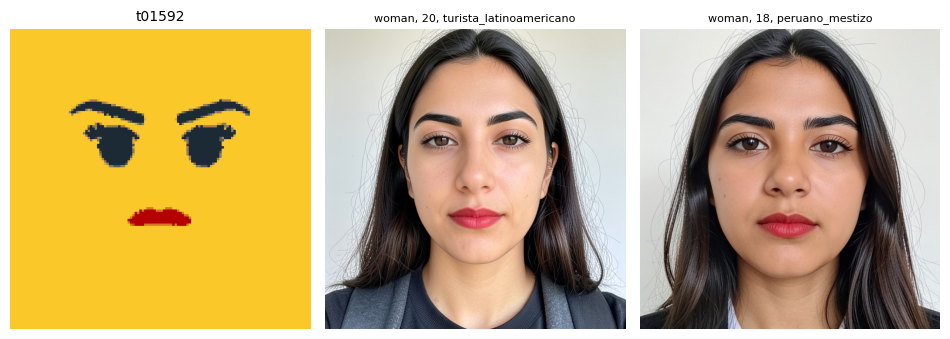

[   3/816] t00943_00 woman, peruano_andino, 22-year-old | 4.5s | lleva 0 min | faltan ~83 min
[   4/816] t00943_01 woman, peruano_mestizo, 25-year-old | 4.4s | lleva 0 min | faltan ~77 min
[   5/816] t01670_00 man, migrante_venezolano_colombiano, 25-year-old | 4.6s | lleva 0 min | faltan ~74 min
[   6/816] t01670_01 man, peruano_mestizo, 55-year-old | 4.6s | lleva 1 min | faltan ~72 min
[   7/816] t02290_00 woman, peruano_mestizo, 18-year-old | 4.7s | lleva 1 min | faltan ~71 min
[   8/816] t02290_01 woman, peruano_mestizo, 20-year-old | 4.7s | lleva 1 min | faltan ~70 min
[   9/816] t01726_00 woman, peruano_mestizo, 30-year-old | 4.7s | lleva 1 min | faltan ~69 min
[  10/816] t01726_01 woman, turista_norteamerica_europa, 18-year-old | 4.8s | lleva 1 min | faltan ~68 min
[  11/816] t00056_00 woman, peruano_mestizo, 18-year-old | 4.9s | lleva 1 min | faltan ~68 min
[  12/816] t00056_01 woman, peruano_andino, 22-year-old | 4.8s | lleva 1 min | faltan ~68 min
[  13/816] t00342_00 woman, m

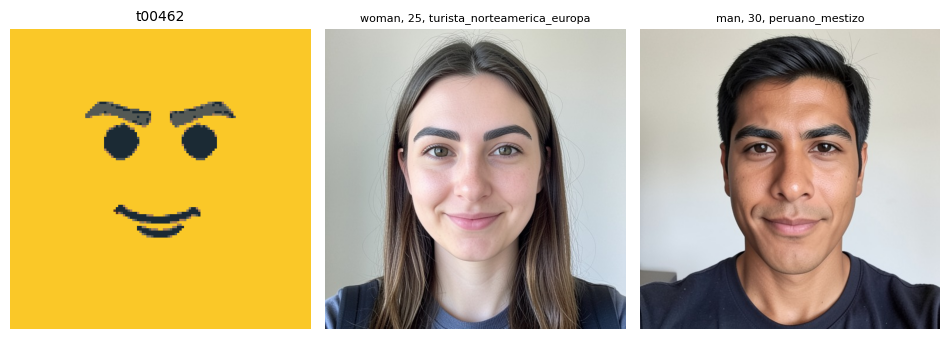

[  53/816] t01054_00 woman, turista_otro, 25-year-old | 5.2s | lleva 5 min | faltan ~66 min
[  54/816] t01054_01 man, migrante_venezolano_colombiano, 20-year-old | 5.2s | lleva 5 min | faltan ~66 min
[  55/816] t02298_00 man, peruano_criollo, 20-year-old | 5.2s | lleva 5 min | faltan ~65 min
[  56/816] t02298_01 man, migrante_venezolano_colombiano, 22-year-old | 5.2s | lleva 5 min | faltan ~65 min
[  57/816] t02028_00 man, peruano_mestizo, 22-year-old | 5.2s | lleva 5 min | faltan ~65 min
[  58/816] t02028_01 woman, turista_otro, 30-year-old | 5.1s | lleva 5 min | faltan ~65 min
[  59/816] t02280_00 man, peruano_mestizo, 25-year-old | 5.1s | lleva 5 min | faltan ~65 min
[  60/816] t02280_01 man, peruano_criollo, 30-year-old | 5.1s | lleva 5 min | faltan ~65 min
[  61/816] t01841_00 woman, peruano_mestizo, 22-year-old | 5.1s | lleva 5 min | faltan ~65 min
[  62/816] t01841_01 man, peruano_mestizo, 18-year-old | 5.1s | lleva 5 min | faltan ~64 min
[  63/816] t02397_00 man, migrante_venez

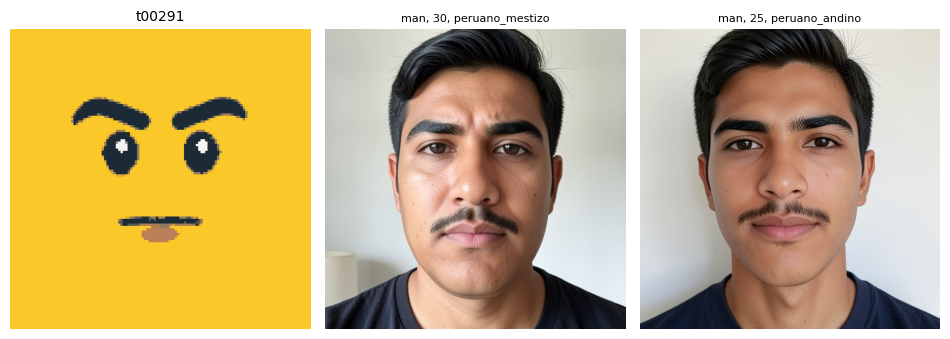

[ 103/816] t00845_00 man, peruano_andino, 20-year-old | 5.2s | lleva 9 min | faltan ~61 min
[ 104/816] t00845_01 woman, peruano_mestizo, 22-year-old | 5.2s | lleva 9 min | faltan ~61 min
[ 105/816] t01065_00 man, turista_latinoamericano, 18-year-old | 5.2s | lleva 9 min | faltan ~61 min
[ 106/816] t01065_01 man, migrante_venezolano_colombiano, 40-year-old | 5.1s | lleva 9 min | faltan ~61 min
[ 107/816] t00568_00 woman, turista_latinoamericano, 20-year-old | 5.2s | lleva 9 min | faltan ~61 min
[ 108/816] t00568_01 woman, migrante_venezolano_colombiano, 40-year-old | 5.1s | lleva 9 min | faltan ~61 min
[ 109/816] t01820_00 man, peruano_mestizo, 18-year-old | 5.2s | lleva 9 min | faltan ~61 min
[ 110/816] t01820_01 man, peruano_mestizo, 20-year-old | 5.1s | lleva 9 min | faltan ~61 min
[ 111/816] t00344_00 woman, peruano_mestizo, 18-year-old | 5.2s | lleva 10 min | faltan ~60 min
[ 112/816] t00344_01 woman, turista_afro, 30-year-old | 5.1s | lleva 10 min | faltan ~60 min
[ 113/816] t0235

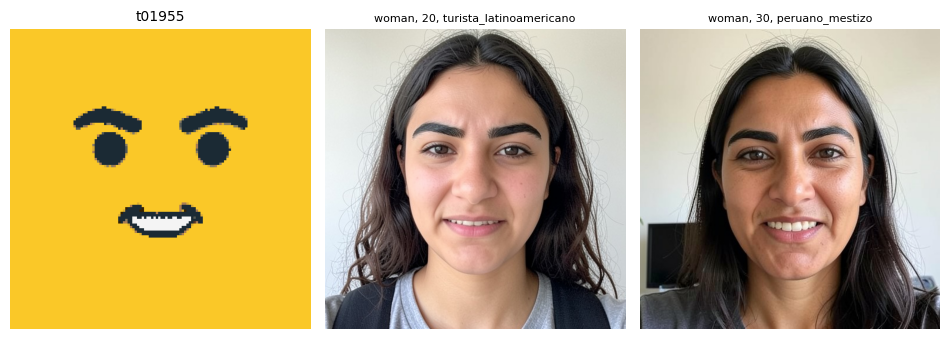

[ 153/816] t00101_00 man, peruano_mestizo, 20-year-old | 5.2s | lleva 13 min | faltan ~57 min
[ 154/816] t00101_01 woman, peruano_mestizo, 22-year-old | 5.1s | lleva 13 min | faltan ~57 min
[ 155/816] t00595_00 woman, turista_norteamerica_europa, 55-year-old | 5.2s | lleva 13 min | faltan ~57 min
[ 156/816] t00595_01 man, peruano_mestizo, 65-year-old | 5.1s | lleva 13 min | faltan ~57 min
[ 157/816] t00335_00 woman, migrante_venezolano_colombiano, 20-year-old | 5.1s | lleva 13 min | faltan ~57 min
[ 158/816] t00335_01 woman, peruano_andino, 30-year-old | 5.1s | lleva 14 min | faltan ~56 min
[ 159/816] t01058_00 woman, turista_otro, 18-year-old | 5.1s | lleva 14 min | faltan ~56 min
[ 160/816] t01058_01 man, peruano_mestizo, 20-year-old | 5.1s | lleva 14 min | faltan ~56 min
[ 161/816] t00877_00 man, turista_asiatico, 55-year-old | 5.2s | lleva 14 min | faltan ~56 min
[ 162/816] t00877_01 man, peruano_mestizo, 18-year-old | 5.1s | lleva 14 min | faltan ~56 min
[ 163/816] t01211_00 man, 

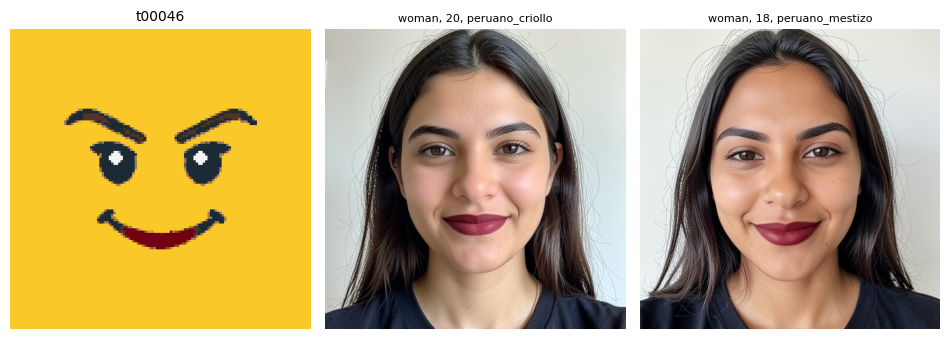

[ 203/816] t00001_00 woman, peruano_mestizo, 22-year-old | 5.2s | lleva 17 min | faltan ~53 min
[ 204/816] t00001_01 woman, migrante_venezolano_colombiano, 20-year-old | 5.2s | lleva 18 min | faltan ~52 min
[ 205/816] t01093_00 woman, migrante_venezolano_colombiano, 18-year-old | 5.2s | lleva 18 min | faltan ~52 min
[ 206/816] t01093_01 man, peruano_mestizo, 30-year-old | 5.1s | lleva 18 min | faltan ~52 min
[ 207/816] t00611_00 man, turista_latinoamericano, 25-year-old | 5.2s | lleva 18 min | faltan ~52 min
[ 208/816] t00611_01 man, turista_norteamerica_europa, 40-year-old | 5.2s | lleva 18 min | faltan ~52 min
[ 209/816] t00641_00 woman, peruano_mestizo, 20-year-old | 5.2s | lleva 18 min | faltan ~52 min
[ 210/816] t00641_01 woman, peruano_mestizo, 30-year-old | 5.1s | lleva 18 min | faltan ~52 min
[ 211/816] t02091_00 man, peruano_mestizo, 20-year-old | 5.2s | lleva 18 min | faltan ~52 min
[ 212/816] t02091_01 man, migrante_venezolano_colombiano, 22-year-old | 5.1s | lleva 18 min | 

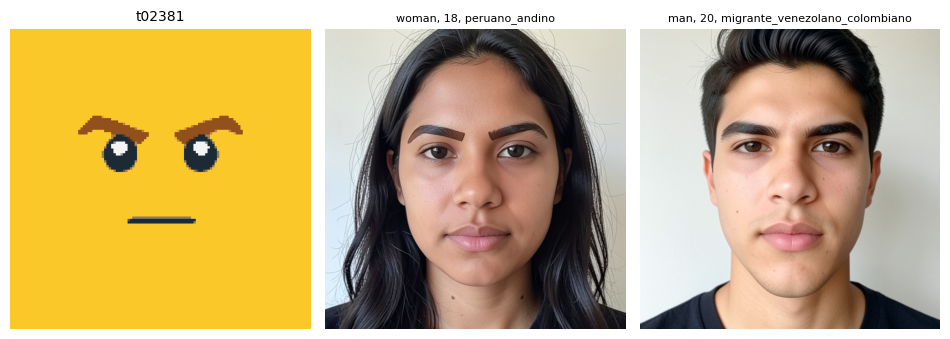

[ 253/816] t01782_00 man, peruano_mestizo, 55-year-old | 5.2s | lleva 22 min | faltan ~48 min
[ 254/816] t01782_01 man, peruano_mestizo, 65-year-old | 5.1s | lleva 22 min | faltan ~48 min
[ 255/816] t00119_00 man, turista_latinoamericano, 18-year-old | 5.2s | lleva 22 min | faltan ~48 min
[ 256/816] t00119_01 woman, peruano_criollo, 18-year-old | 5.1s | lleva 22 min | faltan ~48 min
[ 257/816] t02420_00 woman, turista_afro, 25-year-old | 5.2s | lleva 22 min | faltan ~48 min
[ 258/816] t02420_01 woman, turista_afro, 40-year-old | 5.1s | lleva 22 min | faltan ~48 min
[ 259/816] t02464_00 man, turista_norteamerica_europa, 25-year-old | 5.2s | lleva 22 min | faltan ~48 min
[ 260/816] t02464_01 man, peruano_mestizo, 22-year-old | 5.2s | lleva 22 min | faltan ~48 min
[ 261/816] t00780_00 man, peruano_criollo, 25-year-old | 5.2s | lleva 22 min | faltan ~48 min
[ 262/816] t00780_01 woman, turista_latinoamericano, 22-year-old | 5.1s | lleva 22 min | faltan ~48 min
[ 263/816] t00432_00 man, turi

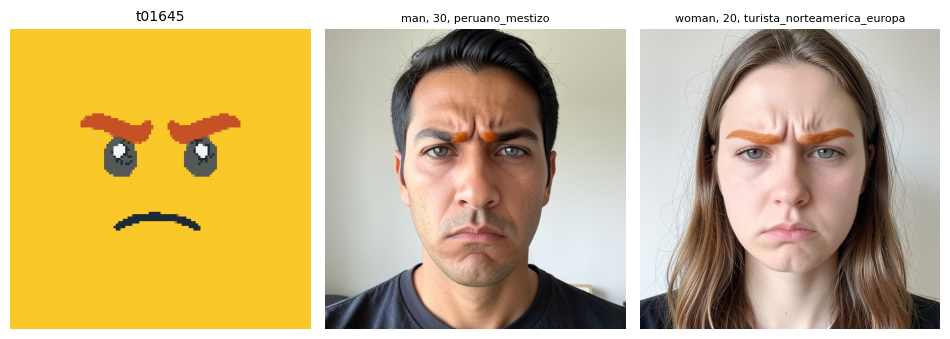

[ 303/816] t02465_00 man, peruano_mestizo, 30-year-old | 5.1s | lleva 26 min | faltan ~44 min
[ 304/816] t02465_01 man, peruano_andino, 25-year-old | 5.1s | lleva 26 min | faltan ~44 min
[ 305/816] t00566_00 man, peruano_mestizo, 22-year-old | 5.1s | lleva 26 min | faltan ~44 min
[ 306/816] t00566_01 woman, peruano_mestizo, 55-year-old | 5.1s | lleva 26 min | faltan ~44 min
[ 307/816] t00860_00 man, turista_asiatico, 25-year-old | 5.1s | lleva 26 min | faltan ~44 min
[ 308/816] t00860_01 woman, peruano_mestizo, 20-year-old | 5.1s | lleva 26 min | faltan ~44 min
[ 309/816] t00133_00 woman, turista_asiatico, 22-year-old | 5.2s | lleva 27 min | faltan ~43 min
[ 310/816] t00133_01 woman, turista_afro, 22-year-old | 5.2s | lleva 27 min | faltan ~43 min
[ 311/816] t00075_00 man, peruano_mestizo, 22-year-old | 5.2s | lleva 27 min | faltan ~43 min
[ 312/816] t00075_01 man, peruano_mestizo, 22-year-old | 5.2s | lleva 27 min | faltan ~43 min
[ 313/816] t01390_00 man, migrante_venezolano_colombia

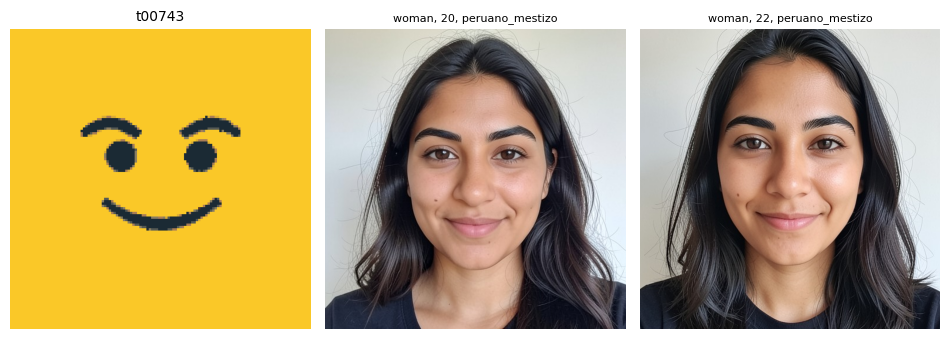

[ 353/816] t01946_00 woman, peruano_criollo, 22-year-old | 5.1s | lleva 30 min | faltan ~40 min
[ 354/816] t01946_01 woman, peruano_mestizo, 25-year-old | 5.1s | lleva 30 min | faltan ~40 min
[ 355/816] t02184_00 man, peruano_criollo, 20-year-old | 5.2s | lleva 30 min | faltan ~40 min
[ 356/816] t02184_01 man, turista_norteamerica_europa, 20-year-old | 5.1s | lleva 31 min | faltan ~39 min
[ 357/816] t01780_00 man, peruano_mestizo, 22-year-old | 5.2s | lleva 31 min | faltan ~39 min
[ 358/816] t01780_01 man, turista_afro, 18-year-old | 5.2s | lleva 31 min | faltan ~39 min
[ 359/816] t00017_00 woman, peruano_mestizo, 22-year-old | 5.2s | lleva 31 min | faltan ~39 min
[ 360/816] t00017_01 woman, peruano_andino, 18-year-old | 5.1s | lleva 31 min | faltan ~39 min
[ 361/816] t01413_00 woman, peruano_mestizo, 22-year-old | 5.3s | lleva 31 min | faltan ~39 min
[ 362/816] t01413_01 woman, peruano_mestizo, 20-year-old | 5.1s | lleva 31 min | faltan ~39 min
[ 363/816] t00833_00 man, peruano_mestiz

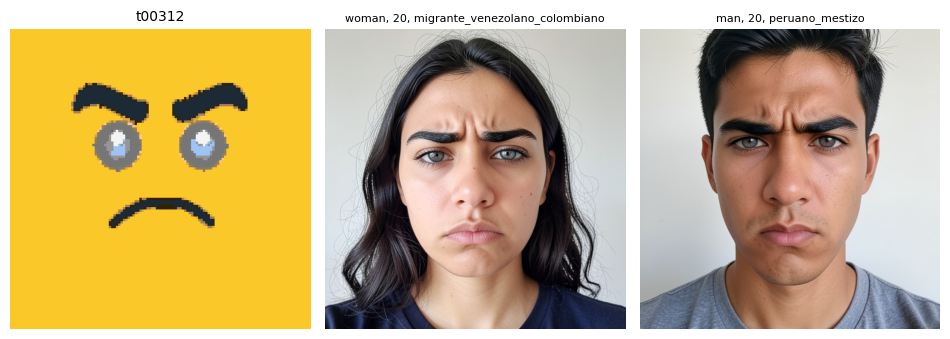

[ 403/816] t01263_00 man, peruano_andino, 25-year-old | 5.1s | lleva 35 min | faltan ~35 min
[ 404/816] t01263_01 man, turista_norteamerica_europa, 25-year-old | 5.1s | lleva 35 min | faltan ~35 min
[ 405/816] t00827_00 woman, turista_norteamerica_europa, 20-year-old | 5.1s | lleva 35 min | faltan ~35 min
[ 406/816] t00827_01 woman, migrante_venezolano_colombiano, 18-year-old | 5.1s | lleva 35 min | faltan ~35 min
[ 407/816] t01747_00 woman, turista_norteamerica_europa, 55-year-old | 5.3s | lleva 35 min | faltan ~35 min
[ 408/816] t01747_01 man, peruano_mestizo, 65-year-old | 5.1s | lleva 35 min | faltan ~35 min
[ 409/816] t00618_00 man, peruano_mestizo, 20-year-old | 5.1s | lleva 35 min | faltan ~35 min
[ 410/816] t00618_01 man, peruano_andino, 20-year-old | 5.1s | lleva 35 min | faltan ~35 min
[ 411/816] t01438_00 woman, peruano_mestizo, 30-year-old | 5.2s | lleva 35 min | faltan ~35 min
[ 412/816] t01438_01 woman, turista_asiatico, 18-year-old | 5.2s | lleva 35 min | faltan ~35 min


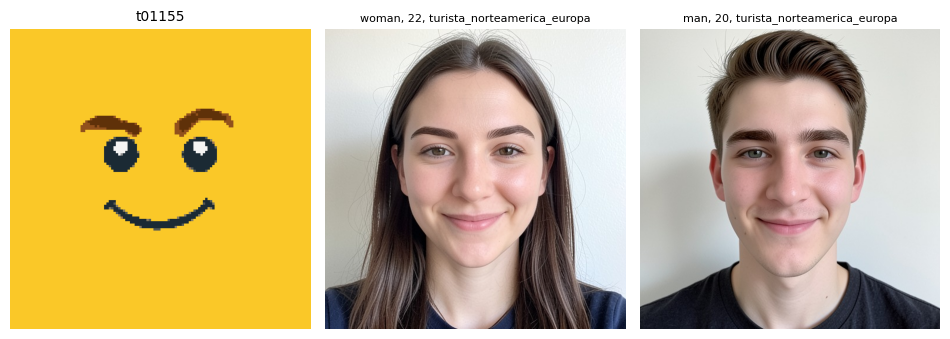

[ 453/816] t00913_00 man, peruano_mestizo, 55-year-old | 5.2s | lleva 39 min | faltan ~31 min
[ 454/816] t00913_01 man, peruano_andino, 65-year-old | 5.1s | lleva 39 min | faltan ~31 min
[ 455/816] t01465_00 woman, peruano_mestizo, 30-year-old | 5.2s | lleva 39 min | faltan ~31 min
[ 456/816] t01465_01 woman, peruano_mestizo, 22-year-old | 5.1s | lleva 39 min | faltan ~31 min
[ 457/816] t01367_00 man, turista_norteamerica_europa, 20-year-old | 5.2s | lleva 39 min | faltan ~31 min
[ 458/816] t01367_01 man, peruano_mestizo, 20-year-old | 5.2s | lleva 39 min | faltan ~31 min
[ 459/816] t00623_00 woman, peruano_mestizo, 20-year-old | 5.2s | lleva 39 min | faltan ~31 min
[ 460/816] t00623_01 woman, peruano_mestizo, 40-year-old | 5.1s | lleva 39 min | faltan ~31 min
[ 461/816] t00077_00 man, peruano_mestizo, 22-year-old | 5.2s | lleva 40 min | faltan ~30 min
[ 462/816] t00077_01 man, turista_latinoamericano, 22-year-old | 5.1s | lleva 40 min | faltan ~30 min
[ 463/816] t02477_00 man, migrant

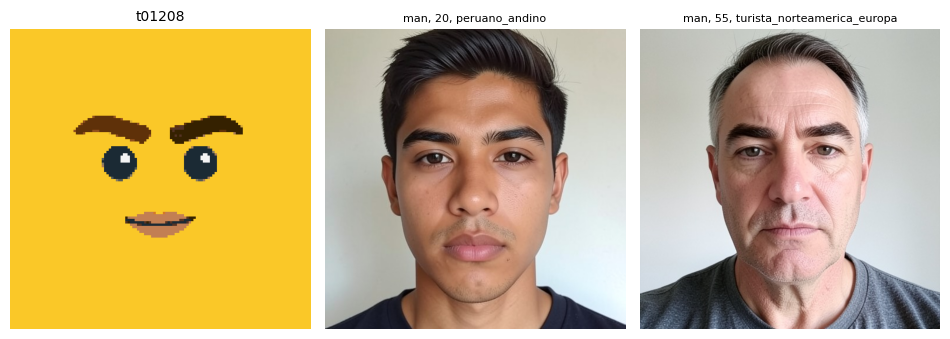

[ 503/816] t00090_00 woman, turista_norteamerica_europa, 25-year-old | 5.2s | lleva 43 min | faltan ~27 min
[ 504/816] t00090_01 woman, peruano_andino, 20-year-old | 5.1s | lleva 43 min | faltan ~27 min
[ 505/816] t00025_00 woman, turista_asiatico, 22-year-old | 5.1s | lleva 43 min | faltan ~27 min
[ 506/816] t00025_01 man, peruano_mestizo, 25-year-old | 5.1s | lleva 43 min | faltan ~27 min
[ 507/816] t00716_00 woman, peruano_mestizo, 20-year-old | 5.1s | lleva 44 min | faltan ~26 min
[ 508/816] t00716_01 woman, peruano_mestizo, 22-year-old | 5.1s | lleva 44 min | faltan ~26 min
[ 509/816] t01637_00 man, peruano_mestizo, 55-year-old | 5.2s | lleva 44 min | faltan ~26 min
[ 510/816] t01637_01 man, turista_norteamerica_europa, 65-year-old | 5.1s | lleva 44 min | faltan ~26 min
[ 511/816] t00196_00 woman, peruano_andino, 22-year-old | 5.2s | lleva 44 min | faltan ~26 min
[ 512/816] t00196_01 woman, peruano_mestizo, 22-year-old | 5.1s | lleva 44 min | faltan ~26 min
[ 513/816] t02232_00 ma

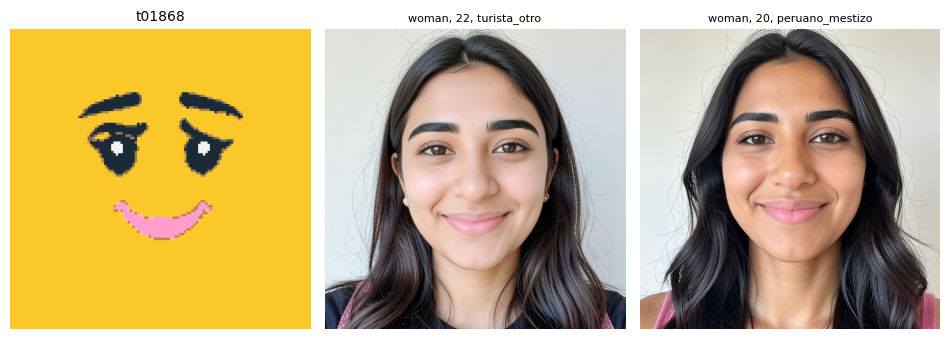

[ 553/816] t01907_00 woman, peruano_mestizo, 20-year-old | 5.2s | lleva 47 min | faltan ~23 min
[ 554/816] t01907_01 woman, peruano_andino, 20-year-old | 5.1s | lleva 48 min | faltan ~22 min
[ 555/816] t00701_00 woman, peruano_andino, 25-year-old | 5.2s | lleva 48 min | faltan ~22 min
[ 556/816] t00701_01 man, migrante_venezolano_colombiano, 20-year-old | 5.1s | lleva 48 min | faltan ~22 min
[ 557/816] t01168_00 woman, turista_asiatico, 30-year-old | 5.2s | lleva 48 min | faltan ~22 min
[ 558/816] t01168_01 woman, peruano_mestizo, 18-year-old | 5.2s | lleva 48 min | faltan ~22 min
[ 559/816] t00781_00 woman, peruano_mestizo, 22-year-old | 5.2s | lleva 48 min | faltan ~22 min
[ 560/816] t00781_01 man, peruano_andino, 22-year-old | 5.2s | lleva 48 min | faltan ~22 min
[ 561/816] t01311_00 woman, peruano_andino, 40-year-old | 5.2s | lleva 48 min | faltan ~22 min
[ 562/816] t01311_01 woman, migrante_venezolano_colombiano, 18-year-old | 5.1s | lleva 48 min | faltan ~22 min
[ 563/816] t00809

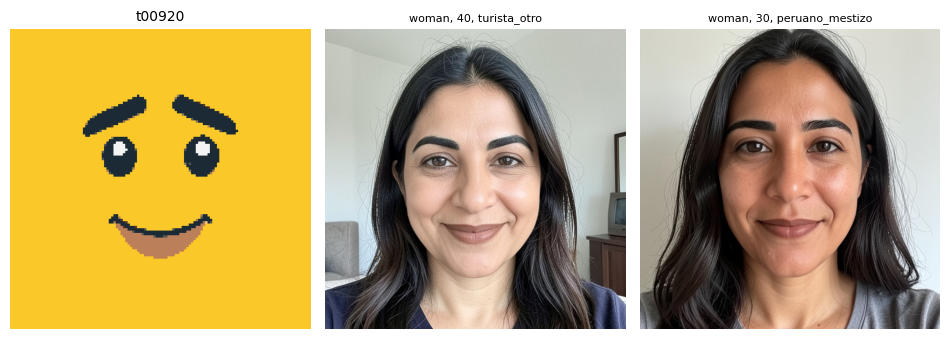

[ 603/816] t01230_00 woman, peruano_mestizo, 22-year-old | 5.2s | lleva 52 min | faltan ~18 min
[ 604/816] t01230_01 woman, turista_afro, 18-year-old | 5.1s | lleva 52 min | faltan ~18 min
[ 605/816] t00607_00 man, migrante_venezolano_colombiano, 18-year-old | 5.2s | lleva 52 min | faltan ~18 min
[ 606/816] t00607_01 man, migrante_venezolano_colombiano, 30-year-old | 5.1s | lleva 52 min | faltan ~18 min
[ 607/816] t01290_00 woman, peruano_mestizo, 20-year-old | 5.1s | lleva 52 min | faltan ~18 min
[ 608/816] t01290_01 woman, turista_norteamerica_europa, 22-year-old | 5.1s | lleva 52 min | faltan ~18 min
[ 609/816] t01055_00 woman, peruano_criollo, 20-year-old | 5.1s | lleva 52 min | faltan ~18 min
[ 610/816] t01055_01 man, peruano_andino, 18-year-old | 5.1s | lleva 52 min | faltan ~18 min
[ 611/816] t01531_00 woman, peruano_mestizo, 18-year-old | 5.2s | lleva 52 min | faltan ~18 min
[ 612/816] t01531_01 woman, peruano_mestizo, 18-year-old | 5.1s | lleva 53 min | faltan ~18 min
[ 613/81

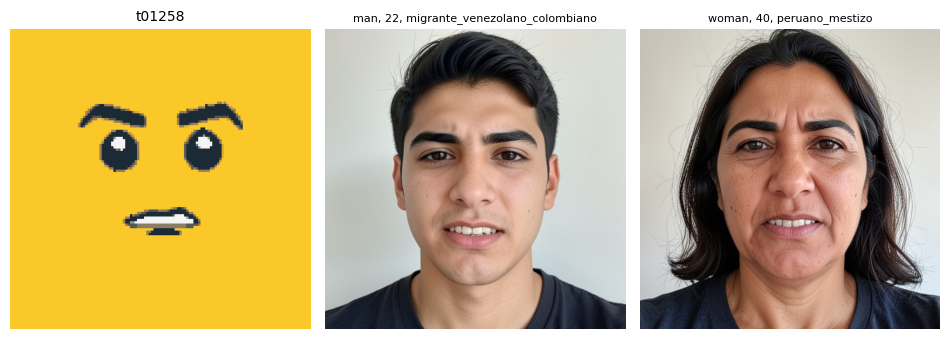

[ 653/816] t01708_00 man, peruano_criollo, 20-year-old | 5.2s | lleva 56 min | faltan ~14 min
[ 654/816] t01708_01 woman, peruano_mestizo, 22-year-old | 5.1s | lleva 56 min | faltan ~14 min
[ 655/816] t00691_00 woman, peruano_mestizo, 20-year-old | 5.2s | lleva 56 min | faltan ~14 min
[ 656/816] t00691_01 man, turista_otro, 22-year-old | 5.1s | lleva 56 min | faltan ~14 min
[ 657/816] t00023_00 woman, peruano_amazonico, 40-year-old | 5.2s | lleva 56 min | faltan ~14 min
[ 658/816] t00023_01 man, peruano_mestizo, 25-year-old | 5.1s | lleva 56 min | faltan ~14 min
[ 659/816] t01647_00 man, turista_latinoamericano, 20-year-old | 5.2s | lleva 57 min | faltan ~13 min
[ 660/816] t01647_01 man, peruano_mestizo, 18-year-old | 5.1s | lleva 57 min | faltan ~13 min
[ 661/816] t01895_00 woman, peruano_mestizo, 22-year-old | 5.2s | lleva 57 min | faltan ~13 min
[ 662/816] t01895_01 woman, peruano_mestizo, 22-year-old | 5.1s | lleva 57 min | faltan ~13 min
[ 663/816] t00886_00 woman, peruano_mestizo

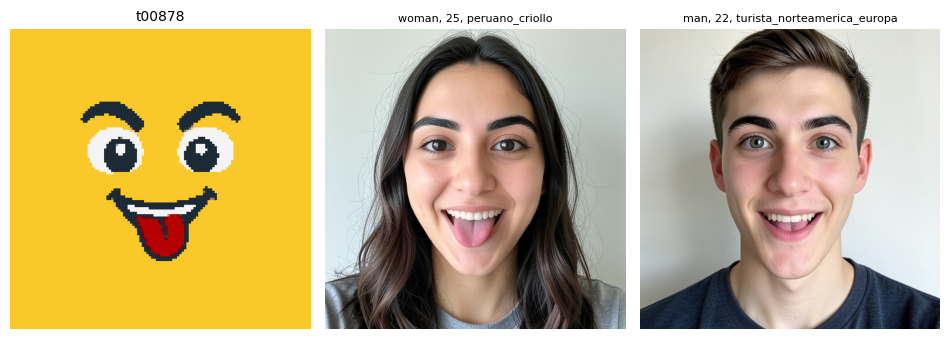

[ 703/816] t00962_00 man, turista_afro, 22-year-old | 5.1s | lleva 60 min | faltan ~10 min
[ 704/816] t00962_01 man, peruano_mestizo, 20-year-old | 5.1s | lleva 60 min | faltan ~10 min
[ 705/816] t01467_00 man, peruano_criollo, 55-year-old | 5.2s | lleva 61 min | faltan ~10 min
[ 706/816] t01467_01 man, afroperuano, 65-year-old | 5.1s | lleva 61 min | faltan ~9 min
[ 707/816] t01217_00 woman, peruano_andino, 25-year-old | 5.2s | lleva 61 min | faltan ~9 min
[ 708/816] t01217_01 man, peruano_mestizo, 18-year-old | 5.2s | lleva 61 min | faltan ~9 min
[ 709/816] t00376_00 man, peruano_mestizo, 40-year-old | 5.2s | lleva 61 min | faltan ~9 min
[ 710/816] t00376_01 woman, turista_latinoamericano, 18-year-old | 5.1s | lleva 61 min | faltan ~9 min
[ 711/816] t01987_00 woman, turista_norteamerica_europa, 22-year-old | 5.1s | lleva 61 min | faltan ~9 min
[ 712/816] t01987_01 woman, peruano_mestizo, 20-year-old | 5.1s | lleva 61 min | faltan ~9 min
[ 713/816] t00916_00 man, peruano_mestizo, 20-y

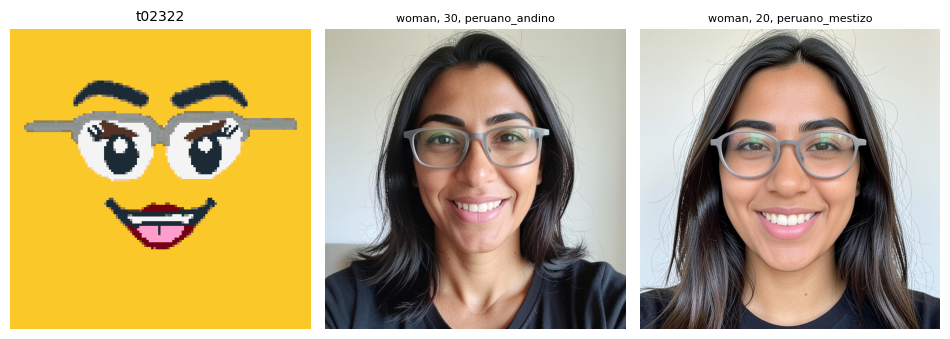

[ 753/816] t01166_00 man, peruano_mestizo, 40-year-old | 5.1s | lleva 65 min | faltan ~5 min
[ 754/816] t01166_01 man, turista_norteamerica_europa, 30-year-old | 5.1s | lleva 65 min | faltan ~5 min
[ 755/816] t02247_00 man, peruano_andino, 25-year-old | 5.2s | lleva 65 min | faltan ~5 min
[ 756/816] t02247_01 man, peruano_mestizo, 20-year-old | 5.1s | lleva 65 min | faltan ~5 min
[ 757/816] t01982_00 man, turista_norteamerica_europa, 18-year-old | 5.2s | lleva 65 min | faltan ~5 min
[ 758/816] t01982_01 man, peruano_mestizo, 22-year-old | 5.1s | lleva 65 min | faltan ~5 min
[ 759/816] t01047_00 woman, migrante_venezolano_colombiano, 18-year-old | 5.2s | lleva 65 min | faltan ~5 min
[ 760/816] t01047_01 woman, peruano_andino, 18-year-old | 5.1s | lleva 65 min | faltan ~5 min
[ 761/816] t01973_00 man, peruano_criollo, 30-year-old | 5.2s | lleva 65 min | faltan ~5 min
[ 762/816] t01973_01 man, peruano_andino, 20-year-old | 5.1s | lleva 65 min | faltan ~5 min
[ 763/816] t01388_00 man, turi

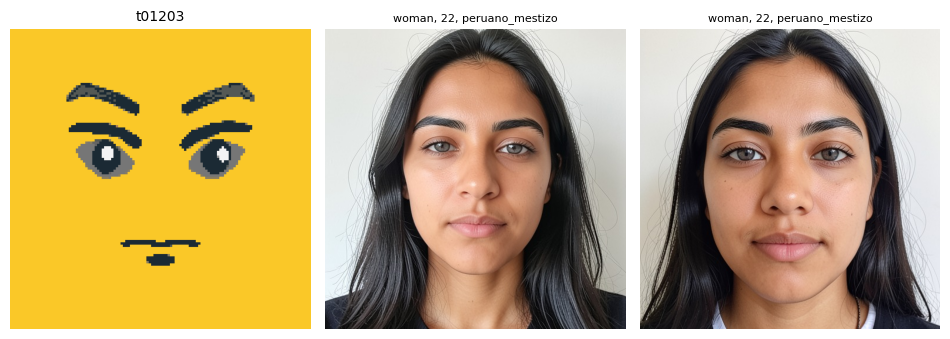

[ 803/816] t00374_00 woman, turista_norteamerica_europa, 25-year-old | 5.2s | lleva 69 min | faltan ~1 min
[ 804/816] t00374_01 man, peruano_andino, 18-year-old | 5.1s | lleva 69 min | faltan ~1 min
[ 805/816] t00057_00 woman, peruano_mestizo, 55-year-old | 5.2s | lleva 69 min | faltan ~1 min
[ 806/816] t00057_01 woman, peruano_mestizo, 20-year-old | 5.2s | lleva 69 min | faltan ~1 min
[ 807/816] t00049_00 woman, turista_norteamerica_europa, 18-year-old | 5.2s | lleva 69 min | faltan ~1 min
[ 808/816] t00049_01 man, peruano_mestizo, 18-year-old | 5.1s | lleva 69 min | faltan ~1 min
[ 809/816] t00815_00 woman, peruano_mestizo, 25-year-old | 5.2s | lleva 69 min | faltan ~1 min
[ 810/816] t00815_01 woman, peruano_mestizo, 30-year-old | 5.2s | lleva 70 min | faltan ~1 min
[ 811/816] t01104_00 woman, turista_afro, 18-year-old | 5.2s | lleva 70 min | faltan ~0 min
[ 812/816] t01104_01 woman, peruano_mestizo, 25-year-old | 5.1s | lleva 70 min | faltan ~0 min
[ 813/816] t00852_00 woman, peruan

In [8]:
def ver(cara_id):
    sub = trabajos[trabajos["cara"] == cara_id]
    fig, ejes = plt.subplots(1, 1 + len(sub), figsize=(3.2 * (1 + len(sub)), 3.4))
    ejes[0].imshow(entrada(cara_id))
    ejes[0].set_title(cara_id, fontsize=10)
    for eje, t in zip(ejes[1:], sub.itertuples()):
        p = SALIDA / t.ruta
        if p.exists():
            eje.imshow(Image.open(p))
        eje.set_title(f"{t.genero}, {t.edad[:2]}, {t.origen}", fontsize=8)
    for eje in ejes:
        eje.axis("off")
    plt.tight_layout()
    plt.show()
    plt.close(fig)


t0 = time.time()
hechas, tiempos = 0, []
pendientes = trabajos[~trabajos["ruta"].map(lambda r: (SALIDA / r).exists())]
print(f"pendientes: {len(pendientes)} de {len(trabajos)}")
for _, t in pendientes.iterrows():
    if (time.time() - t0) / 3600 > CONFIG["LIMITE_HORAS"]:
        registrar_error(f"límite de {CONFIG['LIMITE_HORAS']} h alcanzado: faltan fotos, reanudar (sección 4)")
        break
    ti = time.time()
    try:
        img = pipe(image=entrada(t["cara"]), prompt=t["prompt"], height=CONFIG["LADO_SALIDA"],
                   width=CONFIG["LADO_SALIDA"], num_inference_steps=CONFIG["PASOS"], guidance_scale=CONFIG["GUIA"],
                   generator=torch.Generator("cpu").manual_seed(int(t["semilla"]))).images[0]
    except Exception as e:
        registrar_error(f"{t['id']}: {e!r}")
        continue
    if np.asarray(img).max() < 10:
        registrar_error(f"{t['id']}: imagen negra (¿desborde fp16?)")
    img.save(SALIDA / t["ruta"], quality=92)
    hechas += 1
    tiempos.append(time.time() - ti)
    resto = (len(pendientes) - hechas) * np.mean(tiempos[-20:])
    print(f"[{t['n']:4d}/{len(trabajos)}] {t['id']} {t['genero']}, {t['origen']}, {t['edad']} "
          f"| {tiempos[-1]:.1f}s | lleva {(time.time() - t0) / 60:.0f} min | faltan ~{resto / 60:.0f} min")
    cara_n = (t["n"] - 1) // CONFIG["PERSONAS_POR_CARA"]
    if t["k"] == CONFIG["PERSONAS_POR_CARA"] - 1 and cara_n % CONFIG["VER_CADA"] == 0:
        try:
            ver(t["cara"])
        except Exception as e:
            registrar_error(f"vista {t['cara']}: {e!r}")

## 7. Hojas de revisión y CSV
Cada hoja: 4 caras por fila, cada una con su estampa LEGO y sus 2 personas con su número `n`. En
`revision.csv` pon 1 en `falla` para las fotos que no respetan la cara LEGO.

In [9]:
def hoja(ids, archivo, lado=140, por_fila=4):
    k = 1 + CONFIG["PERSONAS_POR_CARA"]
    filas = -(-len(ids) // por_fila)
    lam = Image.new("RGB", (por_fila * (k * lado + 12), filas * (lado + 20)), "white")
    dib = ImageDraw.Draw(lam)
    for j, cid in enumerate(ids):
        x0, y0 = (j % por_fila) * (k * lado + 12), (j // por_fila) * (lado + 20)
        lam.paste(entrada(cid).resize((lado, lado), Image.NEAREST), (x0, y0 + 16))
        dib.text((x0 + 3, y0 + 2), cid, fill="blue")
        for c, t in enumerate(trabajos[trabajos["cara"] == cid].itertuples(), 1):
            p = SALIDA / t.ruta
            im = Image.open(p).convert("RGB").resize((lado, lado)) if p.exists() else Image.new("RGB", (lado, lado), "gray")
            lam.paste(im, (x0 + c * lado, y0 + 16))
            dib.text((x0 + c * lado + 3, y0 + 2), f"n={t.n}", fill="black")
    lam.save(SALIDA / "hojas" / archivo, quality=88)


ids = list(mias["id"])
for i in range(0, len(ids), 32):
    hoja(ids[i:i + 32], f"hoja_{i // 32 + 1:02d}.jpg")

trabajos["generada"] = trabajos["ruta"].map(lambda r: (SALIDA / r).exists())
trabajos["falla"] = ""                    # llenar a mano: 1 si la foto falla
columnas = ["n", "id", "falla", "cara", "k", "particion", "pieza_a", "pieza_b", "estado_intermedia", "genero",
            "edad", "origen", "generada", "ruta", "ruta_lego", "semilla", "rasgos", "prompt"]
trabajos[columnas].to_csv(SALIDA / "revision.csv", index=False)
resumen = dict(config=CONFIG, modo=MODO, caras=len(mias), fotos=int(trabajos["generada"].sum()),
               faltan=int((~trabajos["generada"]).sum()), minutos=round((time.time() - t0) / 60, 1),
               seg_por_foto=round(float(np.mean(tiempos)), 1) if tiempos else None,
               hojas=len(list((SALIDA / "hojas").glob("*.jpg"))))
json.dump(resumen, open(SALIDA / "resumen.json", "w"), indent=2, ensure_ascii=False, default=str)
print(json.dumps(resumen, indent=2, ensure_ascii=False, default=str))

{
  "config": {
    "PERSONA": 1,
    "N_PERSONAS": 5,
    "SEMILLA": 42,
    "VERSION": "gi",
    "ESTADOS": [
      "pasa",
      "dudosa"
    ],
    "MODELO": "black-forest-labs/FLUX.2-klein-4B",
    "PERSONAS_POR_CARA": 2,
    "LADO_ENTRADA": 512,
    "LADO_SALIDA": 512,
    "PASOS": 4,
    "GUIA": 1.0,
    "VER_CADA": 25,
    "LIMITE_HORAS": 11.3
  },
  "modo": "2 GPUs (balanced)",
  "caras": 408,
  "fotos": 816,
  "faltan": 0,
  "minutos": 70.1,
  "seg_por_foto": 5.1,
  "hojas": 13
}


## 8. Comprimir

In [10]:
zip_final = shutil.make_archive(str(SALIDA), "zip", SALIDA.parent, NOMBRE)
print(f"listo: {zip_final} ({os.path.getsize(zip_final) / 1e6:.1f} MB)")

listo: /kaggle/working/personas_int_persona1.zip (57.9 MB)
